# Proyecto final: pronóstico semanal de dengue

Buscamos pronosticar los casos de dengue de la semana **t+4** en cinco municipios del Valle del Cauca, comparando historias de **12, 16 y 20 semanas**.

Los puntos 1 al 12 preparan los datos y las transformaciones. El punto 13 construye las secuencias. En el 14 entrenamos los baselines y en el 15 revisamos su validación. Los puntos 16 y 17 definen y entrenan las redes LSTM y GRU; después comparamos los resultados y discutimos el candidato. La evaluación final y la exportación del modelo elegido están en el punto 20, después de cerrar la selección con validación.

Cada ejecución entrena los modelos desde cero en este notebook. Las tablas y figuras se calculan después de sus entrenamientos, con los datos de la sesión. La discusión y las conclusiones están escritas en Markdown a partir de esos resultados. Los archivos que se guardan son una salida de esta corrida, no un requisito para iniciarla.

Entrenamiento comprende 2007–2021 y validación, 2022–2023. El periodo 2024–2025 ya se consultó en etapas anteriores; se mantiene separado del desarrollo actual y una evaluación posterior sobre él deberá reconocer ese antecedente.

Para retomar desde los conjuntos limpios, ejecutamos los puntos 1, 2 y 9.2 y continuamos desde el 10. Usamos el entorno `.venv` del proyecto y rutas relativas.


## 1. Preparar el entorno

Definimos la carpeta del proyecto y el entorno de Python que vamos a usar. Estas rutas son relativas y no se muestran en la salida.

La comprobación del entorno se realiza al final del punto 2, después de importar las librerías necesarias.


In [2]:
# Configuración inicial: rutas relativas a la raíz del proyecto.
CARPETA_PROYECTO = '.'
CARPETA_ENTORNO = '.venv'


## 2. Librerías del proyecto

Aquí reunimos los imports del notebook y las dependencias de sus módulos de apoyo, agrupados por uso. Las celdas siguientes utilizan estas librerías sin volver a importarlas.

Los módulos `.py` conservan sus imports internos para poder ejecutarse por separado. Las dependencias están registradas en `requirements.txt` y las versiones instaladas, en `requirements-lock.txt`. Para instalar una librería adicional desde el notebook podemos usar `%pip install nombre_libreria`.


In [3]:
# Biblioteca estándar
import csv
import gc
import hashlib
import importlib.metadata
import json
import math
import os
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter
from uuid import uuid4

# Lectura, procesamiento y almacenamiento de datos
import joblib
import numpy as np
import pandas as pd
import python_calamine

# Gráficas y presentación de resultados
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from matplotlib.ticker import FuncFormatter, MaxNLocator

# Transformaciones y modelos
import tensorflow as tf
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Lectura de los archivos anuales del proyecto
from datos_dengue import (
    COLUMNAS_CASOS,
    DEPARTAMENTO,
    codigo_departamento,
    leer_archivo_dengue,
    ruta_archivo_dengue,
)

# Funciones para preparar secuencias, comparar resultados y exportar modelos

if 'modelado_notebook' in sys.modules:
    importlib.reload(sys.modules['modelado_notebook'])
from modelado_notebook import (
    HISTORIAS, HORIZONTE, RECETAS, CONFIG_XGB,
    construir_secuencias, catalogo_redes, nueva_ejecucion,
    datos_municipales, crear_red, dataset_red, predecir_red_actual, invertir,
    tabla_predicciones, resumir_predicciones, graficar_baselines,
    resumir_validacion, graficar_desarrollo,
    exportar_resultados_actuales, evaluar_al_cierre, graficar_al_cierre,
)

if 'analisis_validacion' in sys.modules:
    importlib.reload(sys.modules['analisis_validacion'])
from analisis_validacion import (
    preparar_analisis_validacion, graficar_comparacion_municipal, graficar_series_candidato, guardar_analisis_validacion,
)

# Comprobar la configuración definida en el punto 1.
PROYECTO = Path(CARPETA_PROYECTO)
assert (PROYECTO / 'DataRaw').is_dir(), 'Abre Jupyter desde la carpeta ProyectoFinal.'
assert Path(sys.prefix).resolve() == (PROYECTO / CARPETA_ENTORNO).resolve(), 'Selecciona el kernel Python (ProyectoFinal).'
print(f'Python: {sys.version.split()[0]}')


Python: 3.13.3


## 3. Revisar los archivos de dengue

Trabajamos con los CSV anuales de `DataRaw`, con nombres como `Datos_AAAA_210.csv`. Contienen únicamente los registros del Valle del Cauca y las cinco columnas que usa el proyecto: `COD_DPTO_O`, `COD_MUN_O`, `SEMANA`, `ANO` e `INI_SIN`.

Los Excel completos de los 19 años se conservan en `DataRawOriginal`. La reducción mantiene todos los municipios del departamento, las fechas faltantes y las filas repetidas; la limpieza y la elección de municipios siguen en los pasos posteriores.

La siguiente celda revisa los archivos de 2007–2025. La primera lectura utiliza 2007–2023; los años 2024–2025 se preparan por separado. La función de lectura prefiere los CSV y también admite Excel si se necesita trabajar con ese formato.


In [4]:
DATOS_RAW = PROYECTO / 'DataRaw'

ANOS = range(2007, 2026)
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)
COLUMNAS = COLUMNAS_CASOS.copy()
archivos_dengue = [ruta_archivo_dengue(ano, DATOS_RAW) for ano in ANOS]

print(f'Archivos encontrados: {len(archivos_dengue)} (2007–2025). Departamento: {DEPARTAMENTO}.')
print('Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.')
pd.DataFrame({
    'ANO_ARCHIVO': list(ANOS),
    'ARCHIVO': [archivo.name for archivo in archivos_dengue],
    'TAMANO_MB': [round(archivo.stat().st_size / 1024**2, 2) for archivo in archivos_dengue],
})


Archivos encontrados: 19 (2007–2025). Departamento: 76.
Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.


,ANO_ARCHIVO,ARCHIVO,TAMANO_MB
0,2007,Datos_2007_210.csv,0.02
1,2008,Datos_2008_210.csv,0.08
2,2009,Datos_2009_210.csv,0.40
3,2010,Datos_2010_210.csv,0.76
4,2011,Datos_2011_210.csv,0.10
5,2012,Datos_2012_210.csv,0.12
6,2013,Datos_2013_210.csv,0.87
7,2014,Datos_2014_210.csv,0.41
8,2015,Datos_2015_210.csv,0.79
9,2016,Datos_2016_210.csv,1.02


## 4. Leer y unir los registros de 2007–2023

Leemos los archivos reducidos del Valle del Cauca de 2007–2023 y los reunimos en `df_dengue`. Antes de unirlos, excluimos las filas sin fecha de inicio de síntomas (`INI_SIN`), siguiendo el criterio de limpieza del proyecto. Las filas con campos coincidentes se mantienen.

Los códigos de departamento y municipio se guardan como texto para conservar los ceros iniciales. `ANO` y `SEMANA` se leen como enteros y `INI_SIN` conserva el texto del archivo. El conteo posterior utiliza el año y la semana registrados; no recalculamos la semana a partir de la fecha de síntomas.

Los mensajes de carga muestran cuántas filas se leyeron, cuántas se descartaron y cuántas quedaron en cada archivo.


In [5]:
inicio = perf_counter()
partes = []
resumen_archivos = []
print('Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.', flush=True)

for ano_archivo, archivo in zip(ANOS, archivos_dengue):
    if ano_archivo not in ANOS_ANALISIS:
        continue  # No abrir los archivos reservados para test (2024 y 2025).
    print(f'Leyendo {archivo.name}...', flush=True)
    try:
        datos_ano = leer_archivo_dengue(archivo, COLUMNAS)
        datos_ano = datos_ano.loc[
            codigo_departamento(datos_ano['COD_DPTO_O']).eq(DEPARTAMENTO).fillna(False)
        ].copy()
        # Unificar nulos, textos vacíos y espacios antes de contar las exclusiones.
        datos_ano['INI_SIN'] = datos_ano['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        casos_originales = len(datos_ano)
        eliminados_ini_sin = int(datos_ano['INI_SIN'].isna().sum())
        datos_ano = datos_ano.dropna(subset=['INI_SIN']).reset_index(drop=True)
        for columna in ['SEMANA', 'ANO']:
            datos_ano[columna] = pd.to_numeric(datos_ano[columna], errors='raise').astype('Int64')
    except Exception as error:
        raise RuntimeError(f'No se pudo cargar {archivo.name}: {error}') from error

    resumen_archivos.append({
        'ANO_ARCHIVO': ano_archivo,
        'ARCHIVO': archivo.name,
        'CASOS_ORIGINALES': casos_originales,
        'FILAS_ELIMINADAS_INI_SIN': eliminados_ini_sin,
        'CASOS': len(datos_ano),
        'ANO_FALTANTE': int(datos_ano['ANO'].isna().sum()),
        'ANO_DISTINTO_AL_ARCHIVO': int(datos_ano['ANO'].ne(ano_archivo).fillna(False).sum()),
    })
    partes.append(datos_ano)
    print(f'  {len(datos_ano):,} casos conservados; {eliminados_ini_sin:,} filas eliminadas.', flush=True)

df_dengue = pd.concat(partes, ignore_index=True).loc[:, COLUMNAS]
resumen_carga = pd.DataFrame(resumen_archivos)
filas_antes_limpieza = int(resumen_carga['CASOS_ORIGINALES'].sum())
filas_eliminadas = int(resumen_carga['FILAS_ELIMINADAS_INI_SIN'].sum())
assert len(df_dengue) == resumen_carga['CASOS'].sum(), 'El total unido no coincide con los archivos.'
assert len(df_dengue) == filas_antes_limpieza - filas_eliminadas
assert df_dengue['INI_SIN'].notna().all(), 'El DataFrame final contiene INI_SIN faltantes.'
assert df_dengue['ANO'].isin(ANOS_ANALISIS).all(), 'La carga de desarrollo contiene datos fuera de 2007-2023.'
del partes, datos_ano

print(f'\nFilas eliminadas por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Total limpio: {len(df_dengue):,} casos y {df_dengue.shape[1]} columnas.')
print(f'Tiempo de carga: {perf_counter() - inicio:.1f} segundos.')
df_dengue.head()

Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.


Leyendo Datos_2007_210.csv...


  577 casos conservados; 0 filas eliminadas.


Leyendo Datos_2008_210.csv...


  1,909 casos conservados; 0 filas eliminadas.


Leyendo Datos_2009_210.csv...


... (27 outputs left out)

Leyendo Datos_2023_210.csv...


  23,983 casos conservados; 0 filas eliminadas.



Filas eliminadas por INI_SIN faltante: 12
Total limpio: 194,409 casos y 5 columnas.
Tiempo de carga: 1.0 segundos.


,COD_DPTO_O,COD_MUN_O,SEMANA,ANO,INI_SIN
0,76,147,26,2007,22/06/2007 12:00:00 a. m.
1,76,109,5,2007,12/01/2007 12:00:00 a. m.
2,76,001,23,2007,31/05/2007 12:00:00 a. m.
3,76,001,16,2007,18/04/2007 12:00:00 a. m.
4,76,036,30,2007,18/07/2007 12:00:00 a. m.


### 4.1. Comprobar las filas sin fecha de inicio de síntomas

La lectura anterior ya excluye las filas sin `INI_SIN`. Esta celda permite aplicar la misma limpieza al DataFrame que esté en memoria, sin volver a leer los archivos anuales. Considera faltantes tanto los valores nulos como los textos vacíos o formados solo por espacios.


In [6]:
# ELIMINAR FILAS SIN INI_SIN DEL DATAFRAME ACTUAL
# Convertir textos vacios o con solo espacios a valores faltantes.
df_dengue['INI_SIN'] = df_dengue['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)

# Eliminar directamente las filas cuyo INI_SIN es faltante.
df_dengue.dropna(subset=['INI_SIN'], inplace=True)
df_dengue.reset_index(drop=True, inplace=True)

print(f"Faltantes en INI_SIN: {df_dengue['INI_SIN'].isna().sum()}")
print(f'Casos restantes: {len(df_dengue):,}')

Faltantes en INI_SIN: 0
Casos restantes: 194,409


## 5. Revisar los datos después de la limpieza

La tabla `resumen_carga` reúne, por archivo, las filas originales, las eliminadas por falta de `INI_SIN` y los casos conservados. También señala si el valor de `ANO` difiere del año indicado en el nombre del archivo. Esos valores originales no se cambian.


In [7]:
resumen_carga

,ANO_ARCHIVO,ARCHIVO,CASOS_ORIGINALES,FILAS_ELIMINADAS_INI_SIN,CASOS,ANO_FALTANTE,ANO_DISTINTO_AL_ARCHIVO
0,2007,Datos_2007_210.csv,577,0,577,0,0
1,2008,Datos_2008_210.csv,1909,0,1909,0,0
2,2009,Datos_2009_210.csv,10139,0,10139,0,0
3,2010,Datos_2010_210.csv,19079,4,19075,0,0
4,2011,Datos_2011_210.csv,2567,1,2566,0,0
5,2012,Datos_2012_210.csv,2985,0,2985,0,0
6,2013,Datos_2013_210.csv,21963,5,21958,0,0
7,2014,Datos_2014_210.csv,10190,0,10190,0,0
8,2015,Datos_2015_210.csv,19818,0,19818,0,0
9,2016,Datos_2016_210.csv,25730,2,25728,0,0


### 5.1. Revisar los valores faltantes

La tabla siguiente muestra los faltantes que quedan en `df_dengue`. Como la limpieza ya se aplicó, `INI_SIN` debe tener cero valores faltantes. Las filas descartadas se contabilizan en `resumen_carga` y ya no forman parte de este DataFrame.


In [8]:
print(f'Filas eliminadas durante la carga por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Casos disponibles para agrupar y analizar: {len(df_dengue):,}')
assert df_dengue['INI_SIN'].notna().all(), 'Ejecuta de nuevo la celda de lectura y limpieza.'
pd.DataFrame({
    'TIPO': df_dengue.dtypes.astype(str),
    'VALORES_FALTANTES_DATOS_LIMPIOS': df_dengue.isna().sum(),
})

Filas eliminadas durante la carga por INI_SIN faltante: 12
Casos disponibles para agrupar y analizar: 194,409


,TIPO,VALORES_FALTANTES_DATOS_LIMPIOS
COD_DPTO_O,string,0
COD_MUN_O,string,0
SEMANA,Int64,0
ANO,Int64,0
INI_SIN,string,0


In [9]:
df_dengue.groupby('ANO', dropna=False).size().rename('CASOS').to_frame()

,CASOS
ANO,
2007,577
2008,1909
2009,10139
2010,19075
2011,2566
2012,2985
2013,21958
2014,10190
2015,19818


## 6. Explorar los datos de desarrollo

### 6.1. Separar los periodos de trabajo

Dividimos la serie en orden cronológico:

| Conjunto | Periodo | Uso |
| --- | --- | --- |
| Entrenamiento | 2007–2021 | Ajustar las transformaciones y entrenar los modelos. |
| Validación | 2022–2023 | Comparar historias, arquitecturas y configuraciones. |
| Evaluación o test | 2024–2025 | Revisar el modelo al cerrar la selección. |

`df_analisis` reúne entrenamiento y validación para las tablas y gráficas de esta parte. `df_entrenamiento` y `df_validacion` conservan los periodos separados. Los pasos siguientes preparan también el archivo de evaluación, pero la comparación actual de modelos utiliza únicamente entrenamiento y validación.


In [10]:
# Periodos cronologicos: el test de 2024-2025 permanece reservado.
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)

df_analisis = df_dengue.loc[df_dengue['ANO'].isin(ANOS_ANALISIS)].copy()
df_entrenamiento = df_analisis.loc[df_analisis['ANO'].isin(ANOS_ENTRENAMIENTO)].copy()
df_validacion = df_analisis.loc[df_analisis['ANO'].isin(ANOS_VALIDACION)].copy()

assert not df_analisis.empty, 'No hay datos de 2007-2023 para analizar.'
assert df_analisis['ANO'].le(2023).all(), 'El analisis contiene datos de test.'
assert len(df_entrenamiento) + len(df_validacion) == len(df_analisis)
print('Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.')
pd.DataFrame({
    'CONJUNTO': ['Entrenamiento', 'Validacion'],
    'PERIODO': ['2007-2021', '2022-2023'],
    'CASOS': [len(df_entrenamiento), len(df_validacion)],
})

Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.


,CONJUNTO,PERIODO,CASOS
0,Entrenamiento,2007-2021,166210
1,Validacion,2022-2023,28199


### 6.2. Observar la evolución anual del Valle del Cauca

Contamos los registros de `df_analisis` por año durante 2007–2023. Como `DataRaw` ya contiene únicamente el departamento 76, la gráfica muestra solo Valle del Cauca. Las combinaciones sin registros aparecen con cero.


In [11]:
# Contar los casos por departamento y año.
assert df_analisis['INI_SIN'].notna().all(), 'Ejecuta primero la celda de limpieza de INI_SIN.'
casos_departamento_ano = (
    df_analisis.groupby(['COD_DPTO_O', 'ANO'], dropna=False)
    .size()
    .unstack('ANO', fill_value=0)
    .reindex(columns=ANOS_ANALISIS, fill_value=0)
    .sort_index()
)
casos_departamento_ano.index.name = 'COD_DPTO_O'
casos_departamento_ano.columns.name = 'ANO'
casos_departamento_ano

ANO,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
COD_DPTO_O,,,,,,,,,,,,,,,,,
76,577,1909,10139,19075,2566,2985,21958,10190,19818,25728,4859,2284,7378,28300,8444,4216,23983


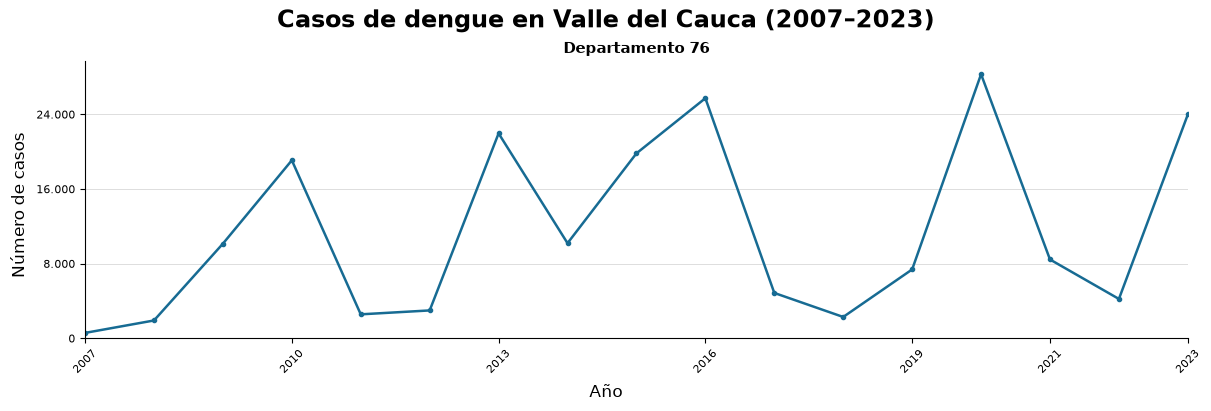

In [12]:
if casos_departamento_ano.empty:
    raise ValueError('No hay casos disponibles para graficar.')

departamentos = casos_departamento_ano.index.tolist()
anos_grafica = casos_departamento_ano.columns.to_numpy(dtype=int)
n_columnas = min(4, len(departamentos))
n_filas = math.ceil(len(departamentos) / n_columnas)
fig, ejes = plt.subplots(
    n_filas, n_columnas,
    figsize=(12 if n_columnas == 1 else 16, (4 if n_columnas == 1 else 2.8) * n_filas),
    squeeze=False,
    layout='constrained',
)
formato_casos = FuncFormatter(lambda valor, _: f'{valor:,.0f}'.replace(',', '.'))

for eje, departamento in zip(ejes.flat, departamentos):
    serie = casos_departamento_ano.loc[departamento]
    eje.plot(anos_grafica, serie.to_numpy(), color='#176B93', marker='o', markersize=3, linewidth=1.8)
    eje.set_title(f'Departamento {departamento}', fontsize=11, fontweight='bold')
    eje.set_xlim(2007, 2023)
    eje.set_ylim(bottom=0)
    eje.set_xticks([2007, 2010, 2013, 2016, 2019, 2021, 2023])
    eje.tick_params(axis='x', labelrotation=45, labelsize=8)
    eje.tick_params(axis='y', labelsize=8)
    eje.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    eje.yaxis.set_major_formatter(formato_casos)
    eje.grid(axis='y', color='#DDDDDD', linewidth=0.7)
    eje.spines[['top', 'right']].set_visible(False)

for eje in list(ejes.flat)[len(departamentos):]:
    eje.set_visible(False)

fig.suptitle('Casos de dengue en Valle del Cauca (2007–2023)', fontsize=17, fontweight='bold')
fig.supxlabel('Año', fontsize=12)
fig.supylabel('Número de casos', fontsize=12)
plt.show()

### 6.3. Departamento de trabajo: Valle del Cauca

El departamento elegido para el proyecto es **Valle del Cauca, código 76**. Los archivos de trabajo ya están filtrados a ese departamento. La gráfica anterior describe su evolución; con esta versión reducida no comparamos el volumen de casos entre departamentos.


## 7. Asignar los nombres de los municipios

Usamos `MunicipiosValledelCauca.csv` para agregar el nombre del municipio a los registros del departamento 76. Los códigos se conservan como texto: por ejemplo, `001` corresponde a Cali y no debe convertirse en `1`. El valor `="001"` del catálogo se interpreta como el texto `001`.

Aplicamos el mismo catálogo a los tres periodos. En esta primera revisión mantenemos las filas cuyo código no encuentra correspondencia y contamos cuántas hay en cada conjunto. El punto 8 las elimina de las tablas de trabajo.

La columna `COD_MUN_O_ORIGINAL` guarda el código tal como se leyó. Los archivos originales se mantienen sin cambios.


In [13]:
# Leer el catálogo como texto: nunca convertir los códigos a enteros.
catalogo_municipios = pd.read_csv(
    PROYECTO / 'MunicipiosValledelCauca.csv',
    sep=',', encoding='utf-8-sig', dtype='string', keep_default_na=False,
)

def normalizar_codigo_texto(serie, ancho):
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .replace('', pd.NA)
        .str.zfill(ancho)
    )

catalogo_municipios['CODIGO_DEPARTAMENTO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_DEPARTAMENTO'], 2
)
catalogo_municipios['CODIGO_MUNICIPIO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_MUNICIPIO'], 3
)
catalogo_municipios['MUNICIPIO'] = catalogo_municipios['MUNICIPIO'].str.strip()
catalogo_valle = catalogo_municipios.loc[
    catalogo_municipios['CODIGO_DEPARTAMENTO'].eq('76')
].copy()
assert not catalogo_valle.empty, 'El catálogo no contiene municipios del departamento 76.'
assert catalogo_valle['CODIGO_MUNICIPIO'].str.fullmatch(r'\d{3}').fillna(False).all(), 'Hay códigos de municipio inválidos en el CSV.'
assert not catalogo_valle['CODIGO_MUNICIPIO'].duplicated().any(), 'Hay códigos de municipio repetidos en el CSV.'
assert catalogo_valle['MUNICIPIO'].ne('').all(), 'Hay nombres de municipio vacíos en el CSV.'
municipios_por_codigo = catalogo_valle.set_index('CODIGO_MUNICIPIO')['MUNICIPIO']
print(f'Municipios disponibles en el catálogo: {len(catalogo_valle)}')
catalogo_valle[['CODIGO_DEPARTAMENTO', 'CODIGO_MUNICIPIO', 'MUNICIPIO']]

Municipios disponibles en el catálogo: 42


,CODIGO_DEPARTAMENTO,CODIGO_MUNICIPIO,MUNICIPIO
0,76,001,CALI
1,76,020,ALCALA
2,76,036,ANDALUCIA
3,76,041,ANSERMANUEVO
4,76,054,ARGELIA
5,76,100,BOLIVAR
6,76,109,BUENAVENTURA
7,76,111,GUADALAJARA DE BUGA
8,76,113,BUGALAGRANDE
9,76,122,CAICEDONIA


In [14]:
def asignar_municipio_valle(datos):
    resultado = datos.copy()
    if 'COD_MUN_O_ORIGINAL' not in resultado.columns:
        resultado['COD_MUN_O_ORIGINAL'] = resultado['COD_MUN_O'].astype('string')
    resultado['COD_DPTO_O'] = normalizar_codigo_texto(resultado['COD_DPTO_O'], 2)
    resultado['COD_MUN_O'] = normalizar_codigo_texto(resultado['COD_MUN_O'], 3)
    resultado['MUNICIPIO'] = pd.Series(pd.NA, index=resultado.index, dtype='string')
    es_valle = resultado['COD_DPTO_O'].eq('76').fillna(False)
    resultado.loc[es_valle, 'MUNICIPIO'] = resultado.loc[es_valle, 'COD_MUN_O'].map(municipios_por_codigo)
    assert len(resultado) == len(datos), 'La asignación cambió el número de filas.'
    return resultado

# Agregar MUNICIPIO a las filas del departamento 76 en los datos de desarrollo.
df_dengue = asignar_municipio_valle(df_dengue)
df_analisis = asignar_municipio_valle(df_analisis)
df_entrenamiento = asignar_municipio_valle(df_entrenamiento)
df_validacion = asignar_municipio_valle(df_validacion)

df_valle_entrenamiento = df_entrenamiento.loc[df_entrenamiento['COD_DPTO_O'].eq('76')].copy()
df_valle_validacion = df_validacion.loc[df_validacion['COD_DPTO_O'].eq('76')].copy()

# Leer el test solo para asignar municipios y auditar los códigos.
# No incorporar el test a df_analisis ni a las gráficas de desarrollo.
partes_valle_test = []
for ano_test in ANOS_TEST:
    archivo_test = ruta_archivo_dengue(ano_test, DATOS_RAW)
    print(f'Asignando municipios en {archivo_test.name}...', flush=True)
    datos_test = leer_archivo_dengue(archivo_test, COLUMNAS)
    datos_test['INI_SIN'] = datos_test['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
    datos_test = datos_test.dropna(subset=['INI_SIN']).reset_index(drop=True)
    for columna in ['SEMANA', 'ANO']:
        datos_test[columna] = pd.to_numeric(datos_test[columna], errors='raise').astype('Int64')
    datos_test = asignar_municipio_valle(datos_test)
    assert datos_test['ANO'].isin(ANOS_TEST).all(), 'El archivo de test contiene años fuera de 2024-2025.'
    partes_valle_test.append(datos_test.loc[datos_test['COD_DPTO_O'].eq('76')].copy())

df_valle_test = pd.concat(partes_valle_test, ignore_index=True)
del partes_valle_test, datos_test

conjuntos_valle = {
    'Entrenamiento': df_valle_entrenamiento,
    'Validación': df_valle_validacion,
    'Test': df_valle_test,
}
# df_valle_todos se usa solo para la auditoría administrativa de códigos.
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)
df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print('Municipios asignados. El test permanece separado del análisis y del entrenamiento.')

Asignando municipios en Datos_2024_210.csv...


Asignando municipios en Datos_2025_210.csv...


Municipios asignados. El test permanece separado del análisis y del entrenamiento.


In [15]:
resumen_municipios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_DEPTO_76': len(datos),
        'FILAS_CON_MUNICIPIO': int(datos['MUNICIPIO'].notna().sum()),
        'FILAS_SIN_MUNICIPIO': int(datos['MUNICIPIO'].isna().sum()),
        'CODIGOS_NO_RECONOCIDOS': datos.loc[datos['MUNICIPIO'].isna(), 'COD_MUN_O'].nunique(dropna=False),
    }
    for nombre, datos in conjuntos_valle.items()
])
filas_sin_municipio = df_valle_todos.loc[df_valle_todos['MUNICIPIO'].isna()].copy()
codigos_no_correspondientes = (
    filas_sin_municipio.groupby(
        ['CONJUNTO', 'COD_MUN_O_ORIGINAL', 'COD_MUN_O'], dropna=False,
    ).size().rename('FILAS_SIN_MUNICIPIO').reset_index()
)
assert (resumen_municipios['FILAS_CON_MUNICIPIO'] + resumen_municipios['FILAS_SIN_MUNICIPIO']).equals(resumen_municipios['FILAS_DEPTO_76'])
print(f'Antes del paso 8: filas del Valle sin correspondencia en el catálogo: {len(filas_sin_municipio):,}')
print(f'Códigos distintos sin correspondencia: {filas_sin_municipio["COD_MUN_O"].nunique(dropna=False)}')
resumen_municipios

Antes del paso 8: filas del Valle sin correspondencia en el catálogo: 296
Códigos distintos sin correspondencia: 1


,CONJUNTO,FILAS_DEPTO_76,FILAS_CON_MUNICIPIO,FILAS_SIN_MUNICIPIO,CODIGOS_NO_RECONOCIDOS
0,Entrenamiento,166210,165914,296,1
1,Validación,28199,28199,0,0
2,Test,95648,95648,0,0


In [16]:
# Auditoria antes del paso 8: codigos no reconocidos que se eliminan.
codigos_no_correspondientes

,CONJUNTO,COD_MUN_O_ORIGINAL,COD_MUN_O,FILAS_SIN_MUNICIPIO
0,Entrenamiento,000,000,296


## 8. Retirar los registros con municipios no reconocidos

Excluimos las filas sin municipio, con códigos ajenos al catálogo o con nombres que no coinciden con el código asignado. La regla es la misma para entrenamiento, validación y evaluación.

Las filas retiradas quedan en `filas_descartadas_municipios` para poder revisarlas. Las tablas `df_valle_entrenamiento`, `df_valle_validacion` y `df_valle_test` se actualizan con los registros válidos; `df_valle_analisis` reúne las dos primeras.

La comprobación final revisa que todos los códigos y nombres restantes correspondan al catálogo.


In [17]:
# ELIMINAR FILAS SIN MUNICIPIO CORRESPONDIENTE O CON CODIGO NO RECONOCIDO.
def mascara_municipio_valido(datos):
    codigo_reconocido = datos['COD_MUN_O'].isin(municipios_por_codigo.index)
    municipio_presente = datos['MUNICIPIO'].notna() & datos['MUNICIPIO'].str.strip().ne('')
    municipio_correspondiente = datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo))
    return (codigo_reconocido & municipio_presente & municipio_correspondiente).fillna(False)

conjuntos_valle_limpios = {}
registros_limpieza = []
partes_descartadas = []
for nombre, datos in conjuntos_valle.items():
    conservar = mascara_municipio_valido(datos)
    limpios = datos.loc[conservar].copy().reset_index(drop=True)
    descartados = datos.loc[~conservar].copy()
    partes_descartadas.append(descartados.assign(CONJUNTO=nombre))
    conjuntos_valle_limpios[nombre] = limpios
    registros_limpieza.append({
        'CONJUNTO': nombre,
        'FILAS_ANTES': len(datos),
        'FILAS_ELIMINADAS': len(descartados),
        'FILAS_LIMPIAS': len(limpios),
    })

# Reemplazar los tres conjuntos de trabajo con los datos válidos.
df_valle_entrenamiento = conjuntos_valle_limpios['Entrenamiento']
df_valle_validacion = conjuntos_valle_limpios['Validación']
df_valle_test = conjuntos_valle_limpios['Test']
conjuntos_valle = conjuntos_valle_limpios
filas_descartadas_municipios = pd.concat(partes_descartadas, ignore_index=True)
del partes_descartadas

df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)

# Retirar también los registros inválidos del Valle de los DataFrames generales.
# La condición de municipio se aplica exclusivamente al departamento 76.
def retirar_municipios_invalidos_del_valle(datos):
    es_valle = datos['COD_DPTO_O'].eq('76').fillna(False)
    conservar = ~es_valle | mascara_municipio_valido(datos)
    return datos.loc[conservar].copy().reset_index(drop=True)

df_dengue = retirar_municipios_invalidos_del_valle(df_dengue)
df_analisis = retirar_municipios_invalidos_del_valle(df_analisis)
df_entrenamiento = retirar_municipios_invalidos_del_valle(df_entrenamiento)
df_validacion = retirar_municipios_invalidos_del_valle(df_validacion)

resumen_limpieza_municipios = pd.DataFrame(registros_limpieza)
assert (resumen_limpieza_municipios['FILAS_ANTES'] - resumen_limpieza_municipios['FILAS_ELIMINADAS']).equals(resumen_limpieza_municipios['FILAS_LIMPIAS'])
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print(f"Filas eliminadas por municipio inválido: {resumen_limpieza_municipios['FILAS_ELIMINADAS'].sum():,}")
resumen_limpieza_municipios

Filas eliminadas por municipio inválido: 296


,CONJUNTO,FILAS_ANTES,FILAS_ELIMINADAS,FILAS_LIMPIAS
0,Entrenamiento,166210,296,165914
1,Validación,28199,0,28199
2,Test,95648,0,95648


In [18]:
verificacion_municipios_limpios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_LIMPIAS': len(datos),
        'MUNICIPIOS_FALTANTES_O_VACIOS': int((datos['MUNICIPIO'].isna() | datos['MUNICIPIO'].str.strip().eq('').fillna(False)).sum()),
        'CODIGOS_NO_RECONOCIDOS': int((~datos['COD_MUN_O'].isin(municipios_por_codigo.index)).sum()),
        'NOMBRES_NO_CORRESPONDIENTES': int((~datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo)).fillna(False)).sum()),
    }
    for nombre, datos in conjuntos_valle.items()
])
columnas_errores = ['MUNICIPIOS_FALTANTES_O_VACIOS', 'CODIGOS_NO_RECONOCIDOS', 'NOMBRES_NO_CORRESPONDIENTES']
assert verificacion_municipios_limpios[columnas_errores].eq(0).all().all(), 'Quedan errores de correspondencia de municipio.'
assert df_valle_entrenamiento['ANO'].between(2007, 2021).all()
assert df_valle_validacion['ANO'].between(2022, 2023).all()
assert df_valle_test['ANO'].between(2024, 2025).all()
print('Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.')
verificacion_municipios_limpios

Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.


,CONJUNTO,FILAS_LIMPIAS,MUNICIPIOS_FALTANTES_O_VACIOS,CODIGOS_NO_RECONOCIDOS,NOMBRES_NO_CORRESPONDIENTES
0,Entrenamiento,165914,0,0,0
1,Validación,28199,0,0,0
2,Test,95648,0,0,0


## 9. Guardar y cargar los conjuntos limpios

Los datos limpios del Valle del Cauca quedan en tres archivos, separados por periodo:

| Archivo | DataFrame | Periodo |
| --- | --- | --- |
| `training.csv` | `df_valle_entrenamiento` | 2007–2021 |
| `validation.csv` | `df_valle_validacion` | 2022–2023 |
| `test.csv` | `df_valle_test` | 2024–2025 |

### 9.1. Guardar los conjuntos

Ejecutamos esta parte después de completar la limpieza del punto 8. Se revisan los periodos y municipios antes de guardar todas las columnas, sin índice y con codificación `utf-8-sig`.

Esta celda actualiza los tres CSV. Si ya existen y solo queremos continuar el análisis, la omitimos y pasamos directamente al punto 9.2.


In [19]:
exportaciones_csv = {
    'training.csv': (df_valle_entrenamiento, 2007, 2021),
    'validation.csv': (df_valle_validacion, 2022, 2023),
    'test.csv': (df_valle_test, 2024, 2025),
}

# Comprobar los tres conjuntos antes de escribir cualquier archivo.
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    assert not datos.empty, f'{nombre_archivo}: el conjunto está vacío.'
    assert datos['ANO'].between(ano_inicio, ano_fin).all(), f'{nombre_archivo}: hay años fuera de su periodo.'
    assert datos['COD_DPTO_O'].eq('76').all(), f'{nombre_archivo}: hay otros departamentos.'
    assert mascara_municipio_valido(datos).all(), f'{nombre_archivo}: hay municipios inválidos.'
    assert datos['INI_SIN'].notna().all(), f'{nombre_archivo}: hay INI_SIN faltantes.'
    for columna in ['COD_DPTO_O', 'COD_MUN_O', 'COD_MUN_O_ORIGINAL']:
        assert isinstance(datos[columna].dtype, pd.StringDtype), f'{nombre_archivo}: {columna} debe ser string.'

registros_exportacion = []
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    ruta_csv = PROYECTO / nombre_archivo
    datos.to_csv(ruta_csv, index=False, encoding='utf-8-sig', quoting=csv.QUOTE_NONNUMERIC)
    registros_exportacion.append({
        'ARCHIVO': nombre_archivo,
        'PERIODO': f'{ano_inicio}-{ano_fin}',
        'FILAS_GUARDADAS': len(datos),
        'COLUMNAS': len(datos.columns),
        'RUTA': str(ruta_csv),
    })
    print(f'Guardado {nombre_archivo}: {len(datos):,} filas.')

resumen_exportacion_csv = pd.DataFrame(registros_exportacion)
resumen_exportacion_csv

Guardado training.csv: 165,914 filas.
Guardado validation.csv: 28,199 filas.


Guardado test.csv: 95,648 filas.


,ARCHIVO,PERIODO,FILAS_GUARDADAS,COLUMNAS,RUTA
0,training.csv,2007-2021,165914,7,training.csv
1,validation.csv,2022-2023,28199,7,validation.csv
2,test.csv,2024-2025,95648,7,test.csv


### 9.2. Cargar los conjuntos guardados

Para retomar el trabajo en otra sesión, ejecutamos los puntos 1 y 2, y después esta celda. No hace falta repetir los puntos 3 al 8 ni el guardado del 9.1. Una vez cargados los datos, podemos continuar desde el punto 10.

La lectura conserva los códigos como texto, incluidos los ceros iniciales. Comprueba las columnas, los periodos y los campos necesarios, sin volver a limpiar ni sobrescribir los archivos. Recupera los mismos nombres de los DataFrames que utilizamos en el resto del notebook.

Entrenamiento y validación se reúnen en `df_valle_analisis`. El conjunto de evaluación se mantiene separado.


In [20]:
# Lectura independiente: solo necesita la configuración y las librerías de 1 y 2.
archivos_conjuntos_limpios = {
    'Entrenamiento': ('training.csv', 2007, 2021),
    'Validación': ('validation.csv', 2022, 2023),
    'Test': ('test.csv', 2024, 2025),
}
tipos_conjuntos_limpios = {
    'COD_DPTO_O': 'string',
    'COD_MUN_O': 'string',
    'SEMANA': 'Int64',
    'ANO': 'Int64',
    'INI_SIN': 'string',
    'COD_MUN_O_ORIGINAL': 'string',
    'MUNICIPIO': 'string',
}
faltantes_conjuntos = [
    archivo for archivo, _, _ in archivos_conjuntos_limpios.values()
    if not (PROYECTO / archivo).is_file()
]
if faltantes_conjuntos:
    raise FileNotFoundError(
        f'Faltan conjuntos limpios: {faltantes_conjuntos}. '
        'Completa la limpieza y ejecuta el punto 9.1 antes de usar esta carga.'
    )

conjuntos_limpios_cargados = {}
registros_carga_conjuntos = []
for nombre, (archivo, inicio, fin) in archivos_conjuntos_limpios.items():
    datos = pd.read_csv(
        PROYECTO / archivo, dtype=tipos_conjuntos_limpios,
        encoding='utf-8-sig', keep_default_na=False, na_values=[''],
    )
    ausentes = sorted(set(tipos_conjuntos_limpios) - set(datos.columns))
    if ausentes:
        raise ValueError(f'{archivo}: faltan columnas: {ausentes}.')
    if datos.empty:
        raise ValueError(f'{archivo}: el conjunto está vacío.')
    if datos[list(tipos_conjuntos_limpios)].isna().any().any():
        raise ValueError(f'{archivo}: hay valores faltantes en las columnas requeridas.')
    if not datos['ANO'].between(inicio, fin).all():
        raise ValueError(f'{archivo}: hay registros fuera del periodo {inicio}–{fin}.')
    if not datos['SEMANA'].between(1, 53).all():
        raise ValueError(f'{archivo}: hay semanas fuera del rango 1–53.')
    if not datos['COD_DPTO_O'].eq(DEPARTAMENTO).all():
        raise ValueError(f'{archivo}: contiene registros de otro departamento.')
    if not datos['COD_MUN_O'].str.fullmatch(r'\d{3}').all():
        raise ValueError(f'{archivo}: los códigos municipales deben tener tres caracteres.')
    if datos[['INI_SIN', 'MUNICIPIO']].apply(lambda c: c.str.strip().eq('')).any().any():
        raise ValueError(f'{archivo}: hay fechas o nombres de municipio vacíos.')
    conjuntos_limpios_cargados[nombre] = datos
    registros_carga_conjuntos.append({
        'CONJUNTO': nombre, 'ARCHIVO': archivo, 'PERIODO': f'{inicio}–{fin}',
        'FILAS': len(datos), 'COLUMNAS': len(datos.columns),
    })

# Actualizar los DataFrames solo después de comprobar los tres archivos.
df_valle_entrenamiento = conjuntos_limpios_cargados['Entrenamiento']
df_valle_validacion = conjuntos_limpios_cargados['Validación']
df_valle_test = conjuntos_limpios_cargados['Test']
conjuntos_valle = conjuntos_limpios_cargados
conjuntos_valle_limpios = conjuntos_limpios_cargados
df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)

# Mantener también los nombres de los datos de desarrollo usados al inicio.
df_entrenamiento = df_valle_entrenamiento.copy()
df_validacion = df_valle_validacion.copy()
df_analisis = df_valle_analisis.copy()
df_dengue = df_valle_analisis.copy()

resumen_carga_conjuntos_limpios = pd.DataFrame(registros_carga_conjuntos)
print('Conjuntos limpios cargados. Puedes continuar desde el punto 10.')
display(resumen_carga_conjuntos_limpios)


Conjuntos limpios cargados. Puedes continuar desde el punto 10.


,CONJUNTO,ARCHIVO,PERIODO,FILAS,COLUMNAS
0,Entrenamiento,training.csv,2007–2021,165914,7
1,Validación,validation.csv,2022–2023,28199,7
2,Test,test.csv,2024–2025,95648,7


## 10. Seleccionar los cinco municipios con más casos

Sumamos los casos de cada municipio entre 2007 y 2023 a partir de `training.csv` y `validation.csv`. Ordenamos los totales de mayor a menor y guardamos los cinco primeros en `top_5_municipios_valle`.

La selección utiliza cantidades acumuladas de casos, no tasas ajustadas por población. Los datos de evaluación no participan en este ranking.


In [21]:
# Leer únicamente entrenamiento y validación, ya limpios en los pasos 8 y 9.
# Para retomar: ejecutar primero 1, 2 y 9.2, y continuar desde esta celda.
ruta_proyecto_ranking = Path('.')
columnas_ranking = ['COD_DPTO_O', 'COD_MUN_O', 'MUNICIPIO', 'ANO', 'INI_SIN']
tipos_ranking = {
    'COD_DPTO_O': 'string',
    'COD_MUN_O': 'string',
    'MUNICIPIO': 'string',
    'ANO': 'Int64',
    'INI_SIN': 'string',
}
partes_ranking = []
for archivo, inicio, fin in [
    ('training.csv', 2007, 2021),
    ('validation.csv', 2022, 2023),
]:
    datos_ranking = pd.read_csv(
        ruta_proyecto_ranking / archivo,
        encoding='utf-8-sig',
        usecols=columnas_ranking,
        dtype=tipos_ranking,
    )
    assert not datos_ranking.empty, f'{archivo}: no contiene casos.'
    assert datos_ranking['ANO'].notna().all() and datos_ranking['ANO'].between(inicio, fin).all(), f'{archivo}: periodo incorrecto.'
    assert datos_ranking['COD_DPTO_O'].eq('76').fillna(False).all(), f'{archivo}: contiene otros departamentos.'
    assert datos_ranking[['COD_MUN_O', 'MUNICIPIO', 'INI_SIN']].notna().all().all(), f'{archivo}: contiene valores faltantes.'
    assert datos_ranking['MUNICIPIO'].str.strip().ne('').all(), f'{archivo}: contiene municipios vacíos.'
    partes_ranking.append(datos_ranking)

df_historico_valle = pd.concat(partes_ranking, ignore_index=True)
casos_historicos_municipio = (
    df_historico_valle.groupby(['COD_MUN_O', 'MUNICIPIO'])
    .size()
    .rename('CASOS')
    .reset_index()
    .sort_values(['CASOS', 'COD_MUN_O'], ascending=[False, True])
    .reset_index(drop=True)
)
assert casos_historicos_municipio['CASOS'].sum() == len(df_historico_valle)

top_5_municipios_valle = casos_historicos_municipio.head(5).copy()
top_5_municipios_valle.insert(0, 'POSICION', range(1, len(top_5_municipios_valle) + 1))
print(f'Valle del Cauca (76), 2007–2023: {len(df_historico_valle):,} casos limpios en total.')
print('Cinco municipios con más casos acumulados. Test 2024–2025 reservado.')
top_5_municipios_valle


Valle del Cauca (76), 2007–2023: 194,113 casos limpios en total.
Cinco municipios con más casos acumulados. Test 2024–2025 reservado.


,POSICION,COD_MUN_O,MUNICIPIO,CASOS
0,1,001,CALI,122040
1,2,520,PALMIRA,17175
2,3,834,TULUA,6771
3,4,892,YUMBO,5695
4,5,111,GUADALAJARA DE BUGA,5411


## 11. Reunir los casos semanales y el clima

Ahora construimos la tabla con la que trabajarán los modelos: una fila por municipio, año y semana epidemiológica, con el número de casos y las condiciones climáticas de esa semana.

Usamos los cinco municipios seleccionados en el punto 10: **Cali, Palmira, Tuluá, Yumbo y Guadalajara de Buga**. Esa selección debe estar disponible en `top_5_municipios_valle` antes de ejecutar esta parte.

La integración sigue estos pasos:

1. Tomamos los conjuntos limpios del punto 9 y seleccionamos los registros de esos municipios. Si no están cargados, el código admite como alternativa los archivos anuales de `DataRaw`, aplicando la limpieza de `INI_SIN`.
2. Contamos las filas por municipio, `ANO` y `SEMANA` para obtener `CASOS`. La semana es la registrada en el archivo; no necesariamente corresponde a la semana de inicio de síntomas. Si dos filas tienen los mismos valores, ambas se cuentan.
3. Reunimos los CSV de `ShapeMunicipios/CLIMA_DENGUE_VALLE`, con precipitación (`PRECIPITACION_MM`) y temperaturas media, máxima y mínima (`TEMP_MEDIA_C`, `TEMP_MAX_C`, `TEMP_MIN_C`). Conservamos también las fechas de cada semana.
4. Unimos los conteos y el clima por municipio, año y semana. Unificamos `ANIO` como `ANO` y `SEMANA` como `SEMANA_EPI`. El código DANE completo combina departamento y municipio: `76` + `001` = `76001` para Cali.
5. Completamos el calendario de cada municipio con las semanas de los archivos climáticos, incluidas las semanas 53. Si una semana no tiene registros de casos, asignamos cero. Si falta una variable climática, la dejamos vacía para detectarla en las comprobaciones posteriores.

Por ejemplo, una fila permite consultar cuántos casos se registraron en Cali durante una semana y cuál fue su precipitación y temperatura. Las series municipales se mantienen separadas: no sumamos ni promediamos el clima de los cinco municipios.


In [22]:
RUTA_SERIES = Path('.')
DEPARTAMENTO_SERIES = '76'
PERIODOS_SERIES = {
    'training': range(2007, 2022),
    'validation': range(2022, 2024),
    'test': range(2024, 2026),
}
ANOS_SERIES = [ano for periodo in PERIODOS_SERIES.values() for ano in periodo]
VARIABLES_CLIMA = ['PRECIPITACION_MM', 'TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
CLAVES_SERIE = ['COD_DANE', 'ANO', 'SEMANA_EPI']

def codigo_serie(serie, ancho):
    # Admitir códigos con ceros iniciales, formato de Excel ="001" o sufijo .0.
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .str.replace(r'\.0+$', '', regex=True)
        .replace('', pd.NA).str.zfill(ancho)
    )

municipios_interes = top_5_municipios_valle[['COD_MUN_O', 'MUNICIPIO']].copy()
municipios_interes['COD_MUN_O'] = codigo_serie(municipios_interes['COD_MUN_O'], 3)
if (len(municipios_interes) != 5
        or municipios_interes['COD_MUN_O'].duplicated().any()
        or not municipios_interes['COD_MUN_O'].str.fullmatch(r'\d{3}').fillna(False).all()):
    raise ValueError('Ejecuta el punto 10: se requieren cinco códigos municipales distintos y válidos.')
municipios_interes['COD_DPTO_O'] = DEPARTAMENTO_SERIES
municipios_interes['COD_DANE'] = DEPARTAMENTO_SERIES + municipios_interes['COD_MUN_O']
municipios_interes = municipios_interes.sort_values('COD_DANE').reset_index(drop=True)

# Revisar todos los insumos antes de leer los archivos anuales.
rutas_clima = {
    ano: RUTA_SERIES / 'ShapeMunicipios' / 'CLIMA_DENGUE_VALLE' / f'CLIMA_VALLE_SIVIGILA_{ano}.csv'
    for ano in ANOS_SERIES
}
conjuntos_casos_disponibles = {
    'training': globals().get('df_valle_entrenamiento'),
    'validation': globals().get('df_valle_validacion'),
    'test': globals().get('df_valle_test'),
}
USAR_CONJUNTOS_LIMPIOS = all(
    isinstance(datos, pd.DataFrame) for datos in conjuntos_casos_disponibles.values()
)
rutas_casos = {} if USAR_CONJUNTOS_LIMPIOS else {
    ano: ruta_archivo_dengue(ano, RUTA_SERIES / 'DataRaw')
    for ano in ANOS_SERIES
}
faltantes_series = [str(ruta) for ruta in [*rutas_clima.values(), *rutas_casos.values()] if not ruta.is_file()]
if faltantes_series:
    raise FileNotFoundError(f'Faltan insumos para preparar las series: {faltantes_series}')

display(municipios_interes[['COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO']])

,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO
0,76,001,76001,CALI
1,76,111,76111,GUADALAJARA DE BUGA
2,76,520,76520,PALMIRA
3,76,834,76834,TULUA
4,76,892,76892,YUMBO


In [23]:
# Una observación climática por municipio, año y semana. No sumar ni promediar
# duplicados: podrían multiplicar los conteos durante la unión.
columnas_clima = ['COD_DANE', 'ANIO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN', *VARIABLES_CLIMA]
partes_clima = []
for ano, ruta in rutas_clima.items():
    clima_ano = pd.read_csv(ruta, usecols=columnas_clima, dtype='string', encoding='utf-8-sig')
    clima_ano['COD_DANE'] = codigo_serie(clima_ano['COD_DANE'], 5)
    clima_ano = clima_ano.loc[clima_ano['COD_DANE'].isin(municipios_interes['COD_DANE'])].copy()
    clima_ano = clima_ano.rename(columns={'ANIO': 'ANO'})
    for columna in ['ANO', 'SEMANA_EPI']:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Int64')
    if clima_ano.empty or not clima_ano['ANO'].eq(ano).fillna(False).all():
        raise ValueError(f'{ruta.name}: año incorrecto o sin clima para los municipios seleccionados.')
    if not clima_ano['SEMANA_EPI'].between(1, 53).fillna(False).all():
        raise ValueError(f'{ruta.name}: semanas epidemiológicas faltantes o fuera de 1–53.')
    for columna in VARIABLES_CLIMA:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Float64')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        clima_ano[columna] = pd.to_datetime(clima_ano[columna], format='%Y-%m-%d', errors='raise')
    partes_clima.append(clima_ano)

df_clima_semanal = pd.concat(partes_clima, ignore_index=True)
del partes_clima, clima_ano
if df_clima_semanal.duplicated(CLAVES_SERIE).any():
    raise ValueError('Hay claves municipio/año/semana repetidas en los insumos de clima.')
if df_clima_semanal[['FECHA_INICIO', 'FECHA_FIN']].isna().any().any():
    raise ValueError('Hay fechas faltantes en el calendario climático.')
if not (df_clima_semanal['FECHA_FIN'] - df_clima_semanal['FECHA_INICIO']).dt.days.eq(6).all():
    raise ValueError('Hay semanas climáticas que no abarcan siete días.')

# Comprobar que cada semana del calendario exista para los cinco municipios
# y que todos compartan las mismas fechas. No generar semanas con calendario ISO.
calendario_series = df_clima_semanal[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']].drop_duplicates()
if calendario_series.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('Las fechas de una misma semana difieren entre municipios.')
calendario_series = calendario_series.sort_values(['ANO', 'SEMANA_EPI']).reset_index(drop=True)
if not calendario_series.groupby('ANO')['SEMANA_EPI'].apply(
    lambda semanas: semanas.tolist() == list(range(1, int(semanas.max()) + 1)) and int(semanas.max()) in (52, 53)
).all():
    raise ValueError('El calendario climático contiene años incompletos o semanas intermedias faltantes.')
if not calendario_series['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
    raise ValueError('Hay huecos o solapamientos entre las fechas de las semanas climáticas.')
claves_esperadas = municipios_interes[['COD_DANE']].merge(
    calendario_series[['ANO', 'SEMANA_EPI']], how='cross',
)
if len(df_clima_semanal) != len(claves_esperadas):
    raise ValueError('Faltan semanas climáticas para alguno de los municipios seleccionados.')
print('Calendario climático verificado para los cinco municipios y todos los años de trabajo.')

Calendario climático verificado para los cinco municipios y todos los años de trabajo.


### 11.1. Contar los casos por semana

Procesamos un año a la vez y contamos los registros por municipio y semana.  el dataframe `resumen_carga_semanal` indica la fuente y los registros seleccionados y contados en entrenamiento y validación.

In [24]:
columnas_casos_series = ['COD_DPTO_O', 'COD_MUN_O', 'ANO', 'SEMANA', 'INI_SIN']

def contar_casos_semanales(anos, nombre_conjunto):
    partes_conteo = []
    registros_carga = []
    for ano in anos:
        if USAR_CONJUNTOS_LIMPIOS:
            origen = conjuntos_casos_disponibles[nombre_conjunto]
            datos = origen.loc[origen['ANO'].eq(ano), columnas_casos_series].copy()
            nombre_fuente = f'conjunto limpio {nombre_conjunto}, año {ano}'
        else:
            ruta = rutas_casos[ano]
            datos = leer_archivo_dengue(ruta, columnas_casos_series)
            nombre_fuente = ruta.name
        print(f'[{nombre_conjunto}] Contando casos de {nombre_fuente}...', flush=True)
        datos['COD_DPTO_O'] = codigo_serie(datos['COD_DPTO_O'], 2)
        datos['COD_MUN_O'] = codigo_serie(datos['COD_MUN_O'], 3)
        datos = datos.loc[
            datos['COD_DPTO_O'].eq(DEPARTAMENTO_SERIES)
            & datos['COD_MUN_O'].isin(municipios_interes['COD_MUN_O'])
        ].copy()
        seleccionados = len(datos)
        datos['INI_SIN'] = datos['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        datos = datos.dropna(subset=['INI_SIN']).copy()
        for columna in ['ANO', 'SEMANA']:
            datos[columna] = pd.to_numeric(datos[columna], errors='raise').astype('Int64')
        if not datos['ANO'].eq(ano).fillna(False).all():
            raise ValueError(f'{nombre_fuente}: hay casos sin ANO o con ANO distinto del archivo. Revisar antes de separar los conjuntos.')
        if not datos['SEMANA'].between(1, 53).fillna(False).all():
            raise ValueError(f'{nombre_fuente}: hay casos sin SEMANA válida. No se pueden agrupar silenciosamente.')
        datos['COD_DANE'] = datos['COD_DPTO_O'] + datos['COD_MUN_O']
        conteos = (
            datos.rename(columns={'SEMANA': 'SEMANA_EPI'})
            .groupby(CLAVES_SERIE).size().rename('CASOS').reset_index()
        )
        assert int(conteos['CASOS'].sum()) == len(datos), 'Se perdieron casos al agrupar.'
        partes_conteo.append(conteos)
        # El test se prepara, pero no se muestran ni almacenan resúmenes exploratorios.
        if nombre_conjunto != 'test':
            registros_carga.append({
                'CONJUNTO': nombre_conjunto, 'ANO': ano,
                'FUENTE': 'Conjunto limpio' if USAR_CONJUNTOS_LIMPIOS else 'Archivo anual',
                'REGISTROS_MUNICIPIOS_INTERES': seleccionados,
                'EXCLUIDOS_SIN_INI_SIN': seleccionados - len(datos),
                'CASOS_CONTADOS': len(datos),
            })
    return pd.concat(partes_conteo, ignore_index=True), registros_carga

conteos_por_conjunto = {}
registros_carga_semanal = []
for conjunto, anos in PERIODOS_SERIES.items():
    conteos_por_conjunto[conjunto], registros = contar_casos_semanales(anos, conjunto)
    registros_carga_semanal.extend(registros)
resumen_carga_semanal = pd.DataFrame(registros_carga_semanal)
display(resumen_carga_semanal)

[training] Contando casos de conjunto limpio training, año 2007...


[training] Contando casos de conjunto limpio training, año 2008...


[training] Contando casos de conjunto limpio training, año 2009...


[training] Contando casos de conjunto limpio training, año 2010...


[training] Contando casos de conjunto limpio training, año 2011...


[training] Contando casos de conjunto limpio training, año 2012...


... (10 outputs left out)

[validation] Contando casos de conjunto limpio validation, año 2023...


[test] Contando casos de conjunto limpio test, año 2024...

[test] Contando casos de conjunto limpio test, año 2025...


,CONJUNTO,ANO,FUENTE,REGISTROS_MUNICIPIOS_INTERES,EXCLUIDOS_SIN_INI_SIN,CASOS_CONTADOS
0,training,2007,Conjunto limpio,325,0,325
1,training,2008,Conjunto limpio,1515,0,1515
2,training,2009,Conjunto limpio,8318,0,8318
3,training,2010,Conjunto limpio,14093,0,14093
4,training,2011,Conjunto limpio,1930,0,1930
5,training,2012,Conjunto limpio,2397,0,2397
6,training,2013,Conjunto limpio,18778,0,18778
7,training,2014,Conjunto limpio,7646,0,7646
8,training,2015,Conjunto limpio,16556,0,16556
9,training,2016,Conjunto limpio,22211,0,22211


In [25]:
def integrar_serie_semanal(conteos, anos, nombre_conjunto):
    clima = df_clima_semanal.loc[df_clima_semanal['ANO'].isin(anos)].copy()
    serie = clima.merge(conteos, on=CLAVES_SERIE, how='outer', validate='one_to_one', indicator=True)
    # Nunca perder casos porque su semana no aparezca en los archivos climáticos.
    if serie['_merge'].eq('right_only').any():
        raise ValueError(f'{nombre_conjunto}: hay claves de casos sin semana climática. Revisar el calendario antes de exportar.')
    serie['CASOS'] = serie['CASOS'].fillna(0).astype('Int64')
    serie = serie.drop(columns='_merge').merge(
        municipios_interes, on='COD_DANE', how='left', validate='many_to_one',
    )
    serie['CLIMA_COMPLETO'] = serie[VARIABLES_CLIMA].notna().all(axis=1)
    serie = serie[[
        'COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
        'FECHA_INICIO', 'FECHA_FIN', 'CASOS', *VARIABLES_CLIMA, 'CLIMA_COMPLETO',
    ]].sort_values(['COD_DANE', 'ANO', 'SEMANA_EPI']).reset_index(drop=True)
    assert serie['CASOS'].sum() == conteos['CASOS'].sum(), 'La unión alteró el total de casos.'
    assert not serie.duplicated(CLAVES_SERIE).any()
    assert serie['ANO'].isin(anos).all()
    return serie

series_por_conjunto = {
    conjunto: integrar_serie_semanal(conteos_por_conjunto[conjunto], anos, conjunto)
    for conjunto, anos in PERIODOS_SERIES.items()
}
df_semanal_entrenamiento = series_por_conjunto['training']
df_semanal_validacion = series_por_conjunto['validation']
df_semanal_test = series_por_conjunto['test']  # Reservado para la evaluación final.
df_semanal_analisis = pd.concat([df_semanal_entrenamiento, df_semanal_validacion], ignore_index=True)
assert df_semanal_analisis['ANO'].between(2007, 2023).all()

# Exportar únicamente cuando los tres conjuntos hayan superado las validaciones.
# Estos archivos semanales no sobrescriben los CSV de casos individuales del punto 9.
CARPETA_SERIES = RUTA_SERIES / 'DatosProcesados'
CARPETA_SERIES.mkdir(parents=True, exist_ok=True)
for conjunto, serie in series_por_conjunto.items():
    serie.to_csv(
        CARPETA_SERIES / f'semanal_{conjunto}.csv',
        index=False, encoding='utf-8-sig', date_format='%Y-%m-%d',
    )
print(f'Series semanales guardadas en: {CARPETA_SERIES}')
print('El test queda preparado en su archivo separado para la evaluación final.')

# Revisar solo desarrollo. Los faltantes climáticos permanecen como nulos.
resumen_series_desarrollo = pd.DataFrame([
    {
        'CONJUNTO': conjunto,
        'FILAS_MUNICIPIO_SEMANA': len(series_por_conjunto[conjunto]),
        'MUNICIPIOS': series_por_conjunto[conjunto]['COD_DANE'].nunique(),
        'CASOS': int(series_por_conjunto[conjunto]['CASOS'].sum()),
        'SEMANAS_SIN_CASOS': int(series_por_conjunto[conjunto]['CASOS'].eq(0).sum()),
        'FILAS_CON_CLIMA_FALTANTE': int((~series_por_conjunto[conjunto]['CLIMA_COMPLETO']).sum()),
    }
    for conjunto in ['training', 'validation']
])
display(resumen_series_desarrollo)
display(df_semanal_analisis.head(10))

Series semanales guardadas en: DatosProcesados
El test queda preparado en su archivo separado para la evaluación final.


,CONJUNTO,FILAS_MUNICIPIO_SEMANA,MUNICIPIOS,CASOS,SEMANAS_SIN_CASOS,FILAS_CON_CLIMA_FALTANTE
0,training,3915,5,134012,524,0
1,validation,520,5,23080,72,0


,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO,ANO,SEMANA_EPI,FECHA_INICIO,FECHA_FIN,CASOS,PRECIPITACION_MM,TEMP_MEDIA_C,TEMP_MAX_C,TEMP_MIN_C,CLIMA_COMPLETO
0,76,001,76001,CALI,2007,1,2006-12-31,2007-01-06,7,17.199012,18.69441,23.29439,14.762953,True
1,76,001,76001,CALI,2007,2,2007-01-07,2007-01-13,0,27.684166,18.86108,22.737327,16.140837,True
2,76,001,76001,CALI,2007,3,2007-01-14,2007-01-20,3,59.40217,18.866276,23.40366,15.808891,True
3,76,001,76001,CALI,2007,4,2007-01-21,2007-01-27,4,41.167944,18.669141,23.24315,15.65037,True
4,76,001,76001,CALI,2007,5,2007-01-28,2007-02-03,0,0.16281,19.287401,24.384016,14.767081,True
5,76,001,76001,CALI,2007,6,2007-02-04,2007-02-10,0,0.0,18.530701,23.619103,13.862981,True
6,76,001,76001,CALI,2007,7,2007-02-11,2007-02-17,1,38.549986,17.914328,23.714893,13.771234,True
7,76,001,76001,CALI,2007,8,2007-02-18,2007-02-24,2,2.135464,17.650191,23.190763,14.119137,True
8,76,001,76001,CALI,2007,9,2007-02-25,2007-03-03,0,0.092534,18.742788,23.394694,14.550974,True
9,76,001,76001,CALI,2007,10,2007-03-04,2007-03-10,2,44.076288,18.35437,22.8874,14.913091,True


Al terminar tenemos tres tablas con el municipio, el año, la semana, sus fechas, los casos y las cuatro variables climáticas:

| DataFrame | Archivo en `DatosProcesados/` | Periodo |
| --- | --- | --- |
| `df_semanal_entrenamiento` | `semanal_training.csv` | 2007–2021 |
| `df_semanal_validacion` | `semanal_validation.csv` | 2022–2023 |
| `df_semanal_test` | `semanal_test.csv` | 2024–2025 |

`df_semanal_analisis` reúne entrenamiento y validación.  Estos archivos semanales se guardan aparte de los registros individuales del punto 9.


## 12. Preparar las variables para los modelos

Reutilizamos las tablas semanales del punto 11. Como los casos, la precipitación y la temperatura tienen magnitudes distintas, transformamos sus valores antes de entrenar. Esto facilita el ajuste de las redes y mantiene una preparación común para la comparación.

Los escaladores se ajustan **solo con entrenamiento, de 2007 a 2021**. Después aplicamos esas mismas transformaciones a validación y evaluación. Así evitamos que la preparación aprenda de los años posteriores.

| Variables | Transformación | Datos usados para ajustar |
| --- | --- | --- |
| `CASOS` | `log1p` y luego `StandardScaler` | Un escalador por municipio, con entrenamiento. |
| Las tres temperaturas | `StandardScaler`, con una media y escala por columna | Entrenamiento de los cinco municipios. |
| `PRECIPITACION_MM` | `log1p` y luego `StandardScaler` | Entrenamiento de los cinco municipios. |
| `SEMANA_EPI` | Seno y coseno, según las 52 o 53 semanas de cada año | Usa el calendario; no necesita ajustar un escalador. |
| Municipio, códigos y fechas | Se conservan | Son identificadores, no variables para estandarizar. |

`log1p(x)` calcula el logaritmo de `1 + x`. Permite trabajar con ceros y comprime las diferencias entre valores pequeños y muy grandes. Los picos siguen presentes, pero tienen menos peso durante el entrenamiento. Después podemos recuperar la escala original para medir los errores en casos.

Cada municipio tiene su propio escalador de casos, de modo que el volumen de Cali no determine la escala de los demás. Para el clima usamos escaladores compartidos. Estandarizar cambia la escala de los valores; no elimina los extremos ni garantiza una distribución normal.

Las columnas originales se conservan y las transformadas se agregan a nuevos DataFrames. Esta sección no rellena faltantes ni elimina filas: si falta un dato necesario, la ejecución se detiene. Las gráficas de las transformaciones utilizan únicamente entrenamiento.

La implementación sigue la documentación de StandardScaler y las recomendaciones de scikit-learn para evitar fugas de información.


In [26]:
ID_LSTM = 'COD_DANE'
OBJETIVO_LSTM = 'CASOS'
TEMPERATURAS_LSTM = ['TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
PRECIPITACION_LSTM = 'PRECIPITACION_MM'
CLIMA_LSTM = [*TEMPERATURAS_LSTM, PRECIPITACION_LSTM]
CLAVES_LSTM = [ID_LSTM, 'ANO', 'SEMANA_EPI']
PERIODOS_LSTM = {'training': (2007, 2021), 'validation': (2022, 2023), 'test': (2024, 2025)}
columnas_requeridas_lstm = [
    'COD_DPTO_O', 'COD_MUN_O', ID_LSTM, 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
    'FECHA_INICIO', 'FECHA_FIN', OBJETIVO_LSTM, *CLIMA_LSTM,
]

# Reutilizar los objetos del punto 11. Tras reiniciar el kernel, leer solo sus
# CSV semanales pequeños: no repetir la carga costosa de los Excel originales.
entradas_lstm = {
    'training': globals().get('df_semanal_entrenamiento'),
    'validation': globals().get('df_semanal_validacion'),
    'test': globals().get('df_semanal_test'),
}
conjuntos_base_lstm = {}
for nombre, entrada in entradas_lstm.items():
    if entrada is None:
        entrada = pd.read_csv(
            Path('DatosProcesados') / f'semanal_{nombre}.csv',
            encoding='utf-8-sig',
            dtype={'COD_DPTO_O': 'string', 'COD_MUN_O': 'string', ID_LSTM: 'string'},
        )
    datos = entrada.copy(deep=True)
    ausentes = sorted(set(columnas_requeridas_lstm) - set(datos.columns))
    if ausentes:
        raise ValueError(f'{nombre}: faltan columnas requeridas: {ausentes}')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        datos[columna] = pd.to_datetime(datos[columna], errors='raise')
    conjuntos_base_lstm[nombre] = datos

faltantes_lstm = pd.DataFrame({
    nombre: datos[columnas_requeridas_lstm].replace(r'^\s*$', pd.NA, regex=True).isna().sum()
    for nombre, datos in conjuntos_base_lstm.items()
})
if faltantes_lstm.to_numpy().any():
    display(faltantes_lstm.loc[faltantes_lstm.any(axis=1)])
    raise ValueError('Hay campos requeridos faltantes. Definir una estrategia explícita antes de estandarizar; no se imputaron ni eliminaron filas.')

orden_municipios_lstm = sorted(conjuntos_base_lstm['training'][ID_LSTM].unique())
if len(orden_municipios_lstm) != 5:
    raise ValueError('Se esperan los cinco municipios seleccionados en el punto 10.')

for nombre, datos in conjuntos_base_lstm.items():
    inicio, fin = PERIODOS_LSTM[nombre]
    if set(datos[ID_LSTM]) != set(orden_municipios_lstm):
        raise ValueError(f'{nombre}: municipios diferentes de los de entrenamiento.')
    if not datos[ID_LSTM].astype('string').str.fullmatch(r'76\d{3}').all():
        raise ValueError(f'{nombre}: COD_DANE debe conservarse como código de cinco caracteres del Valle.')
    if not datos['COD_DPTO_O'].astype('string').eq('76').all():
        raise ValueError(f'{nombre}: contiene datos de otro departamento.')
    if not datos['ANO'].between(inicio, fin).all() or set(datos['ANO']) != set(range(inicio, fin + 1)):
        raise ValueError(f'{nombre}: periodo incompatible con la separación temporal existente.')
    if datos.duplicated(CLAVES_LSTM).any():
        raise ValueError(f'{nombre}: municipio/año/semana duplicados.')
    valores = datos[[OBJETIVO_LSTM, *CLIMA_LSTM, 'ANO', 'SEMANA_EPI']].to_numpy(dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError(f'{nombre}: se encontraron valores no numéricos o infinitos.')
    if (datos[[OBJETIVO_LSTM, PRECIPITACION_LSTM]] < 0).any().any():
        raise ValueError(f'{nombre}: casos o precipitación negativos; log1p no se aplicará.')
    if not np.equal(datos[OBJETIVO_LSTM], np.floor(datos[OBJETIVO_LSTM])).all():
        raise ValueError(f'{nombre}: CASOS debe contener conteos enteros.')
    if not (datos['FECHA_FIN'] - datos['FECHA_INICIO']).dt.days.eq(6).all():
        raise ValueError(f'{nombre}: hay semanas que no abarcan siete días.')
    for municipio, grupo in datos.groupby(ID_LSTM, sort=False):
        if not grupo['FECHA_INICIO'].is_monotonic_increasing:
            raise ValueError(f'{nombre}/{municipio}: orden temporal incorrecto.')
        if not grupo['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
            raise ValueError(f'{nombre}/{municipio}: semanas faltantes o fechas repetidas.')

# Calendario conocido, sin usar los valores de casos ni clima de validación/test.
# Cada año debe contener exactamente 1..52 o 1..53 para todos los municipios.
calendario_lstm = pd.concat([
    datos[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']]
    for datos in conjuntos_base_lstm.values()
], ignore_index=True).drop_duplicates().sort_values(['ANO', 'SEMANA_EPI'])
if calendario_lstm.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('El calendario de una semana no coincide entre municipios.')
semanas_por_ano_lstm = {}
for ano, grupo in calendario_lstm.groupby('ANO'):
    semanas = grupo['SEMANA_EPI'].tolist()
    numero = len(semanas)
    if numero not in (52, 53) or semanas != list(range(1, numero + 1)):
        raise ValueError(f'{ano}: calendario incompleto o incompatible con 52/53 semanas.')
    semanas_por_ano_lstm[int(ano)] = numero
for nombre, datos in conjuntos_base_lstm.items():
    esperado = calendario_lstm.loc[calendario_lstm['ANO'].between(*PERIODOS_LSTM[nombre]), ['ANO', 'SEMANA_EPI']]
    for municipio, grupo in datos.groupby(ID_LSTM):
        if not grupo[['ANO', 'SEMANA_EPI']].reset_index(drop=True).equals(esperado.reset_index(drop=True).astype(grupo[['ANO', 'SEMANA_EPI']].dtypes)):
            raise ValueError(f'{nombre}/{municipio}: no comparte el calendario completo.')
for anterior, siguiente in [('training', 'validation'), ('validation', 'test')]:
    ultima = conjuntos_base_lstm[anterior]['FECHA_INICIO'].max()
    primera = conjuntos_base_lstm[siguiente]['FECHA_INICIO'].min()
    if primera - ultima != pd.Timedelta(days=7):
        raise ValueError('Los conjuntos temporales se solapan o no son consecutivos.')
print('Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.')


Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.


### 12.1. Aplicar y deshacer las transformaciones

Las funciones separan el ajuste con entrenamiento de la transformación de los otros periodos. En las temperaturas, cada columna utiliza su propia media y escala, aunque compartimos el ajuste entre municipios. `CASOS_std` representa tanto los casos históricos de entrada como el valor futuro que queremos pronosticar.

Para volver a casos deshacemos primero la estandarización con `inverse_transform` y después el logaritmo con `expm1`. Por ejemplo, `invertir_casos_lstm(predicciones, '76001')` utiliza el escalador de Cali. Cuando hay predicciones de varios municipios, cada grupo debe recuperar sus valores con el escalador que le corresponde.

La función conserva los decimales y no recorta las predicciones. Por eso, algunas salidas del modelo pueden convertirse en cantidades negativas; se mantienen y se contabilizan al revisar los resultados.


In [27]:
def ajustar_escaladores_lstm(entrenamiento):
    """Ajustar únicamente con la partición de entrenamiento ya validada."""
    inicio, fin = PERIODOS_LSTM['training']
    if entrenamiento.empty or not entrenamiento['ANO'].between(inicio, fin).all():
        raise ValueError('El ajuste requiere exclusivamente entrenamiento de 2007–2021.')
    escaladores_casos = {}
    auditoria = []
    for municipio, grupo in entrenamiento.groupby(ID_LSTM, sort=True):
        escalador = StandardScaler()
        escalador.fit(np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
        escaladores_casos[municipio] = escalador
        auditoria.append({
            'VARIABLE': OBJETIVO_LSTM, 'AMBITO': municipio, 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(grupo), 'ANO_MIN': int(grupo['ANO'].min()), 'ANO_MAX': int(grupo['ANO'].max()),
        })
    escaladores_clima = {
        'temperaturas': StandardScaler().fit(entrenamiento[TEMPERATURAS_LSTM].to_numpy(dtype=float)),
        'precipitacion': StandardScaler().fit(np.log1p(entrenamiento[[PRECIPITACION_LSTM]].to_numpy(dtype=float))),
    }
    for variable in ['Temperaturas (tres columnas)', PRECIPITACION_LSTM]:
        auditoria.append({
            'VARIABLE': variable, 'AMBITO': 'Global: cinco municipios', 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(entrenamiento), 'ANO_MIN': int(entrenamiento['ANO'].min()), 'ANO_MAX': int(entrenamiento['ANO'].max()),
        })
    return escaladores_casos, escaladores_clima, pd.DataFrame(auditoria)


def transformar_conjunto_lstm(datos, escaladores_casos, escaladores_clima, semanas_por_ano):
    """Conservar filas, índice y originales; añadir columnas sin reajustar escaladores."""
    salida = datos.copy(deep=True)
    salida['CASOS_log1p'] = np.log1p(salida[OBJETIVO_LSTM].to_numpy(dtype=float))
    salida['CASOS_std'] = np.nan
    for municipio in salida[ID_LSTM].unique():
        if municipio not in escaladores_casos:
            raise ValueError(f'Municipio sin escalador de entrenamiento: {municipio}')
        mascara = salida[ID_LSTM].eq(municipio)
        salida.loc[mascara, 'CASOS_std'] = escaladores_casos[municipio].transform(
            salida.loc[mascara, ['CASOS_log1p']].to_numpy(dtype=float)
        ).ravel()
    columnas_temperatura_std = [f'{columna}_std' for columna in TEMPERATURAS_LSTM]
    salida[columnas_temperatura_std] = escaladores_clima['temperaturas'].transform(
        salida[TEMPERATURAS_LSTM].to_numpy(dtype=float)
    )
    salida['PRECIPITACION_MM_log1p'] = np.log1p(salida[PRECIPITACION_LSTM].to_numpy(dtype=float))
    salida['PRECIPITACION_MM_std'] = escaladores_clima['precipitacion'].transform(
        salida[['PRECIPITACION_MM_log1p']].to_numpy(dtype=float)
    ).ravel()
    # Semana 1 tiene fase cero. El denominador procede del calendario completo
    # de ese año, no del máximo de semana observado en una ventana futura.
    numero_semanas = salida['ANO'].map(semanas_por_ano)
    if numero_semanas.isna().any() or not salida['SEMANA_EPI'].between(1, numero_semanas).all():
        raise ValueError('Año o semana sin correspondencia con el calendario epidemiológico.')
    fase = 2 * np.pi * (salida['SEMANA_EPI'].to_numpy(dtype=float) - 1) / numero_semanas.to_numpy(dtype=float)
    salida['semana_sin'] = np.sin(fase)
    salida['semana_cos'] = np.cos(fase)
    return salida


def invertir_casos_lstm(predicciones_estandarizadas, cod_municipio, escaladores=None):
    """Recuperar casos continuos de un municipio, sin redondear ni truncar."""
    if escaladores is None:
        escaladores = escaladores_casos_lstm
    if cod_municipio not in escaladores:
        raise KeyError(f'No hay escalador para {cod_municipio}; utiliza COD_DANE como texto.')
    valores = np.asarray(predicciones_estandarizadas, dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError('Las predicciones contienen nulos o infinitos.')
    if valores.size == 0:
        return valores.copy()
    log_casos = escaladores[cod_municipio].inverse_transform(valores.reshape(-1, 1))
    with np.errstate(over='raise', invalid='raise'):
        casos = np.expm1(log_casos).reshape(valores.shape)
    return casos.item() if valores.ndim == 0 else casos


In [28]:
# Único punto de ajuste: las otras dos particiones no se pasan a esta función.
escaladores_casos_lstm, escaladores_clima_lstm, auditoria_ajuste_lstm = ajustar_escaladores_lstm(
    conjuntos_base_lstm['training']
)
conjuntos_transformados_lstm = {
    nombre: transformar_conjunto_lstm(
        datos, escaladores_casos_lstm, escaladores_clima_lstm, semanas_por_ano_lstm
    )
    for nombre, datos in conjuntos_base_lstm.items()
}
df_lstm_entrenamiento = conjuntos_transformados_lstm['training']
df_lstm_validacion = conjuntos_transformados_lstm['validation']
df_lstm_test = conjuntos_transformados_lstm['test']

columnas_entrada_lstm = [
    'CASOS_std', *[f'{columna}_std' for columna in TEMPERATURAS_LSTM],
    'PRECIPITACION_MM_std', 'semana_sin', 'semana_cos',
]
columna_objetivo_lstm = 'CASOS_std'
display(auditoria_ajuste_lstm)


,VARIABLE,AMBITO,CONJUNTO_AJUSTE,FILAS_AJUSTE,ANO_MIN,ANO_MAX
0,CASOS,76001,training,783,2007,2021
1,CASOS,76111,training,783,2007,2021
2,CASOS,76520,training,783,2007,2021
3,CASOS,76834,training,783,2007,2021
4,CASOS,76892,training,783,2007,2021
5,Temperaturas (tres columnas),Global: cinco municipios,training,3915,2007,2021
6,PRECIPITACION_MM,Global: cinco municipios,training,3915,2007,2021


### 12.2. Comprobar los datos transformados

Antes de continuar, revisamos que sigan las mismas filas y columnas originales, en el mismo orden semanal por municipio. Las nuevas variables no deben tener valores vacíos o infinitos. También deshacemos la transformación de los casos para comprobar que recuperamos los valores iniciales, salvo pequeñas diferencias de cálculo.

Después contrastamos la media y la dispersión guardadas por cada escalador con los datos de entrenamiento. Esto comprueba que el ajuste procede del periodo correcto. Si una variable tuvo siempre el mismo valor durante el entrenamiento, se transforma en cero y se usa una escala de 1 para evitar dividir entre cero.

En validación y evaluación solo comprobamos la aplicación de las transformaciones. Estos datos no cambian los escaladores y todavía no estamos midiendo la capacidad de pronóstico de un modelo.


In [29]:
def comprobar_ajuste_lstm(escalador, valores_entrenamiento):
    valores = np.asarray(valores_entrenamiento, dtype=float)
    np.testing.assert_allclose(escalador.mean_, valores.mean(axis=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(escalador.var_, valores.var(axis=0, ddof=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_equal(escalador.n_samples_seen_, len(valores))


assert set(escaladores_casos_lstm) == set(orden_municipios_lstm)
for municipio, grupo in conjuntos_base_lstm['training'].groupby(ID_LSTM):
    comprobar_ajuste_lstm(escaladores_casos_lstm[municipio], np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
comprobar_ajuste_lstm(escaladores_clima_lstm['temperaturas'], conjuntos_base_lstm['training'][TEMPERATURAS_LSTM])
comprobar_ajuste_lstm(escaladores_clima_lstm['precipitacion'], np.log1p(conjuntos_base_lstm['training'][[PRECIPITACION_LSTM]].to_numpy(dtype=float)))

verificaciones_lstm = []
for nombre, originales in conjuntos_base_lstm.items():
    transformados = conjuntos_transformados_lstm[nombre]
    assert len(transformados) == len(originales)
    pd.testing.assert_frame_equal(transformados[originales.columns], originales)
    valores = transformados[columnas_entrada_lstm].to_numpy(dtype=float)
    assert np.isfinite(valores).all(), f'{nombre}: nulos o infinitos en las variables transformadas.'
    assert transformados.groupby(ID_LSTM)['FECHA_INICIO'].apply(lambda s: s.is_monotonic_increasing).all()
    np.testing.assert_allclose(
        transformados['semana_sin'] ** 2 + transformados['semana_cos'] ** 2, 1, atol=1e-12,
    )
    for municipio, grupo in transformados.groupby(ID_LSTM):
        recuperados = invertir_casos_lstm(grupo['CASOS_std'], municipio)
        np.testing.assert_allclose(recuperados, grupo[OBJETIVO_LSTM].to_numpy(dtype=float), rtol=1e-10, atol=1e-8)
    verificaciones_lstm.append({
        'CONJUNTO': nombre, 'FILAS_CONSERVADAS': len(transformados),
        'ORDEN_Y_ORIGINALES': 'Conservados', 'ENTRADAS_FINITAS': True,
        'INVERSION_CASOS': 'Correcta',
    })
verificacion_integridad_lstm = pd.DataFrame(verificaciones_lstm)
display(verificacion_integridad_lstm)
print('Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.')


,CONJUNTO,FILAS_CONSERVADAS,ORDEN_Y_ORIGINALES,ENTRADAS_FINITAS,INVERSION_CASOS
0,training,3915,Conservados,True,Correcta
1,validation,520,Conservados,True,Correcta
2,test,525,Conservados,True,Correcta


Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.


### 12.3. Observar el efecto de las transformaciones

Las gráficas muestran únicamente datos de entrenamiento, de 2007 a 2021. Permiten ver cómo `log1p` comprime los picos y cómo quedan las variables después de estandarizarlas. Los puntos que aparecen fuera de las cajas siguen formando parte de los datos; no se eliminan por ser extremos.


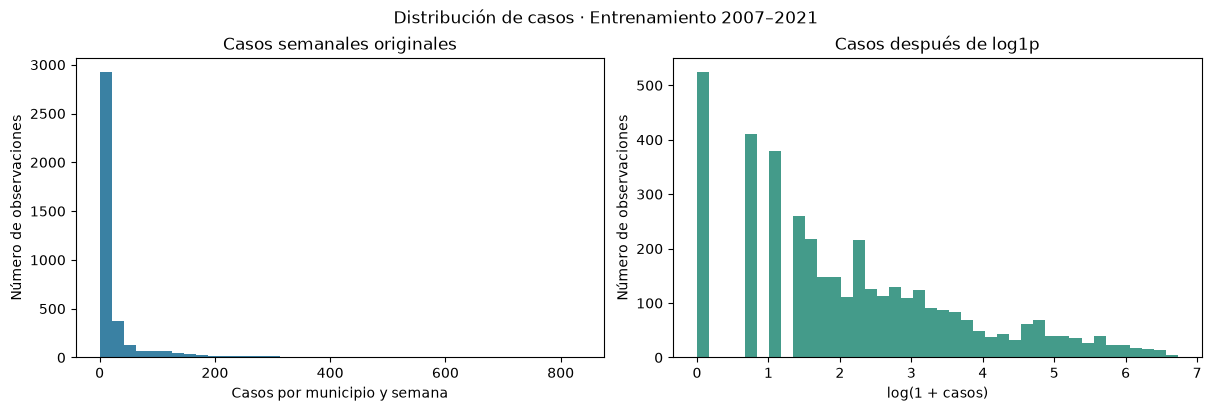

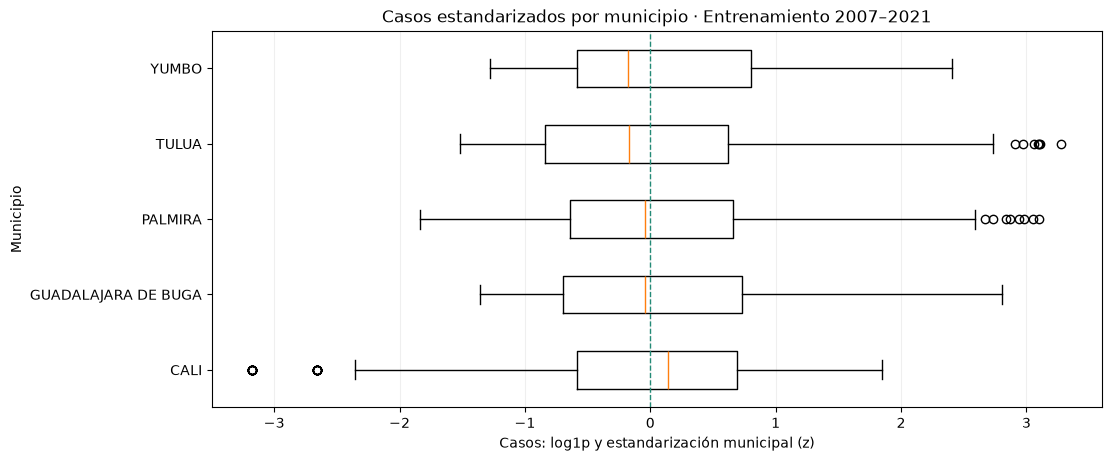

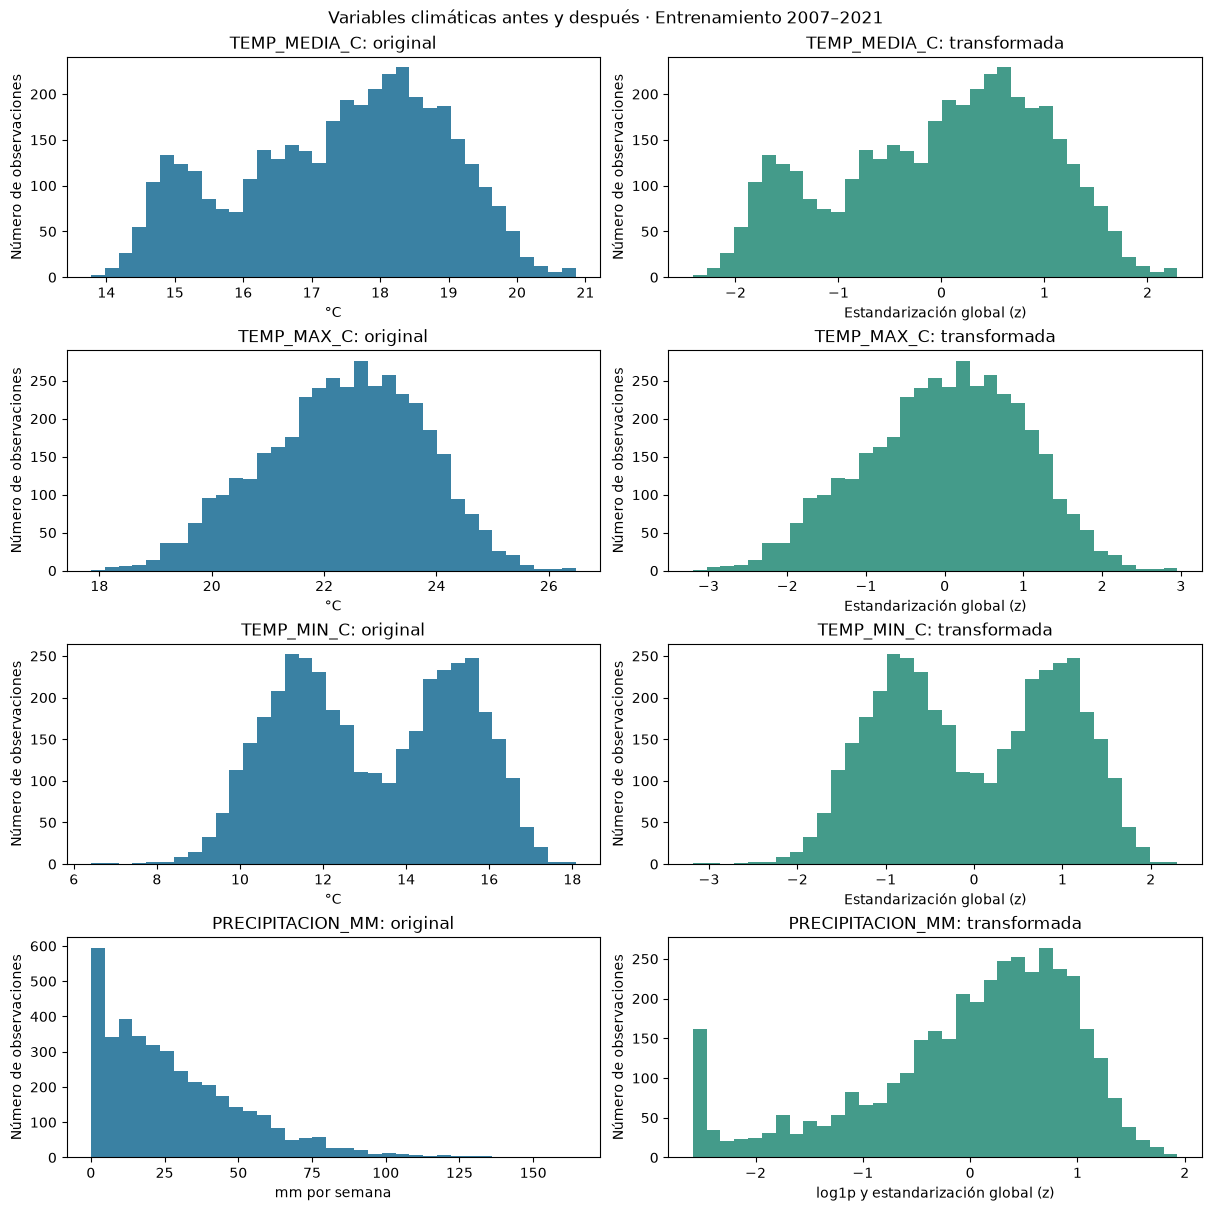

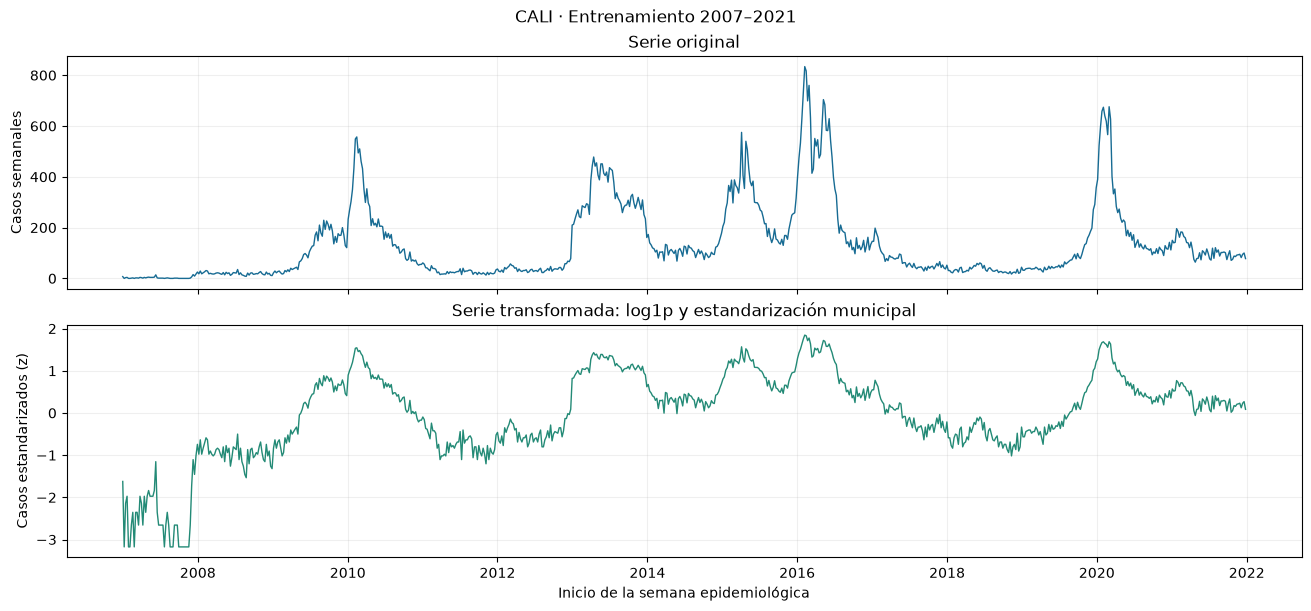

In [30]:
entrenamiento_graficas_lstm = df_lstm_entrenamiento
nombres_municipios_lstm = entrenamiento_graficas_lstm.groupby(ID_LSTM)['MUNICIPIO'].first().to_dict()
azul_lstm, verde_lstm = '#176B93', '#238A76'

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for eje, columna, titulo, etiqueta, color in [
    (ejes[0], 'CASOS', 'Casos semanales originales', 'Casos por municipio y semana', azul_lstm),
    (ejes[1], 'CASOS_log1p', 'Casos después de log1p', 'log(1 + casos)', verde_lstm),
]:
    eje.hist(entrenamiento_graficas_lstm[columna], bins=40, color=color, alpha=0.85)
    eje.set(title=titulo, xlabel=etiqueta, ylabel='Número de observaciones')
fig.suptitle('Distribución de casos · Entrenamiento 2007–2021')
plt.show()

fig, eje = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
eje.boxplot(
    [entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(m), 'CASOS_std'] for m in orden_municipios_lstm],
    tick_labels=[nombres_municipios_lstm[m] for m in orden_municipios_lstm],
    orientation='horizontal',
)
eje.axvline(0, color=verde_lstm, linewidth=1, linestyle='--')
eje.set(title='Casos estandarizados por municipio · Entrenamiento 2007–2021', xlabel='Casos: log1p y estandarización municipal (z)', ylabel='Municipio')
eje.grid(axis='x', alpha=0.2)
plt.show()

fig, ejes = plt.subplots(len(CLIMA_LSTM), 2, figsize=(12, 12), constrained_layout=True)
for fila, columna in enumerate(CLIMA_LSTM):
    es_lluvia = columna == PRECIPITACION_LSTM
    unidad = 'mm por semana' if es_lluvia else '°C'
    etiqueta_transformada = 'log1p y estandarización global (z)' if es_lluvia else 'Estandarización global (z)'
    ejes[fila, 0].hist(entrenamiento_graficas_lstm[columna], bins=35, color=azul_lstm, alpha=0.85)
    ejes[fila, 0].set(title=f'{columna}: original', xlabel=unidad, ylabel='Número de observaciones')
    ejes[fila, 1].hist(entrenamiento_graficas_lstm[f'{columna}_std'], bins=35, color=verde_lstm, alpha=0.85)
    ejes[fila, 1].set(title=f'{columna}: transformada', xlabel=etiqueta_transformada, ylabel='Número de observaciones')
fig.suptitle('Variables climáticas antes y después · Entrenamiento 2007–2021')
plt.show()

municipio_grafica_lstm = orden_municipios_lstm[0]  # Cali (76001), presente en los datos.
serie_grafica_lstm = entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(municipio_grafica_lstm)]
fig, ejes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
ejes[0].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS'], color=azul_lstm, linewidth=1)
ejes[0].set(title='Serie original', ylabel='Casos semanales')
ejes[1].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS_std'], color=verde_lstm, linewidth=1)
ejes[1].set(title='Serie transformada: log1p y estandarización municipal', xlabel='Inicio de la semana epidemiológica', ylabel='Casos estandarizados (z)')
for eje in ejes:
    eje.grid(alpha=0.2)
fig.suptitle(f'{nombres_municipios_lstm[municipio_grafica_lstm]} · Entrenamiento 2007–2021')
plt.show()


### 12.4. Datos y funciones disponibles para el modelado

Al terminar esta sección quedan disponibles los siguientes objetos. Sus nombres conservan el sufijo `lstm`, aunque sus transformaciones también se reutilizan en los demás modelos.

| Objeto | Contenido |
| --- | --- |
| `df_lstm_entrenamiento`, `df_lstm_validacion`, `df_lstm_test` | Tablas transformadas, separadas por periodo, con una fila por municipio y semana. |
| `conjuntos_transformados_lstm` | Las mismas tablas, agrupadas con las claves `training`, `validation` y `test`. |
| `columnas_entrada_lstm` | Siete entradas: casos, tres temperaturas, precipitación, seno y coseno de la semana, con las transformaciones descritas. |
| `columna_objetivo_lstm` | `CASOS_std`, la variable que aprenderán a pronosticar los modelos. |
| `escaladores_casos_lstm` | Los cinco escaladores de casos, identificados por `COD_DANE`. |
| `escaladores_clima_lstm` | Los escaladores de temperatura y precipitación. |
| `invertir_casos_lstm` | Función para recuperar el número de casos con el escalador municipal correspondiente. |
| `orden_municipios_lstm`, `semanas_por_ano_lstm` | Orden de los municipios y calendario de 52 o 53 semanas. |
| `auditoria_ajuste_lstm`, `verificacion_integridad_lstm`, `faltantes_lstm` | Comprobaciones del ajuste y de los datos transformados. |

Las columnas originales y los identificadores se conservan, pero las entradas numéricas del modelo son solo las indicadas en `columnas_entrada_lstm`. La representación del municipio para los modelos globales se incorpora en la preparación de secuencias del punto 13.


Las secuencias se forman por municipio: una ventana nunca debe continuar con las semanas de otra ciudad. Para pronosticar t+4 utilizamos información hasta t, sin añadir los casos ni el clima observado de las semanas futuras.

Los objetos de esta sección se crean en memoria. Después de reiniciar el kernel, esta parte puede recuperar los CSV semanales y ajustar de nuevo los escaladores con entrenamiento, sin releer los archivos anuales. El punto 13 utiliza estas transformaciones de la sesión para construir las secuencias; los modelos se entrenan después.


## 13. Construir las secuencias temporales

Aquí solo preparamos las entradas y sus objetivos. Usamos los DataFrames transformados del punto 12 y sus escaladores, ajustados con entrenamiento. Todavía no entrenamos modelos predictivos ni mostramos MAE o RMSE.

Cada ventana pertenece a un municipio, tiene 12, 16 o 20 semanas y avanza una semana cada vez. Si la última entrada es t, el objetivo es el número de casos de t+4, no la suma mensual. Las siete entradas son los casos, las tres temperaturas, la precipitación y el seno y coseno de la semana.

Las tres historias comparten las mismas fechas objetivo. Empezamos cuando hay historia suficiente para la ventana más larga. La validación solo incluye emisiones desde el cierre del entrenamiento, para no simular un pronóstico emitido antes de poder ajustar el modelo con ese periodo completo. El contexto anterior puede entrar en una ventana, pero nunca los datos posteriores a t.

El one-hot municipal se ajusta con entrenamiento y añade cinco indicadores a los modelos globales. No se recuperan secuencias, escaladores, modelos ni resultados de otras ejecuciones. El test no interviene en esta construcción.


In [31]:
codificador_municipios_actual = OneHotEncoder(sparse_output=False, handle_unknown='error', dtype=np.float32)
codificador_municipios_actual.fit(df_lstm_entrenamiento[['COD_DANE']])
secuencias_desarrollo = construir_secuencias(
    df_lstm_entrenamiento, df_lstm_validacion, columnas_entrada_lstm,
    codificador_municipios_actual, historias=HISTORIAS, horizonte=HORIZONTE,
)
preprocesamiento_actual = {
    'escaladores_casos': escaladores_casos_lstm,
    'escaladores_clima': escaladores_clima_lstm,
    'codificador_municipios': codificador_municipios_actual,
    'columnas_temporales': columnas_entrada_lstm.copy(),
    'orden_municipios': orden_municipios_lstm.copy(),
}
resumen_secuencias = pd.DataFrame([
    {'HISTORIA': v, 'CONJUNTO': conjunto, 'FORMA_X': str(datos['X'].shape),
     'FORMA_Y': str(datos['y'].shape), 'MATRIZ_BASELINE': str(datos['matriz'].shape),
     'PRIMER_OBJETIVO': datos['meta']['FECHA_OBJETIVO'].min(),
     'ULTIMO_OBJETIVO': datos['meta']['FECHA_OBJETIVO'].max()}
    for v, grupos in secuencias_desarrollo.items() for conjunto, datos in grupos.items()
])
display(resumen_secuencias)
print('Secuencias construidas. Todavía no se ha entrenado ningún modelo predictivo.')


,HISTORIA,CONJUNTO,FORMA_X,FORMA_Y,MATRIZ_BASELINE,PRIMER_OBJETIVO,ULTIMO_OBJETIVO
0,12,training,"(3800, 12, 7)","(3800, 1)","(3800, 89)",2007-06-10,2021-12-26
1,12,validation,"(505, 12, 7)","(505, 1)","(505, 89)",2022-01-23,2023-12-24
2,16,training,"(3800, 16, 7)","(3800, 1)","(3800, 117)",2007-06-10,2021-12-26
3,16,validation,"(505, 16, 7)","(505, 1)","(505, 117)",2022-01-23,2023-12-24
4,20,training,"(3800, 20, 7)","(3800, 1)","(3800, 145)",2007-06-10,2021-12-26
5,20,validation,"(505, 20, 7)","(505, 1)","(505, 145)",2022-01-23,2023-12-24


Secuencias construidas. Todavía no se ha entrenado ningún modelo predictivo.


## 14. Entrenar los modelos baseline

Antes de comparar las redes LSTM y GRU, necesitamos unas referencias para saber qué podemos conseguir con modelos más sencillos. Para eso entrenamos **regresión lineal, Random Forest y XGBoost**. Aquí los llamamos baselines porque serán nuestro punto de comparación; no estamos suponiendo que las redes necesariamente vayan a superarlos.

Cada modelo se entrena de forma global con los datos de los cinco municipios y se prueba con historias de **12, 16 y 20 semanas**. En total hacemos **nueve ajustes**. Todos tienen un único objetivo: pronosticar los casos de la semana **t+4**, no los cuatro valores intermedios ni el total del mes.

### 14.1. Preparar las entradas de los baselines

Reutilizamos las secuencias del punto 13. Cada semana aporta siete variables: casos de dengue, temperaturas media, máxima y mínima, precipitación y seno y coseno de la semana epidemiológica. También añadimos los cinco indicadores del one-hot municipal, para que el modelo pueda distinguir de dónde viene cada ejemplo.

Estos modelos reciben una tabla, así que convertimos cada ventana en una fila. Las variables de cada semana conservan su posición: el modelo puede distinguir un dato reciente de otro más antiguo. El tensor original sigue disponible para las redes.

| Historia | Variables de la ventana | Indicadores municipales | Entradas por ejemplo |
| --- | --- | --- | --- |
| 12 semanas | 12 × 7 = 84 | 5 | 89 |
| 16 semanas | 16 × 7 = 112 | 5 | 117 |
| 20 semanas | 20 × 7 = 140 | 5 | 145 |

Dentro de cada historia, los tres modelos reciben exactamente las mismas entradas y objetivos. Las tres historias también comparten las fechas que se van a pronosticar: 3.800 ejemplos de entrenamiento y 505 de validación.

### 14.2. Regresión lineal múltiple

La regresión lineal combina las entradas mediante una suma ponderada y un término constante. Durante el ajuste aprende cuánto peso darle a cada variable y a cada semana de la ventana, buscando reducir el error cuadrático en entrenamiento. Es múltiple porque utiliza varios predictores; su salida sigue siendo un solo valor para t+4.

Usamos **`LinearRegression()` con su configuración predeterminada**: incluye el término constante y no añade penalizaciones a los coeficientes. Nos permite revisar cuánto se puede explicar con una combinación lineal de la historia disponible. No incorpora por sí sola relaciones más complejas entre variables, como sí pueden hacerlo los árboles. Sus coeficientes describen el ajuste predictivo y no demuestran efectos causales del clima sobre el dengue.

### 14.3. Random Forest

Random Forest entrena varios árboles de decisión y promedia sus predicciones. Cada árbol aprende reglas a partir de distintas muestras del entrenamiento y de una selección de variables en sus divisiones. Esto permite representar relaciones no lineales e interacciones; por ejemplo, que una variable sea útil bajo ciertas condiciones de otra.

La configuración inicial es:

| Parámetro | Valor | Para qué se usa |
| --- | --- | --- |
| `n_estimators` | 300 | Cantidad de árboles cuyas predicciones se promedian. |
| `max_depth` | 12 | Limita la profundidad de cada árbol. |
| `min_samples_leaf` | 3 | Exige al menos tres ejemplos en cada hoja, para evitar reglas basadas en un solo registro. |
| `random_state` | 42 | Fija la semilla de las decisiones aleatorias del ajuste. |

Los árboles se ajustan únicamente con entrenamiento. La validación se utiliza después para comparar el desempeño de las tres historias; no decide una parada anticipada para este modelo.

### 14.4. XGBoost

XGBoost también combina árboles, pero los construye de manera sucesiva: cada nuevo árbol busca reducir los errores del conjunto que ya se ha formado. Su aporte se incorpora gradualmente, mediante una tasa de aprendizaje. Así podemos comparar el promedio de árboles de Random Forest con un enfoque que va corrigiendo su predicción paso a paso.

Conservamos esta configuración inicial:

| Parámetro | Valor | Para qué se usa |
| --- | --- | --- |
| `n_estimators` | 800 | Máximo de rondas de entrenamiento. |
| `max_depth` | 3 | Mantiene los árboles poco profundos. |
| `learning_rate` | 0,03 | Controla cuánto aporta cada nuevo árbol. |
| `min_child_weight` | 5 | Restringe las divisiones que tienen poco apoyo en los datos. |
| `subsample` | 0,80 | Usa una muestra del 80 % de los ejemplos de entrenamiento en cada ronda. |
| `colsample_bytree` | 0,80 | Usa una selección del 80 % de las columnas para construir cada árbol. |
| `reg_lambda` / `reg_alpha` | 1 / 0 | Aplica la penalización L2 y deja desactivada la L1. |
| `early_stopping_rounds` | 50 | Detiene el ajuste si el error de validación no mejora durante 50 rondas. |
| `random_state` | 42 | Fija la semilla del ajuste. |

Utilizamos el objetivo de error cuadrático, `reg:squarederror`. La parada anticipada se guía por **RMSE de validación en la escala transformada** y las predicciones se generan hasta la mejor ronda encontrada. El conjunto de evaluación no participa en esa decisión.

### 14.5. Entrenar y pasar a la comparación

Los tres modelos aprenden a predecir los casos con la transformación del punto 12: `log1p` y estandarización por municipio. Sus entradas también conservan las transformaciones ya realizadas. En el punto 15 deshacemos la transformación de la salida con el escalador correspondiente a cada municipio y calculamos MAE y RMSE en **casos de dengue**.

La celda siguiente llama a `fit` para cada modelo y después obtiene sus predicciones de entrenamiento y validación. Guarda los modelos y sus resultados en una carpeta nueva de esta ejecución. Estas configuraciones son el punto de partida; todavía no hacemos una búsqueda exhaustiva de hiperparámetros. La elección se apoya en validación y dejamos el conjunto de evaluación para el cierre del trabajo.


In [32]:
catalogo_arquitecturas = catalogo_redes()
RUTA_EJECUCION = nueva_ejecucion(preprocesamiento_actual, columnas_entrada_lstm, catalogo_arquitecturas)
modelos_baseline = {}
catalogo_baselines = []
tablas_predicciones_baseline = []
print('Nueva ejecución:', RUTA_EJECUCION.as_posix(), flush=True)

for historia in HISTORIAS:
    entrenamiento = secuencias_desarrollo[historia]['training']
    validacion = secuencias_desarrollo[historia]['validation']
    candidatos = [
        ('regresion_lineal', 'Regresión lineal', LinearRegression()),
        ('random_forest', 'Random Forest', RandomForestRegressor(
            n_estimators=300, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=4)),
        ('xgboost', 'XGBoost', XGBRegressor(**CONFIG_XGB)),
    ]
    for clave, familia, modelo in candidatos:
        identificador = f'{clave}_v{historia}'
        print(f'Entrenando {familia}, historia de {historia} semanas...', flush=True)
        if familia == 'XGBoost':
            modelo.fit(
                entrenamiento['matriz'], entrenamiento['y'].ravel(),
                eval_set=[(entrenamiento['matriz'], entrenamiento['y'].ravel()),
                          (validacion['matriz'], validacion['y'].ravel())], verbose=False,
            )
        else:
            modelo.fit(entrenamiento['matriz'], entrenamiento['y'].ravel())
        modelos_baseline[identificador] = modelo
        carpeta = RUTA_EJECUCION / 'modelos' / identificador
        carpeta.mkdir(exist_ok=False)
        archivo = carpeta / ('modelo.ubj' if familia == 'XGBoost' else 'modelo.joblib')
        if familia == 'XGBoost':
            modelo.save_model(archivo)
            progreso = modelo.evals_result()
            pd.DataFrame({'RMSE_TRAIN_STD': progreso['validation_0']['rmse'],
                          'RMSE_VAL_STD': progreso['validation_1']['rmse']}).to_csv(
                carpeta / 'historial.csv', index=False, encoding='utf-8-sig')
        else:
            joblib.dump(modelo, archivo)
        spec = {'ID': identificador, 'FAMILIA': familia, 'RECETA': 'baseline', 'HISTORIA': historia,
            'NOMBRE': f'{familia} · {historia}s', 'TIPO': 'xgboost' if familia == 'XGBoost' else 'sklearn',
            'CONFIG': CONFIG_XGB.copy() if familia == 'XGBoost' else modelo.get_params(),
            'ARCHIVO': archivo.as_posix(), 'HISTORIAL': None, 'MATRIZ': False,
            'PARAMETROS_RED': None, 'N_ENTRENAMIENTO': len(entrenamiento['X']),
            'ENTRENADO_EN_ESTA_EJECUCION': True, 'EJECUCION': RUTA_EJECUCION.name}
        catalogo_baselines.append(spec)
        for conjunto, datos in [('training', entrenamiento), ('validation', validacion)]:
            if familia == 'XGBoost':
                pred = modelo.predict(datos['matriz'], iteration_range=(0, modelo.best_iteration+1))
            else:
                pred = modelo.predict(datos['matriz'])
            tablas_predicciones_baseline.append(tabla_predicciones(
                spec, datos, pred.reshape(-1, 1), preprocesamiento_actual, conjunto))
        print(f'  {familia} entrenado; predicciones de train y validation calculadas.', flush=True)
predicciones_baselines = pd.concat(tablas_predicciones_baseline, ignore_index=True)


Nueva ejecución: ResultadosModelos/entrenamiento_en_notebook/ejecucion_93868d0d


Entrenando Regresión lineal, historia de 12 semanas...


  Regresión lineal entrenado; predicciones de train y validation calculadas.


Entrenando Random Forest, historia de 12 semanas...


  Random Forest entrenado; predicciones de train y validation calculadas.


Entrenando XGBoost, historia de 12 semanas...


... (9 outputs left out)

Entrenando Random Forest, historia de 20 semanas...


  Random Forest entrenado; predicciones de train y validation calculadas.


Entrenando XGBoost, historia de 20 semanas...


  XGBoost entrenado; predicciones de train y validation calculadas.


## 15. Evaluar los baselines en validación

Estas métricas se calculan con las predicciones de los nueve modelos que acabamos de entrenar. Primero deshacemos las transformaciones con el escalador de cada municipio. MAE mide el error absoluto promedio en casos y RMSE da más peso a los errores grandes.

La selección se hace con validación. Los errores de entrenamiento ayudan a revisar el ajuste. En las series mostramos, para cada familia, la historia con menor MAE general de validación y mantenemos ese mismo modelo en los cinco municipios.


MODELO,CONJUNTO,N,MAE,RMSE
Regresión lineal · 12s,training,3800,10.603,31.420
Regresión lineal · 12s,validation,505,14.881,37.025
Random Forest · 12s,training,3800,5.310,15.469
Random Forest · 12s,validation,505,15.731,39.453
XGBoost · 12s,training,3800,8.417,24.996
XGBoost · 12s,validation,505,15.681,38.750
Regresión lineal · 16s,training,3800,10.454,30.958
Regresión lineal · 16s,validation,505,14.885,36.312
Random Forest · 16s,training,3800,5.172,14.950
Random Forest · 16s,validation,505,15.201,38.171


MODELO,MUNICIPIO,N,MAE,RMSE
Regresión lineal · 12s,CALI,101,39.494,61.537
Regresión lineal · 12s,GUADALAJARA DE BUGA,101,1.880,3.611
Regresión lineal · 12s,PALMIRA,101,21.341,51.495
Regresión lineal · 12s,TULUA,101,3.505,7.148
Regresión lineal · 12s,YUMBO,101,8.185,18.752
Random Forest · 12s,CALI,101,39.554,61.946
Random Forest · 12s,GUADALAJARA DE BUGA,101,2.010,3.777
Random Forest · 12s,PALMIRA,101,24.450,59.059
Random Forest · 12s,TULUA,101,3.306,6.324
Random Forest · 12s,YUMBO,101,9.337,20.080


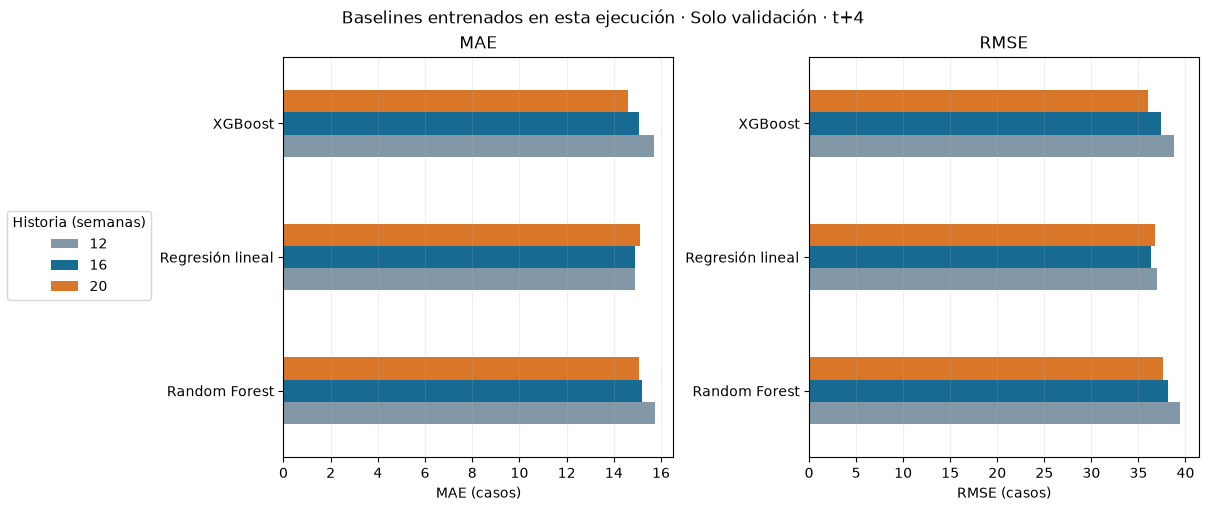

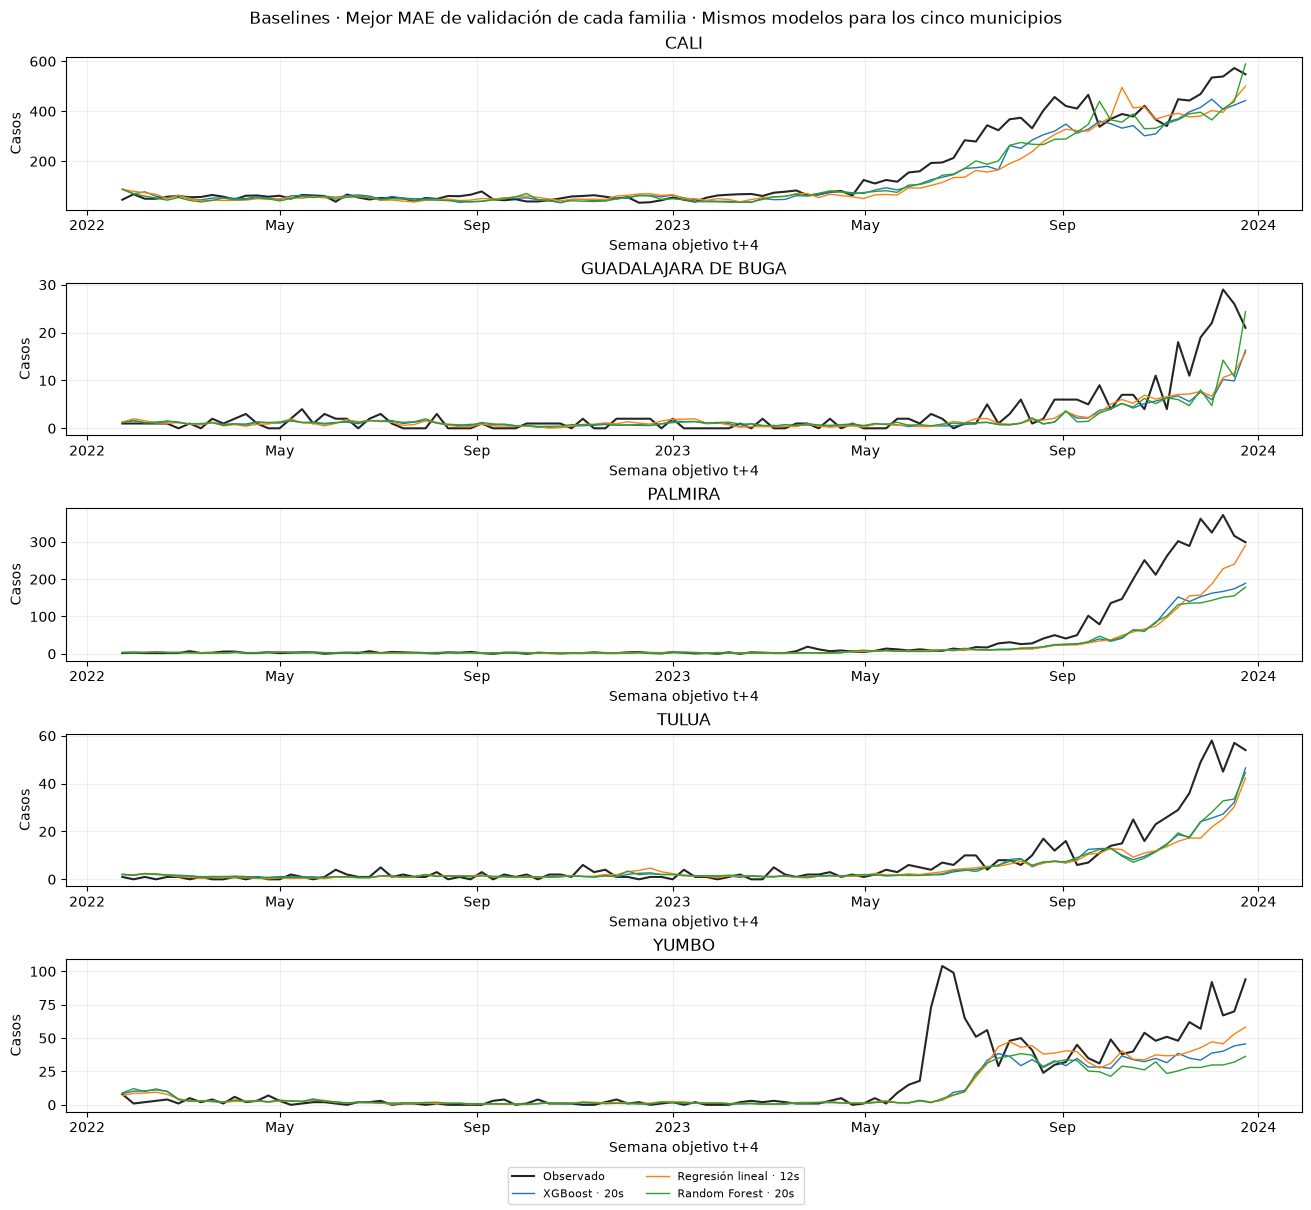

In [33]:
metricas_baselines, metricas_municipales_baselines, ranking_baselines = resumir_predicciones(
    predicciones_baselines, catalogo_baselines)
display(metricas_baselines[['MODELO','CONJUNTO','N','MAE','RMSE']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
display(metricas_municipales_baselines.loc[
    metricas_municipales_baselines['CONJUNTO'].eq('validation'),
    ['MODELO','MUNICIPIO','N','MAE','RMSE']].style.format({'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
graficar_baselines(predicciones_baselines, ranking_baselines, RUTA_EJECUCION)
exportar_resultados_actuales(RUTA_EJECUCION, predicciones_baselines, metricas_baselines,
    metricas_municipales_baselines, ranking_baselines, catalogo_baselines)


## 16. Definir las arquitecturas LSTM y GRU

En este punto reunimos las redes que vamos a comparar. Incluimos la referencia **LSTM32 + Dense16**, la estructura reducida **LSTM16 + Dense8**, las variantes con Dropout, las redes de varias capas y los modelos locales.

Todas tienen una Dense de salida de una neurona para pronosticar t+4. La Dense que puede cambiar de tamaño o quitarse es la intermedia, que se encuentra antes de esa salida.

### 16.1. Dónde se ubica la Dense intermedia

La **LSTM o GRU** recibe las semanas anteriores y aprende a resumir su información temporal. Las unidades indican el tamaño de ese resumen: una LSTM de 32 unidades entrega 32 valores y una de 16 entrega 16. No son semanas ni pronósticos distintos.

En las redes globales unimos ese resumen con los cinco indicadores del **one-hot municipal**. Después puede venir una Dense intermedia, con activación ReLU, que aprende a combinar la historia y el municipio antes de producir el pronóstico. Finalmente, la Dense de salida de una neurona, con activación lineal, entrega el valor de t+4.

Estas son las tres formas que ayudan a distinguir el papel de cada capa:

| Estructura | Recorrido después de recibir la historia semanal |
| --- | --- |
| Referencia LSTM32 + Dense16 | LSTM de 32 unidades → unir one-hot municipal → Dense intermedia de 16 → Dense de salida de 1 |
| Reducida LSTM16 + Dense8 | LSTM de 16 unidades → unir one-hot municipal → Dense intermedia de 8 → Dense de salida de 1 |
| LSTM32 sin Dense intermedia | LSTM de 32 unidades → unir one-hot municipal → Dense de salida de 1 |

En la referencia, la Dense intermedia recibe **37 valores**: 32 de la LSTM y 5 del municipio. En la estructura reducida recibe **21 valores**: 16 de la LSTM y 5 del municipio, y los transforma en 8 antes de la salida.

La salida está en la escala transformada del punto 12. Para expresarla en casos, deshacemos la transformación con el escalador del municipio correspondiente. Cada red produce un solo valor para la semana t+4.

### 16.2. Arquitecturas globales que vamos a comparar

La tabla reúne todas las estructuras globales. Cada ajuste utiliza ventanas de los cinco municipios y añade el one-hot después de las capas recurrentes. **LSTM16 + Dense8 se prueba con historias de 12, 16 y 20 semanas, sin Dropout**, igual que la referencia con la que queremos contrastarla.

| Estructura | Familia | Capas recurrentes y unidades | Dense intermedia | Dropout después de cada capa recurrente | Historia en semanas | Ajustes globales |
| --- | --- | --- | --- | --- | --- | --- |
| Referencia | LSTM y GRU | Una capa de 32 | 16 neuronas | 0 | 12, 16 y 20 | 6 |
| Reducida LSTM16 + Dense8 | LSTM | Una capa de 16 | 8 neuronas | 0 | 12, 16 y 20 | 3 |
| Sin Dense intermedia | LSTM y GRU | Una capa de 32 | No se añade | 0 | 12, 16 y 20 | 6 |
| Dropout de 0,20 | LSTM y GRU | Una capa de 32 | 16 neuronas | 0,20 | 12, 16 y 20 | 6 |
| Dropout de 0,50 | LSTM y GRU | Una capa de 32 | 16 neuronas | 0,50 | 12, 16 y 20 | 6 |
| Dos capas | LSTM y GRU | 32 → 16 | 16 neuronas | 0,20 | 12, 16 y 20 | 6 |
| Tres capas | LSTM y GRU | 32 → 16 → 8 | 16 neuronas | 0,20 | 12, 16 y 20 | 6 |
| Referencia de 64 unidades | LSTM | Una capa de 64 | 16 neuronas | 0 | 16 | 1 |
| Referencia de dos capas de 32 | LSTM | 32 → 32 | 16 neuronas | 0 | 16 | 1 |

La referencia compartida por LSTM y GRU representa seis ajustes: dos familias por tres historias. La estructura LSTM16 + Dense8 representa tres ajustes, uno por historia. En total, la tabla reúne **41 redes globales**. La Dense de salida de una neurona se conserva en todas las filas.

### 16.3. Qué queremos revisar al cambiar la estructura

Al comparar LSTM16 + Dense8 frente a LSTM32 + Dense16, revisamos si una red más pequeña puede mantener el desempeño con menos parámetros. Ambas conservan las mismas variables, fechas objetivo, indicadores municipales y reglas de entrenamiento. Reducimos a la vez las unidades LSTM y las neuronas de la Dense intermedia, así que la comparación evalúa ese cambio completo.

La variante sin Dense intermedia permite revisar si basta con conectar el resumen temporal y el municipio directamente a la salida. Una Dense adicional aporta más posibilidades para combinar esa información, pero su utilidad debe comprobarse en validación.

**Dropout** pone temporalmente en cero una parte de las salidas recurrentes durante entrenamiento: aproximadamente el 20 % o el 50 %, según la variante. Busca reducir la dependencia de unas pocas activaciones y se desactiva al generar predicciones. En las redes de varias capas lo aplicamos después de cada capa recurrente.

Al apilar capas, las primeras entregan una secuencia a la siguiente y la última produce el resumen que unimos con el municipio. Las variantes profundas cambian tanto la cantidad de capas como el Dropout; sus diferencias no permiten atribuir una mejora únicamente a uno de esos cambios. Tampoco suponemos que tener menos parámetros garantice menos sobreajuste o menor error.

### 16.4. Redes locales y total de la comparación

Las LSTM locales se entrenan por separado: una por municipio y por historia. Cada una tiene **LSTM32 → Dense intermedia de 16 → Dense de salida de 1**, sin Dropout. Su municipio es fijo, por lo que no necesitan one-hot. Reunimos las predicciones de las cinco ciudades para compararlas con los enfoques globales sobre las mismas fechas.

| Grupo | Entrenamientos de redes | Enfoques en la comparación |
| --- | --- | --- |
| Redes globales de la tabla anterior | 41 | 41 |
| LSTM locales: 5 municipios × 3 historias | 15 | 3, reuniendo las cinco redes de cada historia |
| Total de redes recurrentes | **56** | **44** |

Al añadir los nueve baselines, la comparación reúne **53 enfoques**.

Aquí definimos las arquitecturas. El entrenamiento desde cero se realiza en el punto 17: la matriz compartida está en 17.1 y 17.2; LSTM16 + Dense8 y las otras referencias adicionales se entrenan en 17.3; y las redes locales, en 17.4. Después revisamos sus resultados en validación.


In [34]:
estructuras_mostradas = [{'RECETA': clave, 'UNIDADES': ' → '.join(map(str, cfg['unidades'])),
    'DENSE_INTERMEDIA': cfg['dense'], 'DROPOUT': cfg['dropout']} for clave, cfg in RECETAS.items()]
estructuras_mostradas.append({'RECETA': 'compacta16_8 (solo LSTM)', 'UNIDADES': '16',
    'DENSE_INTERMEDIA': 8, 'DROPOUT': 0.0})
display(pd.DataFrame(estructuras_mostradas))
modelos_recurrentes = {s['ID']: {**s, 'ARCHIVO': {} if s['TIPO']=='local' else None,
    'HISTORIAL': None, 'N_ENTRENAMIENTO': len(secuencias_desarrollo[s['HISTORIA']]['training']['X']),
    'ENTRENADO_EN_ESTA_EJECUCION': False, 'EJECUCION': RUTA_EJECUCION.name}
    for s in catalogo_arquitecturas}
predicciones_redes_individuales = {}
historiales_recurrentes = {}
registro_redes_actuales = {}
display(pd.DataFrame(catalogo_arquitecturas)[['NOMBRE','HISTORIA','TIPO']])


,RECETA,UNIDADES,DENSE_INTERMEDIA,DROPOUT
0,referencia,32,16,0.0
1,sin_dense,32,0,0.0
2,drop20,32,16,0.2
3,drop50,32,16,0.5
4,dos_capas,32 → 16,16,0.2
5,tres_capas,32 → 16 → 8,16,0.2
6,compacta16_8 (solo LSTM),16,8,0.0


,NOMBRE,HISTORIA,TIPO
0,LSTM 32 · Dense16 · D0 · 12s,12,red
1,LSTM 32 · sin Dense intermedia · 12s,12,red
2,"LSTM 32 · Dense16 · D0,20 · 12s",12,red
3,"LSTM 32 · Dense16 · D0,50 · 12s",12,red
4,"LSTM 32→16 · Dense16 · D0,20 · 12s",12,red
5,"LSTM 32→16→8 · Dense16 · D0,20 · 12s",12,red
6,LSTM 32 · Dense16 · D0 · 16s,16,red
7,LSTM 32 · sin Dense intermedia · 16s,16,red
8,"LSTM 32 · Dense16 · D0,20 · 16s",16,red
9,"LSTM 32 · Dense16 · D0,50 · 16s",16,red


## 17. Entrenar las redes definidas

Cada red empieza con pesos y optimizador independientes. Utilizamos semilla 42, Adam con tasa de 0,001, lotes de 32, hasta 100 épocas y `shuffle=False`. EarlyStopping recupera los pesos con menor MSE de validación y detiene el ajuste tras 10 épocas sin mejora; ReduceLROnPlateau reduce la tasa después de 5 épocas sin mejora.

La función siguiente contiene la llamada a `fit`. Después de cada ajuste calculamos las predicciones y guardamos sus mejores pesos. Las redes locales conservan el mismo esquema, utilizando solo los ejemplos de su municipio.


In [35]:
def entrenar_red_en_notebook(spec, codigo=None):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(42)
    tf.config.experimental.enable_op_determinism()
    historia = spec['HISTORIA']
    local = spec['TIPO']=='local'
    entrenamiento = secuencias_desarrollo[historia]['training']
    validacion = secuencias_desarrollo[historia]['validation']
    if local:
        entrenamiento = datos_municipales(entrenamiento, codigo)
        validacion = datos_municipales(validacion, codigo)
    id_red = spec['ID'] + (f'_{codigo}' if local else '')
    carpeta = RUTA_EJECUCION / 'modelos' / id_red
    carpeta.mkdir(exist_ok=True)
    archivo = carpeta / 'mejor_modelo.keras'
    modelo = crear_red({**spec, 'ID': id_red}, len(columnas_entrada_lstm), len(orden_municipios_lstm))
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001), loss='mse', metrics=['mae'])
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=10, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min', patience=5, factor=.5, min_lr=1e-5),
        tf.keras.callbacks.ModelCheckpoint(str(archivo), monitor='val_loss', mode='min', save_best_only=True),
        tf.keras.callbacks.CSVLogger(str(carpeta / 'progreso.csv')),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    print(f'Entrenando {id_red} ({len(entrenamiento["X"])} ejemplos)...', flush=True)
    historia_ajuste = modelo.fit(
        dataset_red(entrenamiento, local=local),
        validation_data=dataset_red(validacion, local=local),
        epochs=100, shuffle=False, callbacks=callbacks, verbose=0,
    )
    h = pd.DataFrame(historia_ajuste.history)
    h.insert(0, 'EPOCA', np.arange(1, len(h)+1))
    assert np.isfinite(h[['loss','val_loss']].to_numpy()).all()
    h.to_csv(carpeta / 'historial.csv', index=False, encoding='utf-8-sig')
    tablas = []
    for conjunto, datos in [('training', entrenamiento), ('validation', validacion)]:
        pred = predecir_red_actual(modelo, datos, local=local)
        if conjunto=='validation':
            np.testing.assert_allclose(np.mean((pred-datos['y'])**2), h['val_loss'].min(), rtol=2e-5, atol=2e-6)
        t = tabla_predicciones(spec, datos, pred, preprocesamiento_actual, conjunto)
        t['ID_RED'] = id_red
        tablas.append(t)
    predicciones_redes_individuales[id_red] = pd.concat(tablas, ignore_index=True)
    historiales_recurrentes[id_red] = h
    registro_redes_actuales[id_red] = {
        'ID_RED': id_red, 'ID_ENFOQUE': spec['ID'], 'COD_DANE': codigo,
        'N_TRAIN': len(entrenamiento['X']), 'N_VAL': len(validacion['X']),
        'PARAMETROS': int(modelo.count_params()), 'MEJOR_EPOCA': int(h['val_loss'].idxmin())+1,
        'EPOCAS_EJECUTADAS': len(h), 'ARCHIVO': archivo.as_posix(),
    }
    if local:
        spec['ARCHIVO'][codigo] = archivo.as_posix()
        filas = [r for r in registro_redes_actuales.values() if r['ID_ENFOQUE']==spec['ID']]
        spec['PARAMETROS_RED'] = sum(r['PARAMETROS'] for r in filas)
        spec['ENTRENADO_EN_ESTA_EJECUCION'] = len(spec['ARCHIVO'])==len(orden_municipios_lstm)
    else:
        spec.update(ARCHIVO=archivo.as_posix(), HISTORIAL=(carpeta/'historial.csv').as_posix(),
            PARAMETROS_RED=int(modelo.count_params()), ENTRENADO_EN_ESTA_EJECUCION=True,
            MEJOR_PASO=int(h['val_loss'].idxmin())+1, PASOS_EJECUTADOS=len(h))
    pd.DataFrame(registro_redes_actuales.values()).to_csv(
        RUTA_EJECUCION / 'tablas/registro_entrenamiento_redes.csv', index=False, encoding='utf-8-sig')
    print(f'  Ajuste terminado: mejor época {int(h["val_loss"].idxmin())+1}, de {len(h)} ejecutadas.', flush=True)
    del modelo
    tf.keras.backend.clear_session()
    gc.collect()


### 17.1. Entrenar las LSTM globales

Entrenamos las seis estructuras para cada historia. Cada celda ajusta sus propios modelos antes de continuar con la siguiente longitud.


In [36]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==12:
        entrenar_red_en_notebook(spec)


Entrenando lstm_referencia_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 27, de 37 ejecutadas.


Entrenando lstm_sin_dense_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 24, de 34 ejecutadas.


Entrenando lstm_drop20_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 18, de 28 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 29, de 39 ejecutadas.


Entrenando lstm_tres_capas_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 43, de 53 ejecutadas.


In [37]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==16:
        entrenar_red_en_notebook(spec)


Entrenando lstm_referencia_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 28, de 38 ejecutadas.


Entrenando lstm_sin_dense_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 23, de 33 ejecutadas.


Entrenando lstm_drop20_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 39, de 49 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 28, de 38 ejecutadas.


Entrenando lstm_tres_capas_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 28, de 38 ejecutadas.


In [38]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and spec['MATRIZ'] and spec['HISTORIA']==20:
        entrenar_red_en_notebook(spec)


Entrenando lstm_referencia_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 26, de 36 ejecutadas.


Entrenando lstm_sin_dense_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 20, de 30 ejecutadas.


Entrenando lstm_drop20_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 39, de 49 ejecutadas.


... (2 outputs left out)

Entrenando lstm_dos_capas_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 25, de 35 ejecutadas.


Entrenando lstm_tres_capas_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 20, de 30 ejecutadas.


### 17.2. Entrenar las GRU globales

Repetimos las mismas estructuras e historias con capas GRU. Se mantienen las entradas, objetivos y reglas de entrenamiento de las LSTM.


In [39]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='GRU' and spec['HISTORIA']==12:
        entrenar_red_en_notebook(spec)


Entrenando gru_referencia_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 82, de 92 ejecutadas.


Entrenando gru_sin_dense_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 73, de 83 ejecutadas.


Entrenando gru_drop20_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 26, de 36 ejecutadas.


... (2 outputs left out)

Entrenando gru_dos_capas_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 37, de 47 ejecutadas.


Entrenando gru_tres_capas_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 15, de 25 ejecutadas.


In [40]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='GRU' and spec['HISTORIA']==16:
        entrenar_red_en_notebook(spec)


Entrenando gru_referencia_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 45, de 55 ejecutadas.


Entrenando gru_sin_dense_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 62, de 72 ejecutadas.


Entrenando gru_drop20_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 26, de 36 ejecutadas.


... (2 outputs left out)

Entrenando gru_dos_capas_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 54, de 64 ejecutadas.


Entrenando gru_tres_capas_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 33, de 43 ejecutadas.


In [41]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='GRU' and spec['HISTORIA']==20:
        entrenar_red_en_notebook(spec)


Entrenando gru_referencia_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 52, de 62 ejecutadas.


Entrenando gru_sin_dense_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 34, de 44 ejecutadas.


Entrenando gru_drop20_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 39, de 49 ejecutadas.


... (2 outputs left out)

Entrenando gru_dos_capas_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 62, de 72 ejecutadas.


Entrenando gru_tres_capas_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 46, de 56 ejecutadas.


### 17.3. Entrenar las referencias adicionales y la LSTM16 + Dense8

Ajustamos las dos referencias con historia de 16 semanas: una capa LSTM de 64 unidades y dos capas de 32. También entrenamos la nueva estructura global **LSTM16 → unir one-hot municipal → Dense8 → Dense1** con historias de 12, 16 y 20 semanas.

Son cinco ajustes adicionales. Todos empiezan desde cero, sin Dropout y con las mismas reglas del punto 17. Las tres redes reducidas reciben las mismas fechas, variables y objetivos que sus respectivas referencias LSTM32 + Dense16. La comparación se hace con validación; el conjunto de evaluación sigue reservado para el cierre.


In [42]:
for spec in modelos_recurrentes.values():
    if spec['FAMILIA']=='LSTM' and not spec['MATRIZ']:
        entrenar_red_en_notebook(spec)


Entrenando lstm_adicional_B64_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 22, de 32 ejecutadas.


Entrenando lstm_adicional_D32x2_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 10, de 20 ejecutadas.


Entrenando lstm_compacta16_8_v12 (3800 ejemplos)...


  Ajuste terminado: mejor época 47, de 57 ejecutadas.


Entrenando lstm_compacta16_8_v16 (3800 ejemplos)...


  Ajuste terminado: mejor época 77, de 87 ejecutadas.


Entrenando lstm_compacta16_8_v20 (3800 ejemplos)...


  Ajuste terminado: mejor época 64, de 74 ejecutadas.


### 17.4. Entrenar las LSTM locales

Para cada historia ajustamos una red por municipio, sin one-hot porque su identidad es fija. Las cinco redes de una historia se reúnen para compararlas con los enfoques globales sobre las mismas fechas objetivo.


In [43]:
spec_local = modelos_recurrentes['local_v12']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)


Entrenando local_v12_76001 (760 ejemplos)...


  Ajuste terminado: mejor época 13, de 23 ejecutadas.


Entrenando local_v12_76111 (760 ejemplos)...


  Ajuste terminado: mejor época 20, de 30 ejecutadas.


Entrenando local_v12_76520 (760 ejemplos)...


  Ajuste terminado: mejor época 40, de 50 ejecutadas.


Entrenando local_v12_76834 (760 ejemplos)...


  Ajuste terminado: mejor época 13, de 23 ejecutadas.


Entrenando local_v12_76892 (760 ejemplos)...


  Ajuste terminado: mejor época 42, de 52 ejecutadas.


In [44]:
spec_local = modelos_recurrentes['local_v16']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)


Entrenando local_v16_76001 (760 ejemplos)...


  Ajuste terminado: mejor época 71, de 81 ejecutadas.


Entrenando local_v16_76111 (760 ejemplos)...


  Ajuste terminado: mejor época 41, de 51 ejecutadas.


Entrenando local_v16_76520 (760 ejemplos)...


  Ajuste terminado: mejor época 42, de 52 ejecutadas.


Entrenando local_v16_76834 (760 ejemplos)...


  Ajuste terminado: mejor época 13, de 23 ejecutadas.


Entrenando local_v16_76892 (760 ejemplos)...


  Ajuste terminado: mejor época 29, de 39 ejecutadas.


In [45]:
spec_local = modelos_recurrentes['local_v20']
for codigo in orden_municipios_lstm:
    entrenar_red_en_notebook(spec_local, codigo)


Entrenando local_v20_76001 (760 ejemplos)...


  Ajuste terminado: mejor época 47, de 57 ejecutadas.


Entrenando local_v20_76111 (760 ejemplos)...


  Ajuste terminado: mejor época 23, de 33 ejecutadas.


Entrenando local_v20_76520 (760 ejemplos)...


  Ajuste terminado: mejor época 25, de 35 ejecutadas.


Entrenando local_v20_76834 (760 ejemplos)...


  Ajuste terminado: mejor época 12, de 22 ejecutadas.


Entrenando local_v20_76892 (760 ejemplos)...


  Ajuste terminado: mejor época 26, de 36 ejecutadas.


### 17.5. Comprobar los entrenamientos completados

Antes de comparar, revisamos que se hayan ajustado las 56 redes y que cada enfoque tenga sus predicciones. La tabla registra ejemplos, parámetros y épocas de cada red individual. En la comparación global, los parámetros de un enfoque local son la suma de sus cinco redes.


In [46]:
numero_redes_esperadas = sum(len(orden_municipios_lstm) if s['TIPO']=='local' else 1
    for s in modelos_recurrentes.values())
assert len(registro_redes_actuales)==numero_redes_esperadas
assert all(s['ENTRENADO_EN_ESTA_EJECUCION'] for s in modelos_recurrentes.values())
registro_entrenamiento_redes = pd.DataFrame(registro_redes_actuales.values())
display(registro_entrenamiento_redes[['ID_RED','N_TRAIN','N_VAL','PARAMETROS','MEJOR_EPOCA','EPOCAS_EJECUTADAS']])
predicciones_recurrentes = pd.concat(predicciones_redes_individuales.values(), ignore_index=True)
catalogo_actual = [*catalogo_baselines, *modelos_recurrentes.values()]
assert len(catalogo_actual)==len(catalogo_baselines)+len(catalogo_arquitecturas) and len(modelos_baseline)==9


,ID_RED,N_TRAIN,N_VAL,PARAMETROS,MEJOR_EPOCA,EPOCAS_EJECUTADAS
0,lstm_referencia_v12,3800,505,5745,27,37
1,lstm_sin_dense_v12,3800,505,5158,24,34
2,lstm_drop20_v12,3800,505,5745,18,28
3,lstm_drop50_v12,3800,505,5745,43,53
4,lstm_dos_capas_v12,3800,505,8625,29,39
5,lstm_tres_capas_v12,3800,505,9297,43,53
6,lstm_referencia_v16,3800,505,5745,28,38
7,lstm_sin_dense_v16,3800,505,5158,23,33
8,lstm_drop20_v16,3800,505,5745,39,49
9,lstm_drop50_v16,3800,505,5745,46,56


## 18. Comparar los modelos entrenados en validación

Ahora reunimos los resultados de los baselines y de las redes entrenadas en los puntos anteriores. La tabla ordena las 53 configuraciones por MAE de validación, sin redondear para elegir el mínimo. RMSE, sesgo y errores por municipio permiten revisar diferencias que el promedio puede ocultar.

Todas las historias comparten los mismos objetivos. No elegimos modelos por el menor error de entrenamiento y el conjunto de evaluación no interviene. Los pronósticos se mantienen continuos, sin redondearlos ni recortarlos; se contabilizan los valores negativos.

Revisamos también LSTM16 + Dense8 frente a LSTM32 + Dense16 para cada historia, manteniendo los mismos objetivos y sin Dropout. Sus diferencias se calculan con las predicciones de esta ejecución.


In [47]:
predicciones_desarrollo = pd.concat([predicciones_baselines, predicciones_recurrentes], ignore_index=True)
metricas_desarrollo, metricas_municipales_desarrollo, ranking_validacion = resumir_predicciones(
    predicciones_desarrollo, catalogo_actual)
assert len(ranking_validacion)==len(catalogo_actual)
seleccion_validacion = {m: ranking_validacion.loc[ranking_validacion[m].idxmin()].to_dict() for m in ['MAE','RMSE']}
seleccion_validacion.update(ID_ELEGIDO=ranking_validacion.iloc[0]['ID'],
    criterio_principal='MAE agrupado de validación, sin redondear', candidato_provisional=True,
    entrenado_en_esta_ejecucion=True, ejecucion=RUTA_EJECUCION.name,
    test_consultado_en_esta_exploracion=False, test_historicamente_conocido=True)
display(ranking_validacion[['MODELO','HISTORIA','N','MAE','RMSE','PARAMETROS_RED','PRONOSTICOS_NEGATIVOS']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','PARAMETROS_RED':'{:.0f}'},na_rep='No aplica').hide(axis='index'))
display(resumir_validacion(ranking_validacion).style.format({'MIN_MAE':'{:.3f}','MIN_RMSE':'{:.3f}'}).hide(axis='index'))
ids_comparacion_tamano = [f'lstm_{receta}_v{v}' for v in HISTORIAS
    for receta in ['referencia', 'compacta16_8']]
comparacion_tamano_lstm = ranking_validacion.loc[
    ranking_validacion['ID'].isin(ids_comparacion_tamano)].sort_values(['HISTORIA', 'RECETA'])
display(comparacion_tamano_lstm[['MODELO','HISTORIA','N','PARAMETROS_RED','MAE','RMSE']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','PARAMETROS_RED':'{:.0f}'}).hide(axis='index'))

figuras_desarrollo = graficar_desarrollo(predicciones_desarrollo, metricas_desarrollo,
    metricas_municipales_desarrollo, ranking_validacion, catalogo_actual, RUTA_EJECUCION, mostrar=False)
exportar_resultados_actuales(RUTA_EJECUCION, predicciones_desarrollo, metricas_desarrollo,
    metricas_municipales_desarrollo, ranking_validacion, catalogo_actual, seleccion_validacion)


MODELO,HISTORIA,N,MAE,RMSE,PARAMETROS_RED,PRONOSTICOS_NEGATIVOS
LSTM 32 · Dense16 · D0 · 16s,16,505,11.627,27.738,5745,1
"LSTM 32 · Dense16 · D0,20 · 20s",20,505,11.669,26.314,5745,0
GRU 32 · Dense16 · D0 · 20s,20,505,12.083,28.829,4561,0
"GRU 32 · Dense16 · D0,20 · 20s",20,505,12.118,29.294,4561,0
LSTM 32 · Dense16 · D0 · 20s,20,505,12.154,28.005,5745,1
"LSTM 32 · Dense16 · D0,20 · 16s",16,505,12.155,28.644,5745,0
GRU 32 · Dense16 · D0 · 16s,16,505,12.286,29.455,4561,0
LSTM 32 · Dense16 · D0 · 12s,12,505,12.292,29.636,5745,1
"GRU 32 · Dense16 · D0,50 · 20s",20,505,12.294,29.412,4561,0
GRU 32 · sin Dense intermedia · 20s,20,505,12.351,29.715,3974,0


FAMILIA,HISTORIA,CONFIGURACIONES,MEJOR_MAE,MIN_MAE,MEJOR_RMSE,MIN_RMSE
LSTM,16,9,LSTM 32 · Dense16 · D0 · 16s,11.627,LSTM 32 · Dense16 · D0 · 16s,27.738
LSTM,20,7,"LSTM 32 · Dense16 · D0,20 · 20s",11.669,"LSTM 32 · Dense16 · D0,20 · 20s",26.314
GRU,20,6,GRU 32 · Dense16 · D0 · 20s,12.083,GRU 32 · Dense16 · D0 · 20s,28.829
GRU,16,6,GRU 32 · Dense16 · D0 · 16s,12.286,GRU 32 · Dense16 · D0 · 16s,29.455
LSTM,12,7,LSTM 32 · Dense16 · D0 · 12s,12.292,LSTM 32 · Dense16 · D0 · 12s,29.636
GRU,12,6,"GRU 32 · Dense16 · D0,20 · 12s",12.498,"GRU 32 · Dense16 · D0,20 · 12s",30.181
XGBoost,20,1,XGBoost · 20s,14.619,XGBoost · 20s,36.031
Regresión lineal,12,1,Regresión lineal · 12s,14.881,Regresión lineal · 12s,37.025
Regresión lineal,16,1,Regresión lineal · 16s,14.885,Regresión lineal · 16s,36.312
XGBoost,16,1,XGBoost · 16s,15.053,XGBoost · 16s,37.402


MODELO,HISTORIA,N,PARAMETROS_RED,MAE,RMSE
LSTM 16 · Dense8 · D0 · 12s,12,505,1721,14.328,34.055
LSTM 32 · Dense16 · D0 · 12s,12,505,5745,12.292,29.636
LSTM 16 · Dense8 · D0 · 16s,16,505,1721,14.056,33.172
LSTM 32 · Dense16 · D0 · 16s,16,505,5745,11.627,27.738
LSTM 16 · Dense8 · D0 · 20s,20,505,1721,15.018,38.072
LSTM 32 · Dense16 · D0 · 20s,20,505,5745,12.154,28.005


### 18.1. Revisar las curvas y los pronósticos

Las curvas muestran MSE en la escala transformada y señalan la época con menor error de validación. Para las métricas finales utilizamos los pesos de esa época. Una menor pérdida transformada no garantiza un menor MAE en casos.

Durante entrenamiento Dropout está activo y durante validación está desactivado, lo que también influye en la comparación de las curvas. `HISTORIA_PARA_CURVAS` permite revisar 12, 16 o 20 semanas sin repetir el ajuste, una vez que las redes ya se entrenaron en esta sesión.

La figura de LSTM16 + Dense8 compara sus curvas con las de LSTM32 + Dense16 para las tres historias. Las líneas continuas muestran entrenamiento y las discontinuas, validación. Los errores en casos se consultan en la tabla anterior.


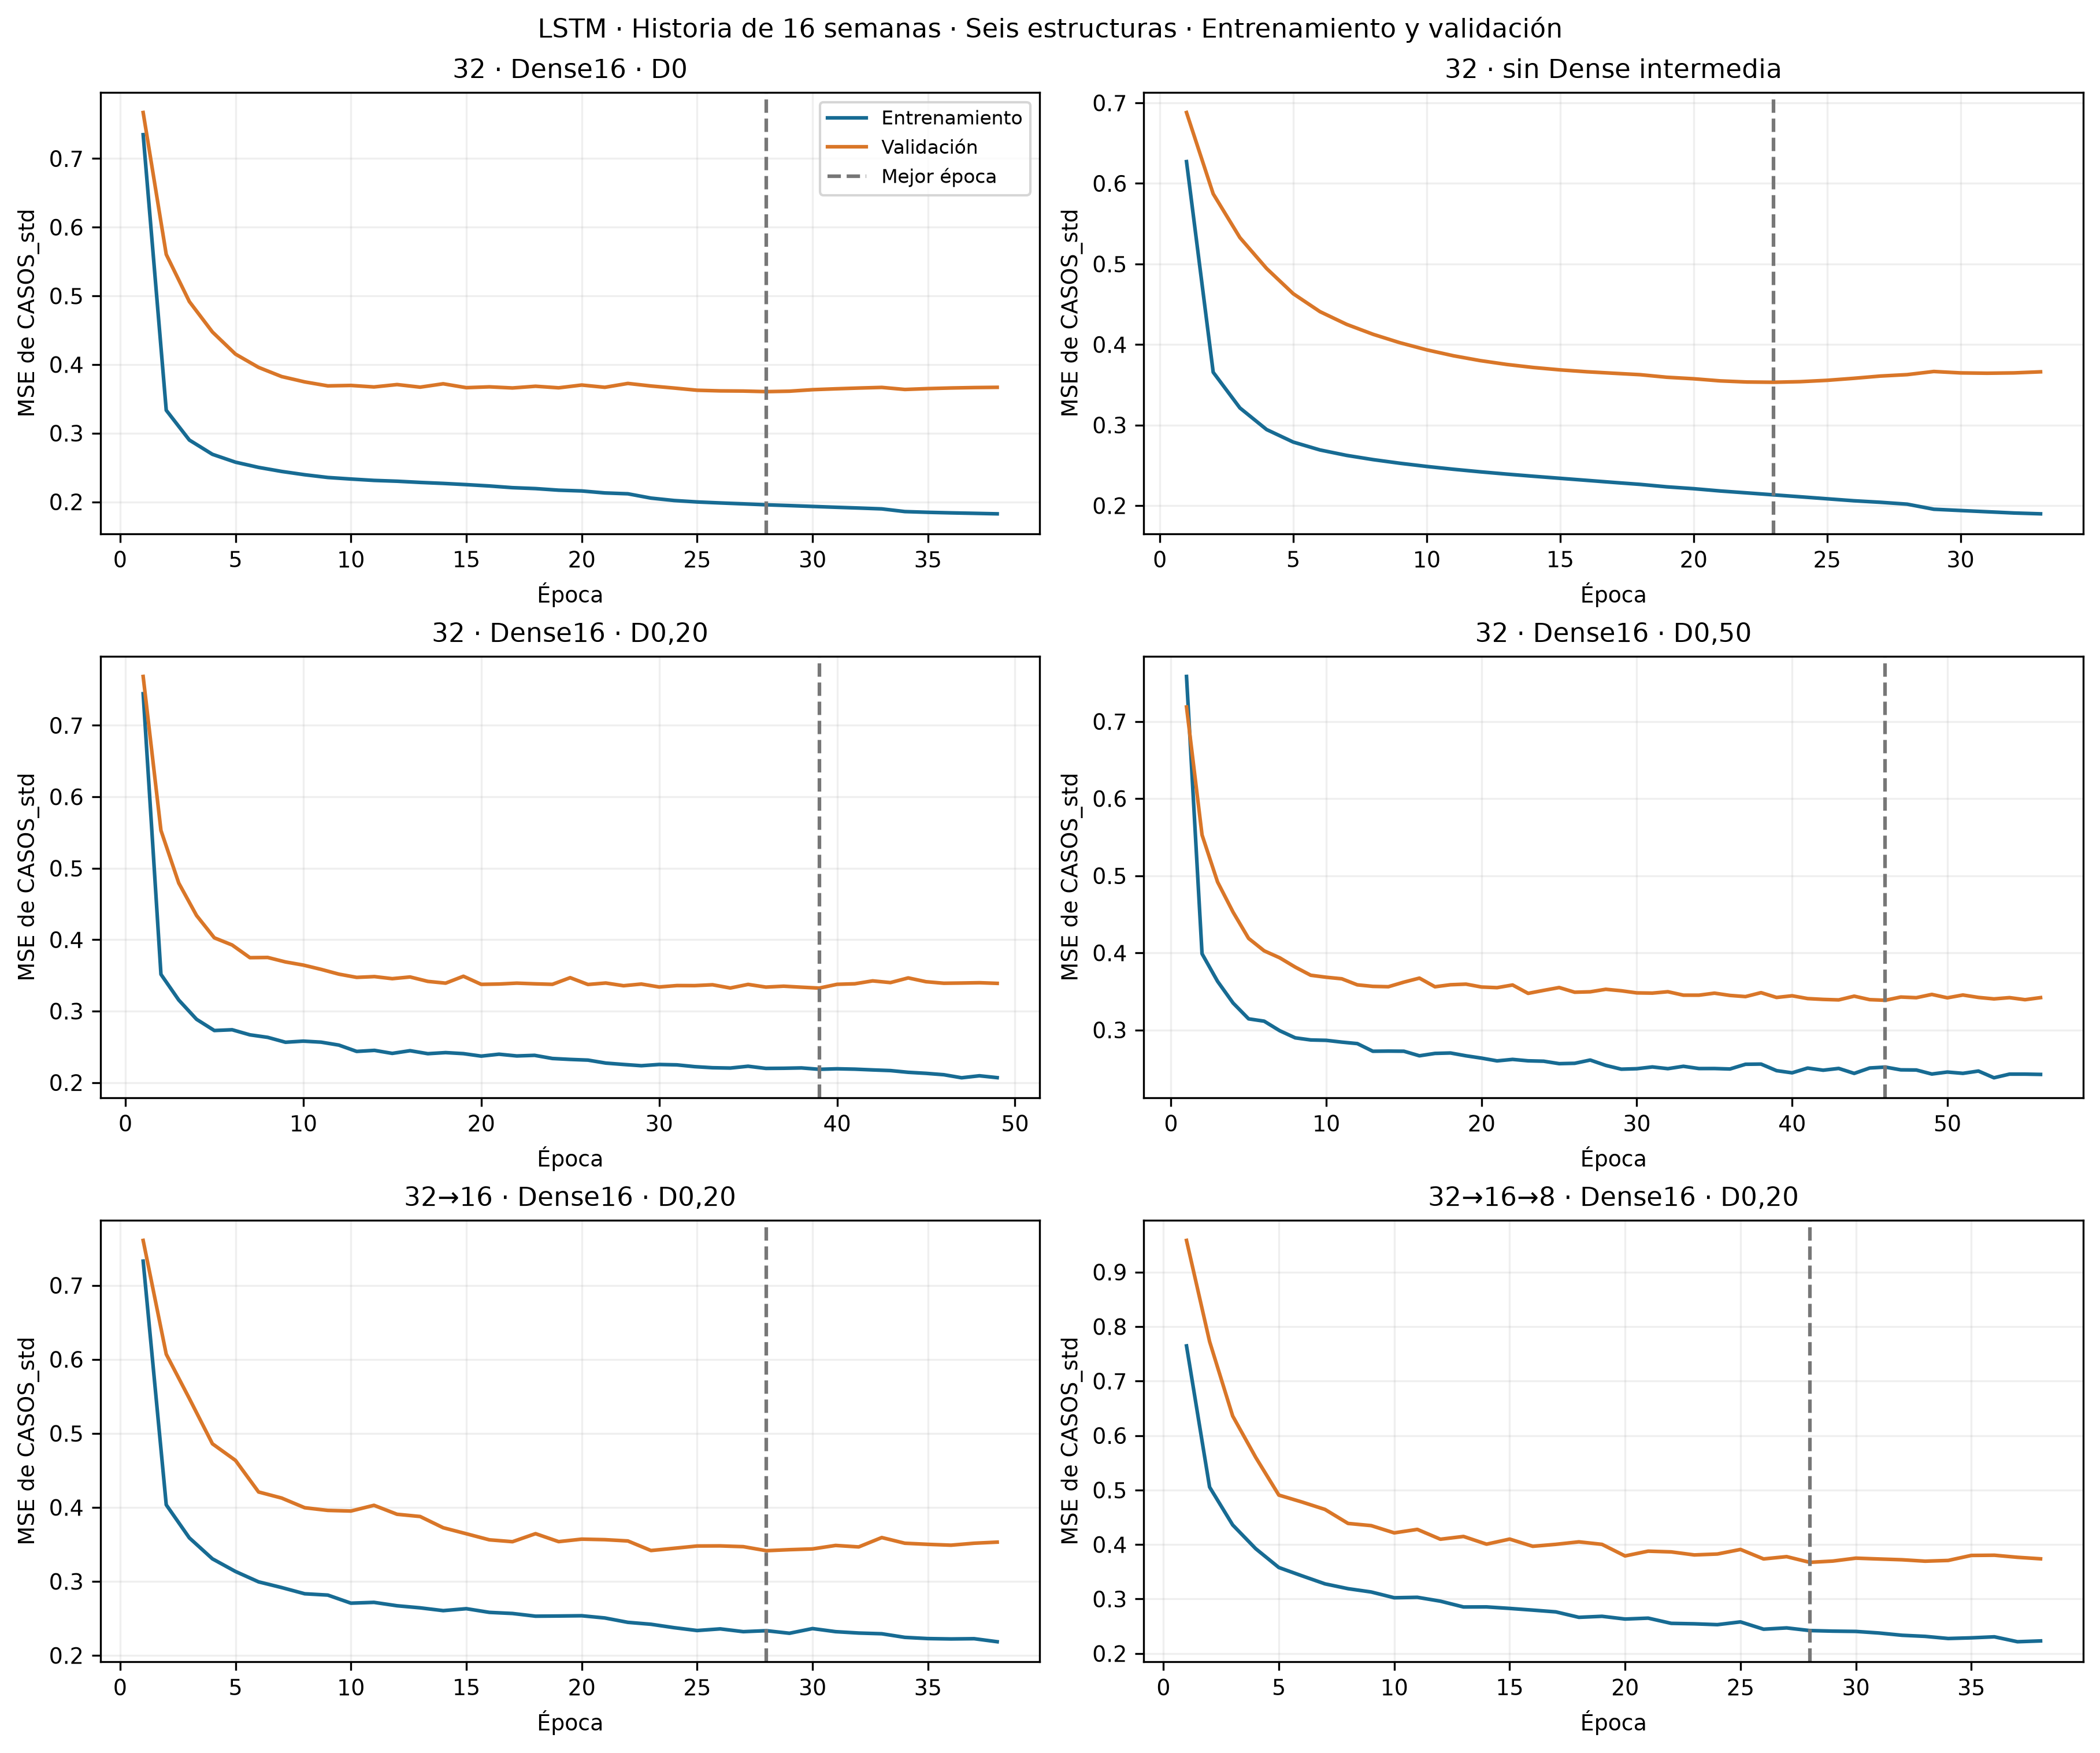

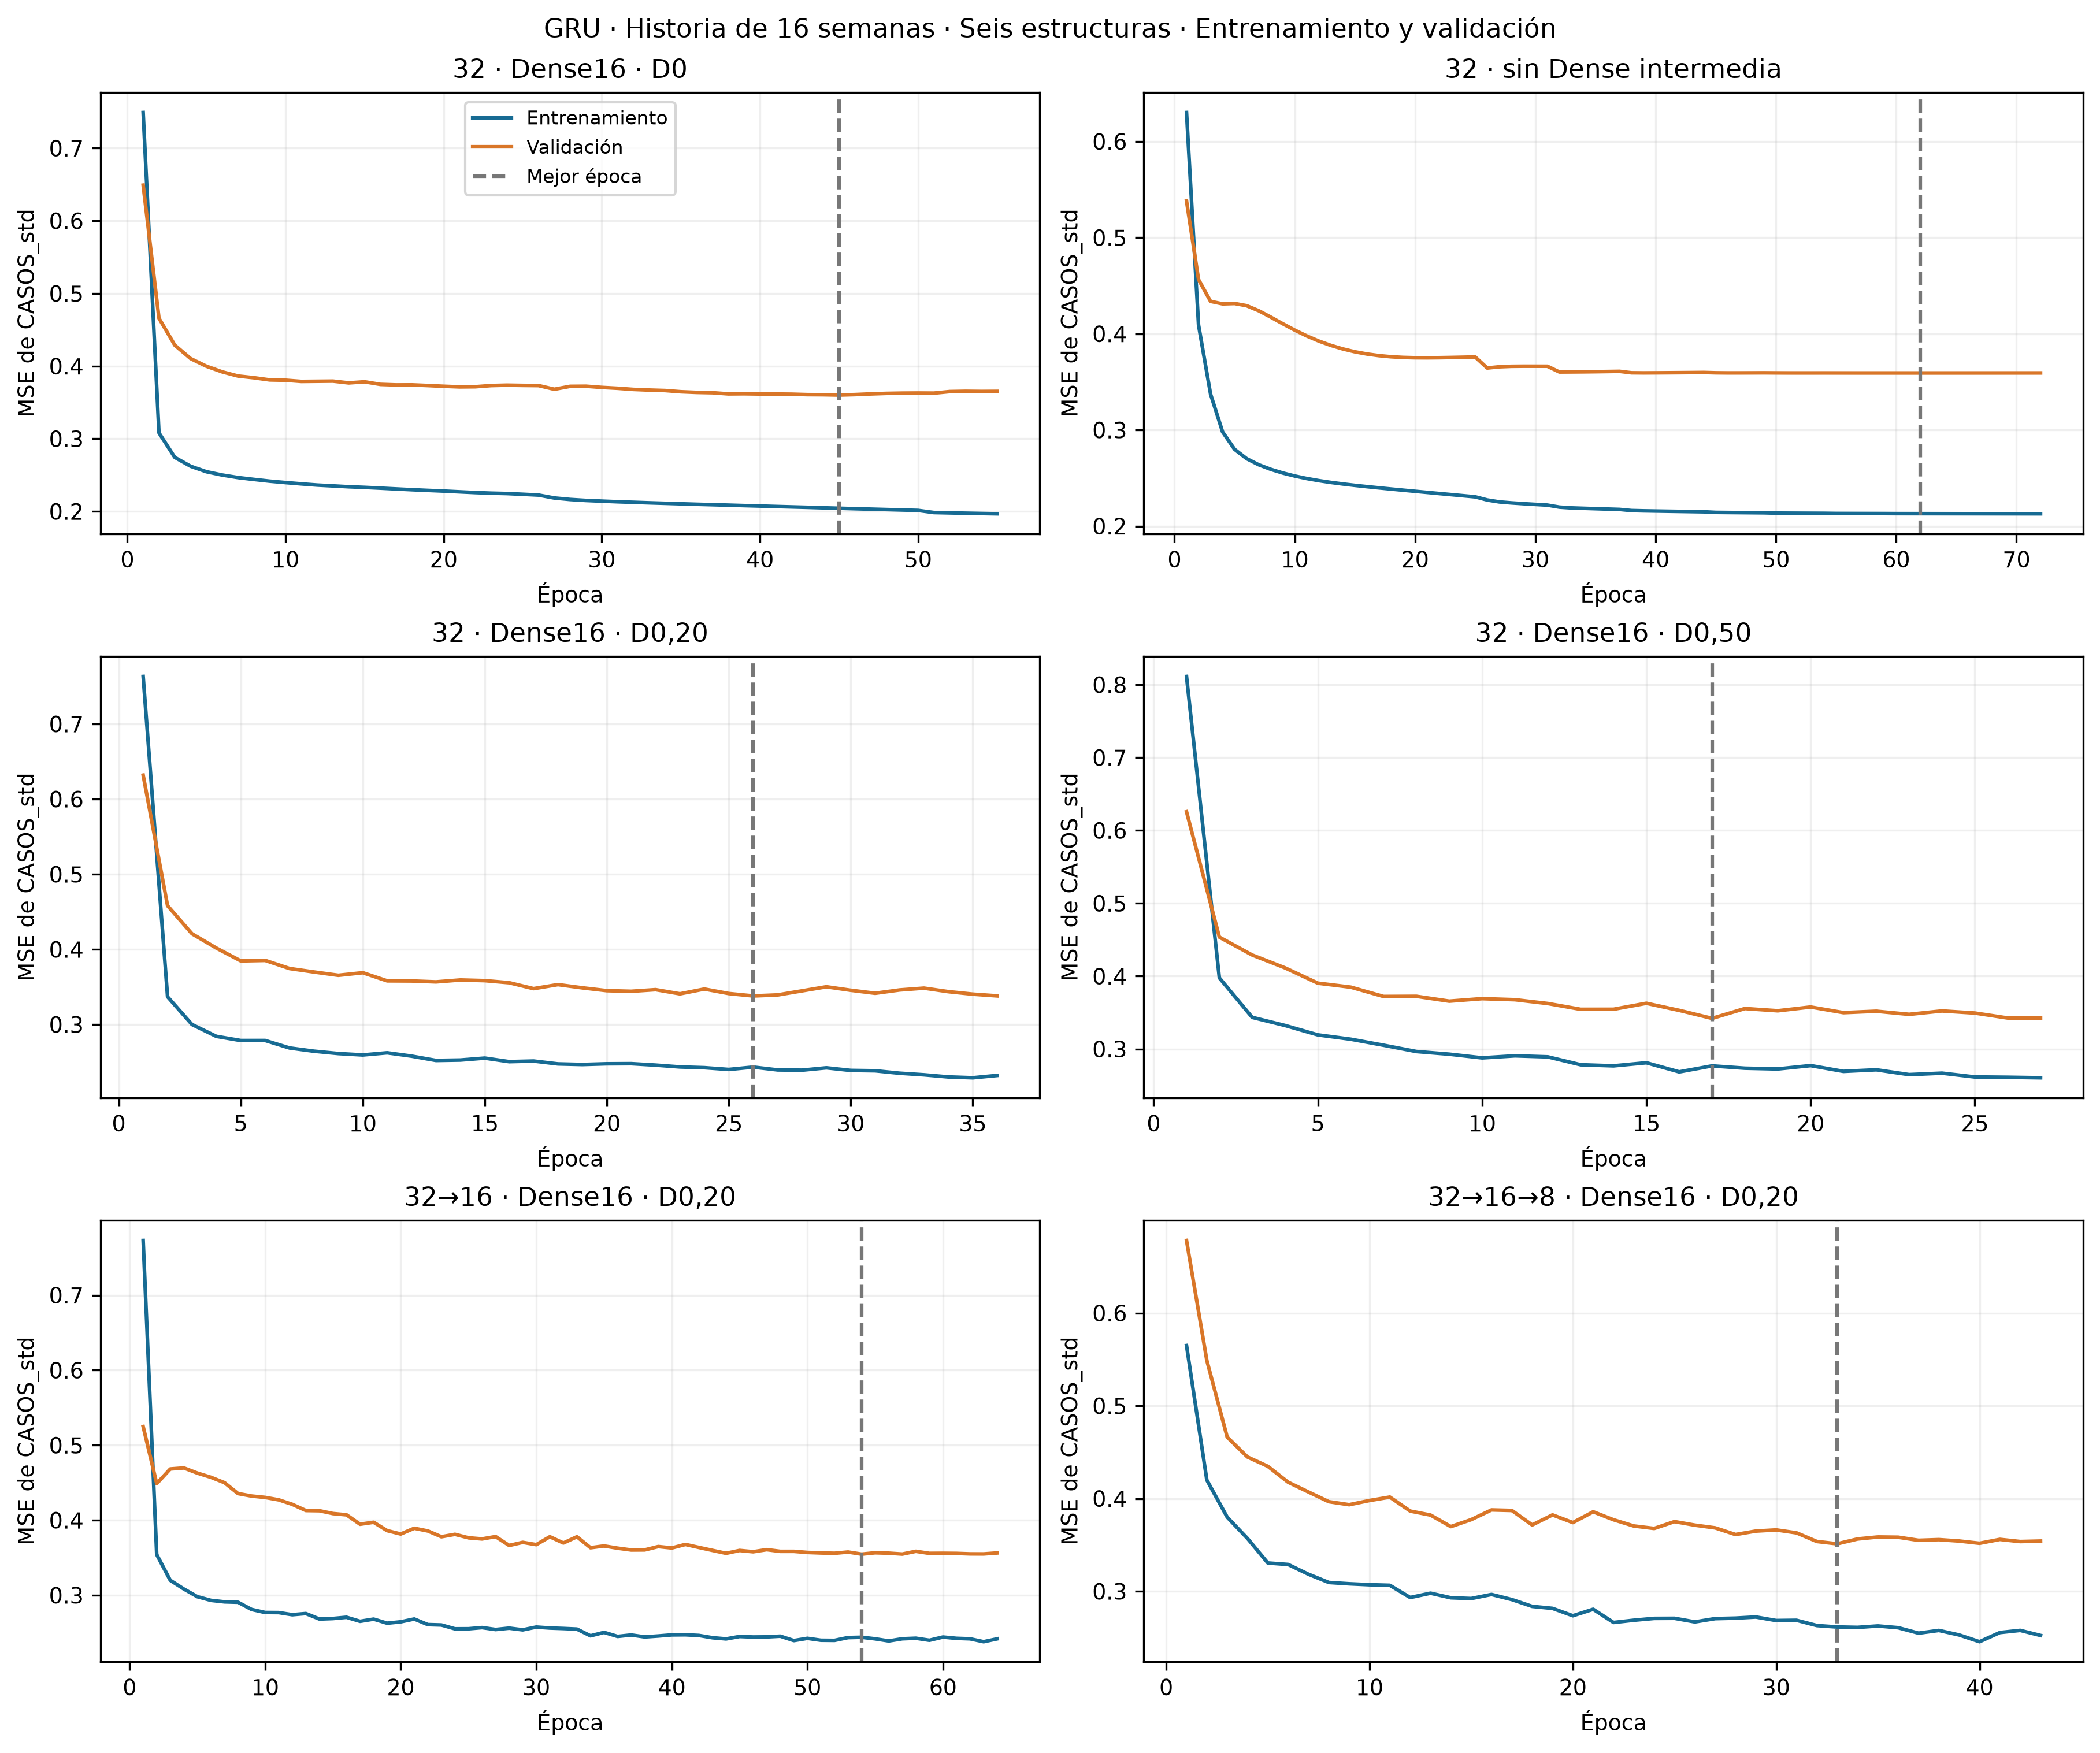

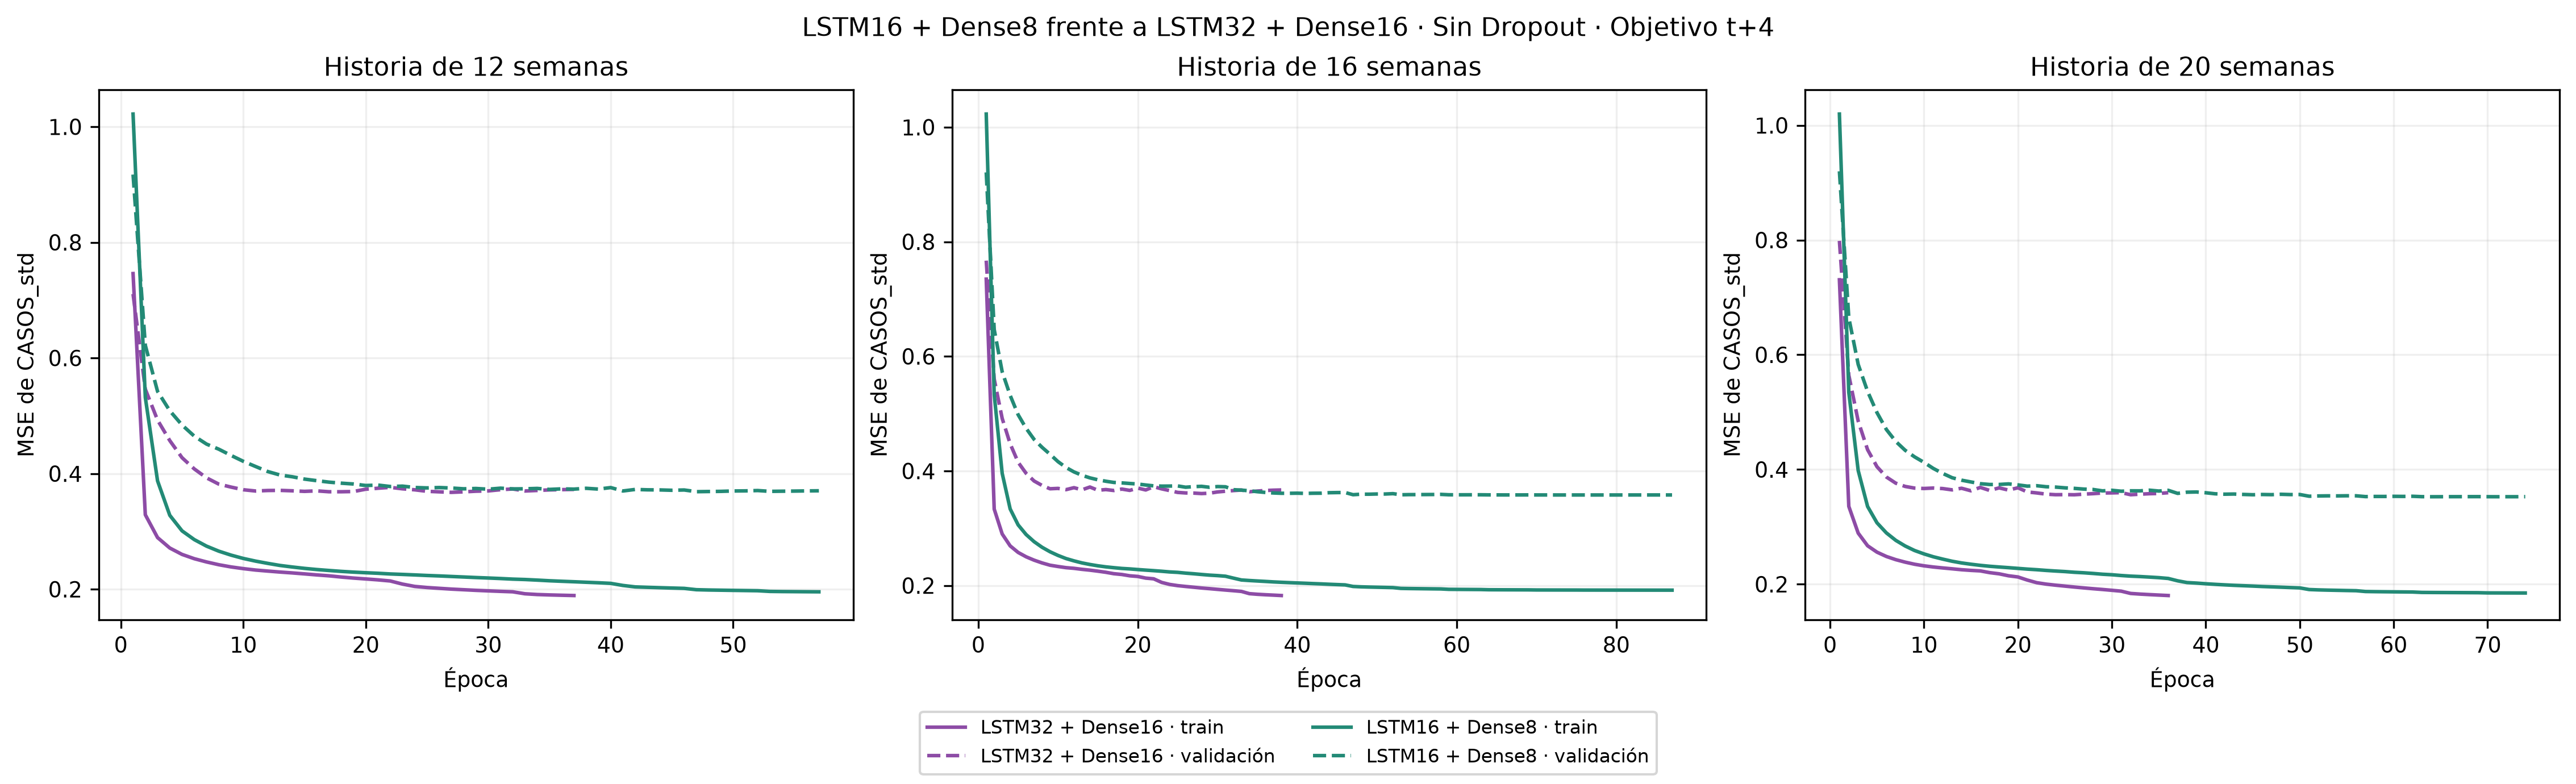

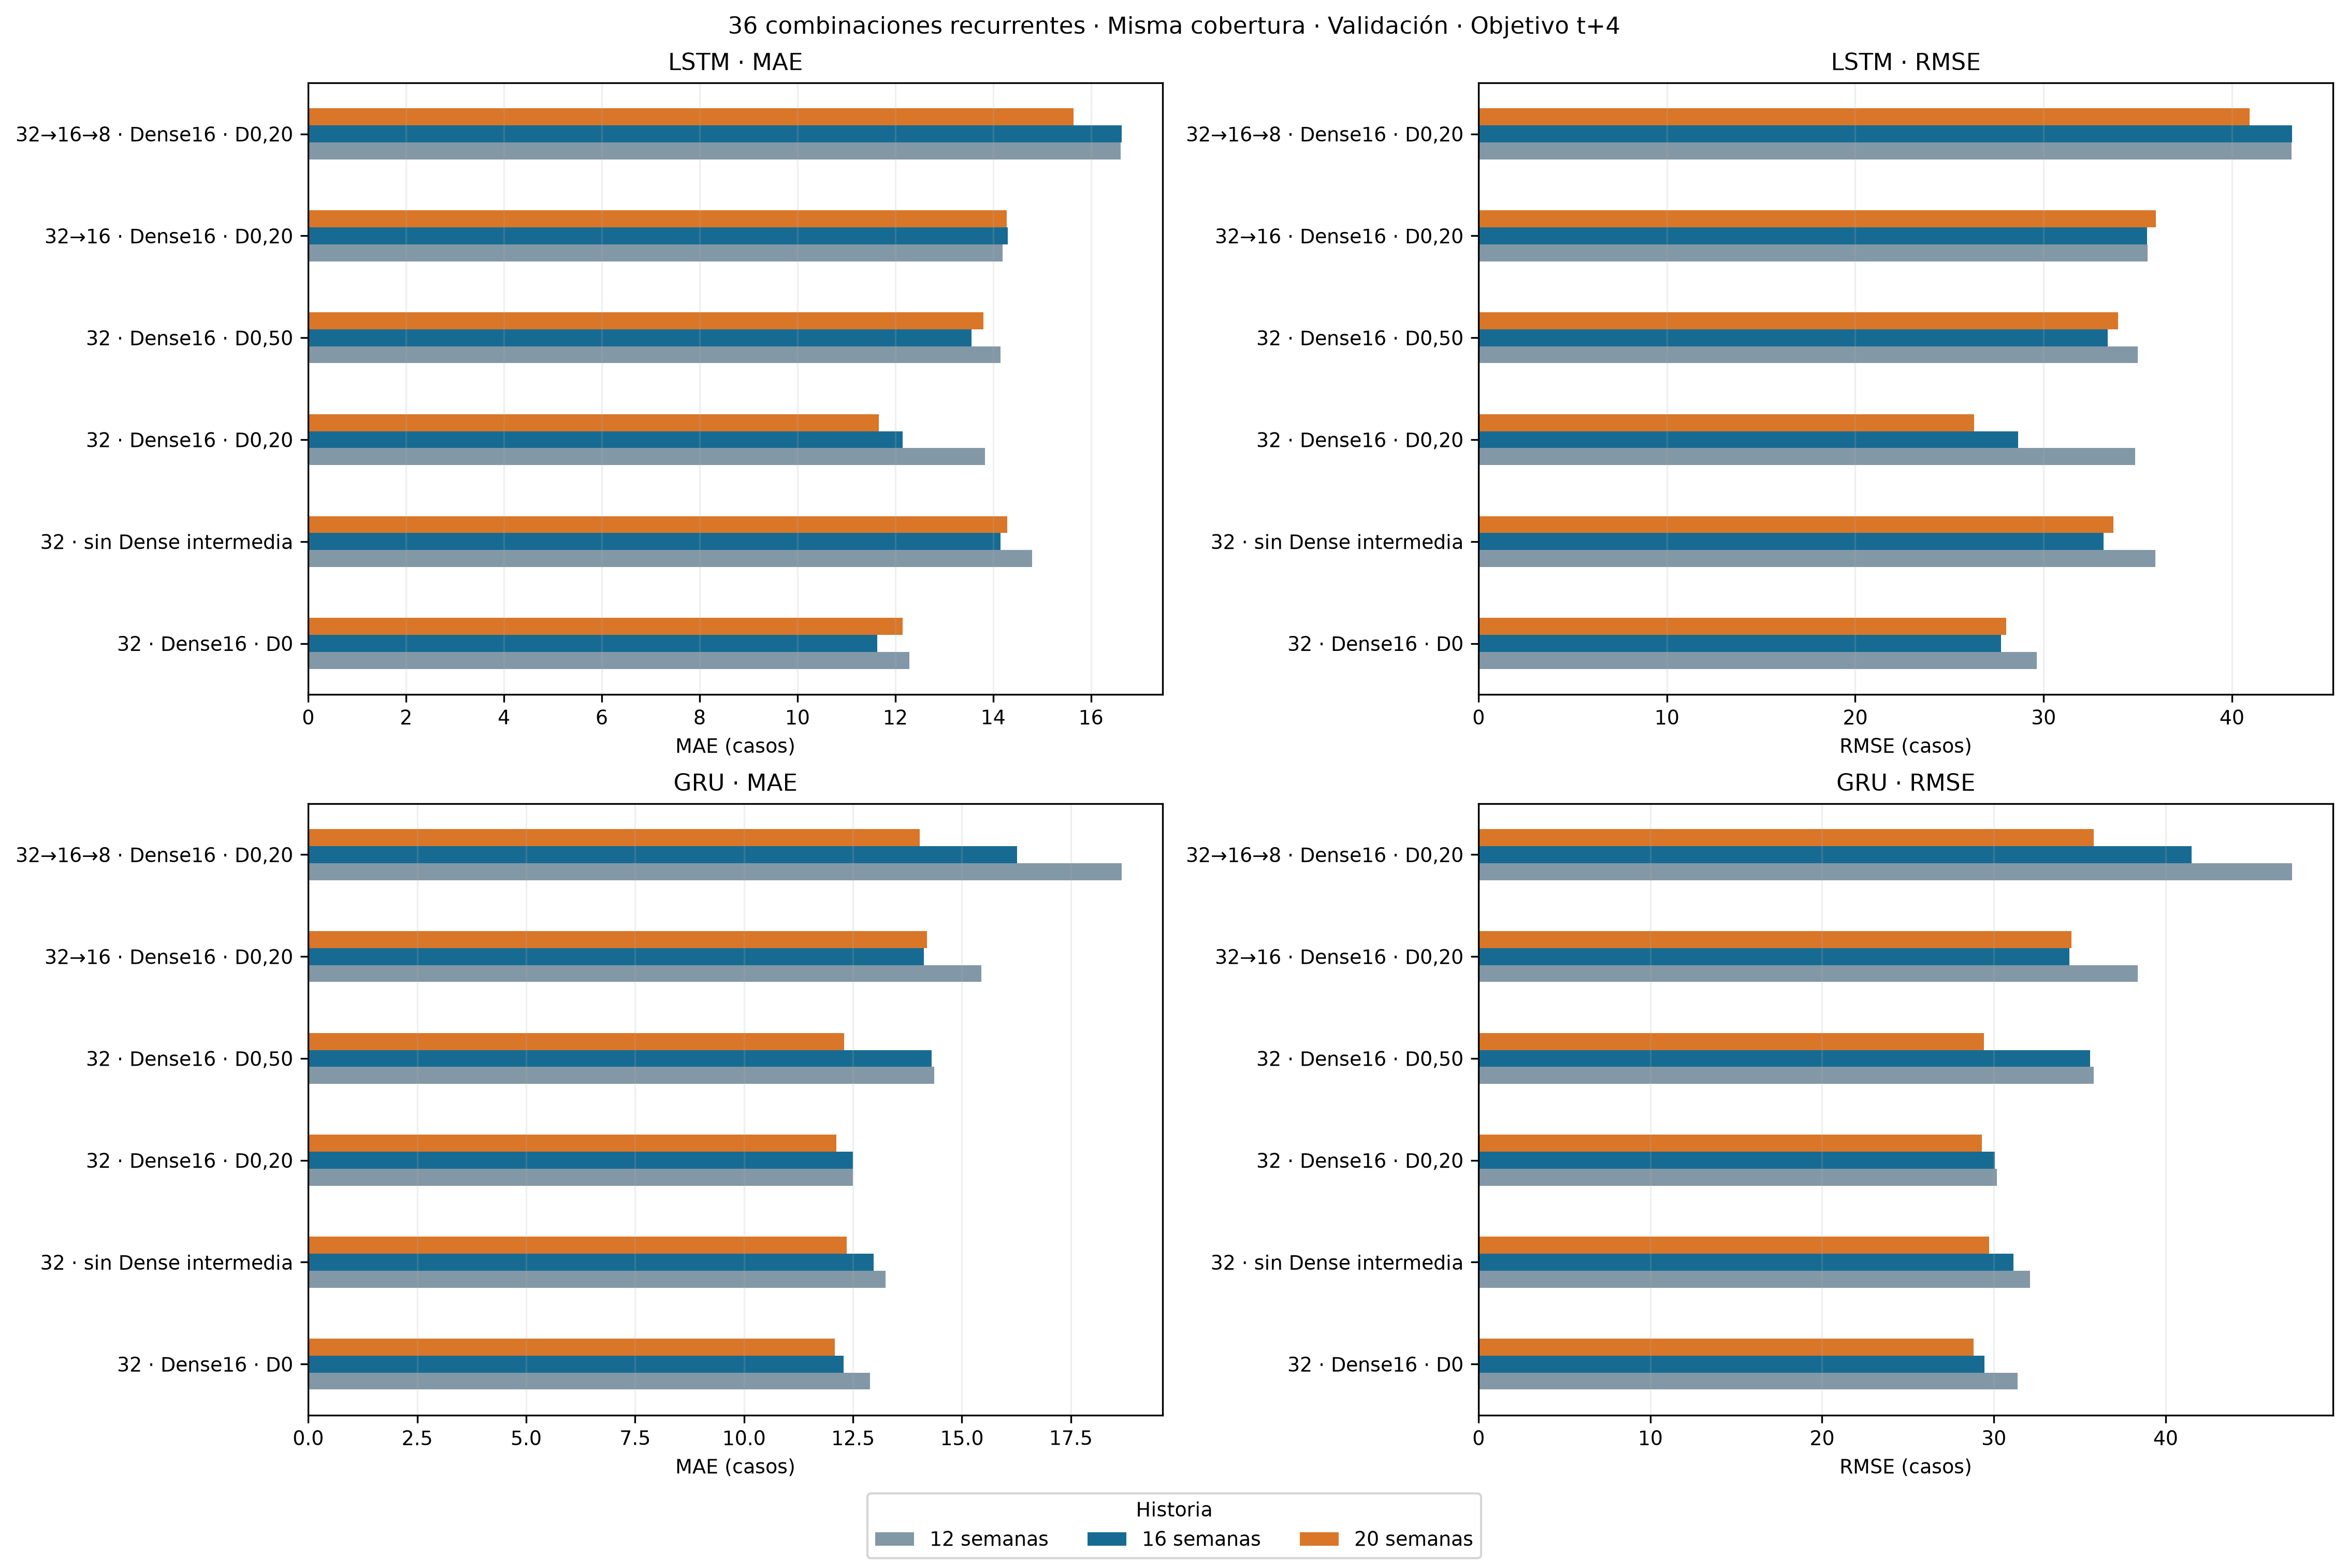

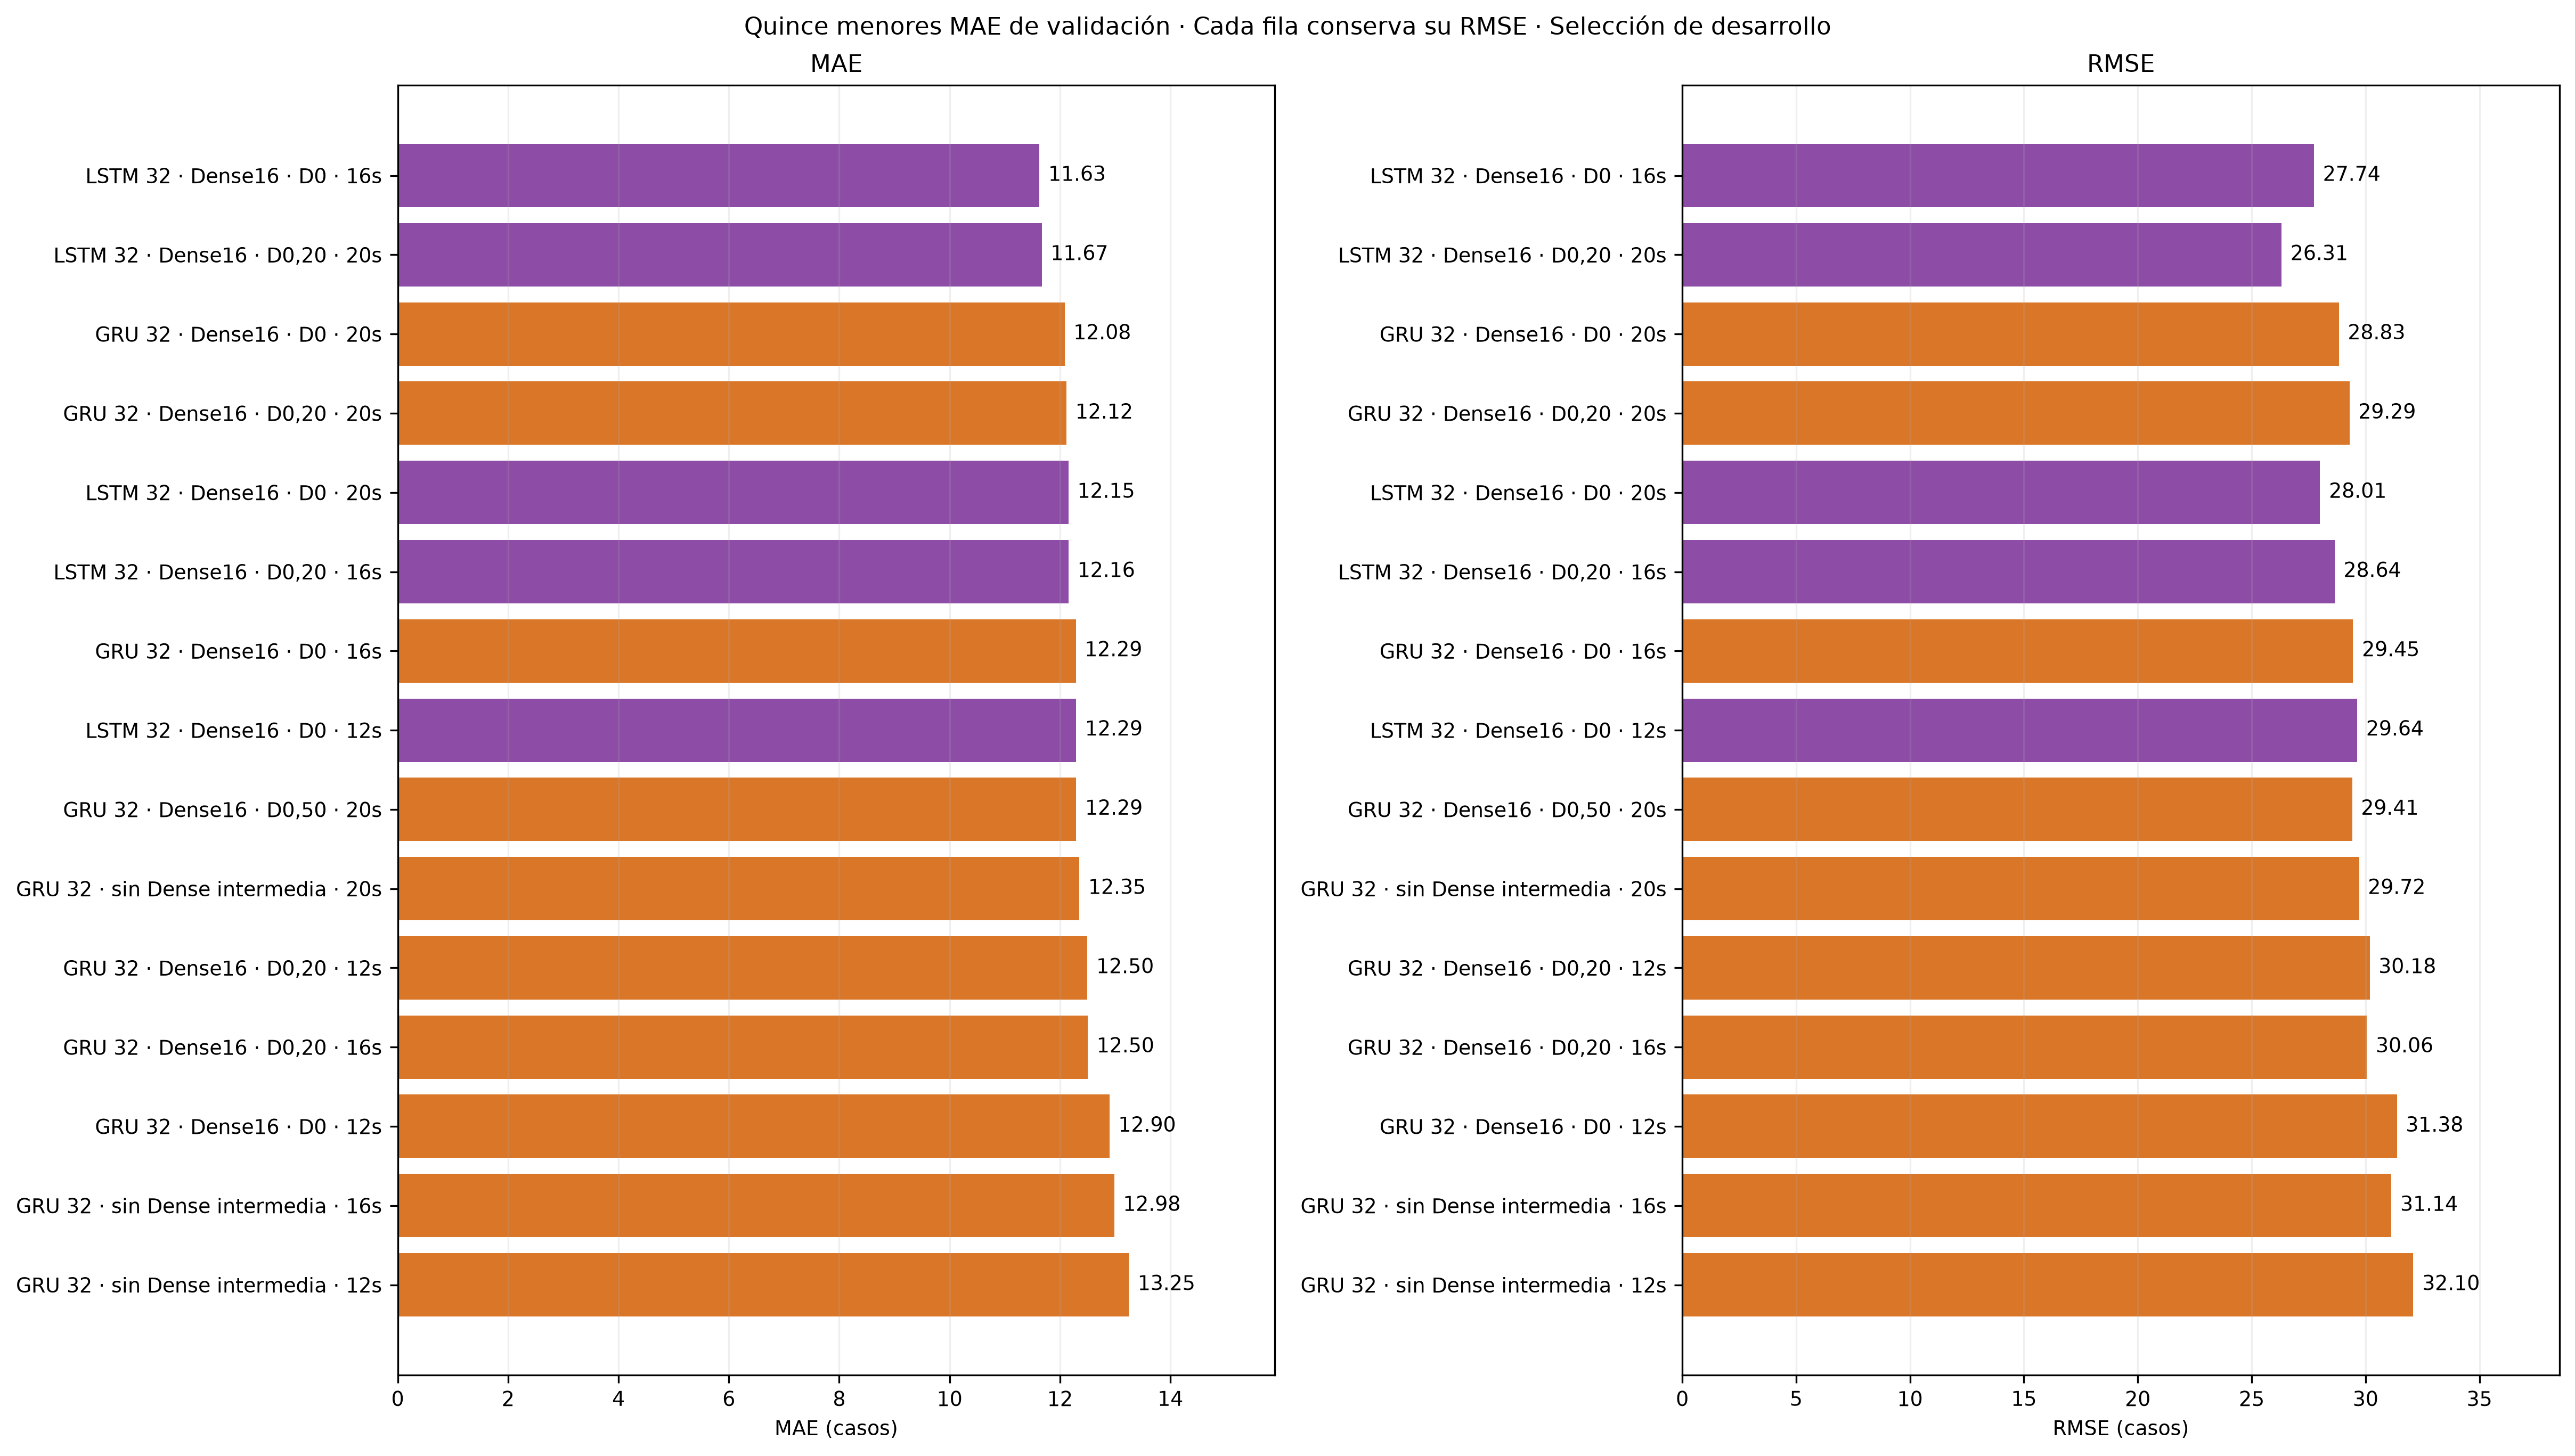

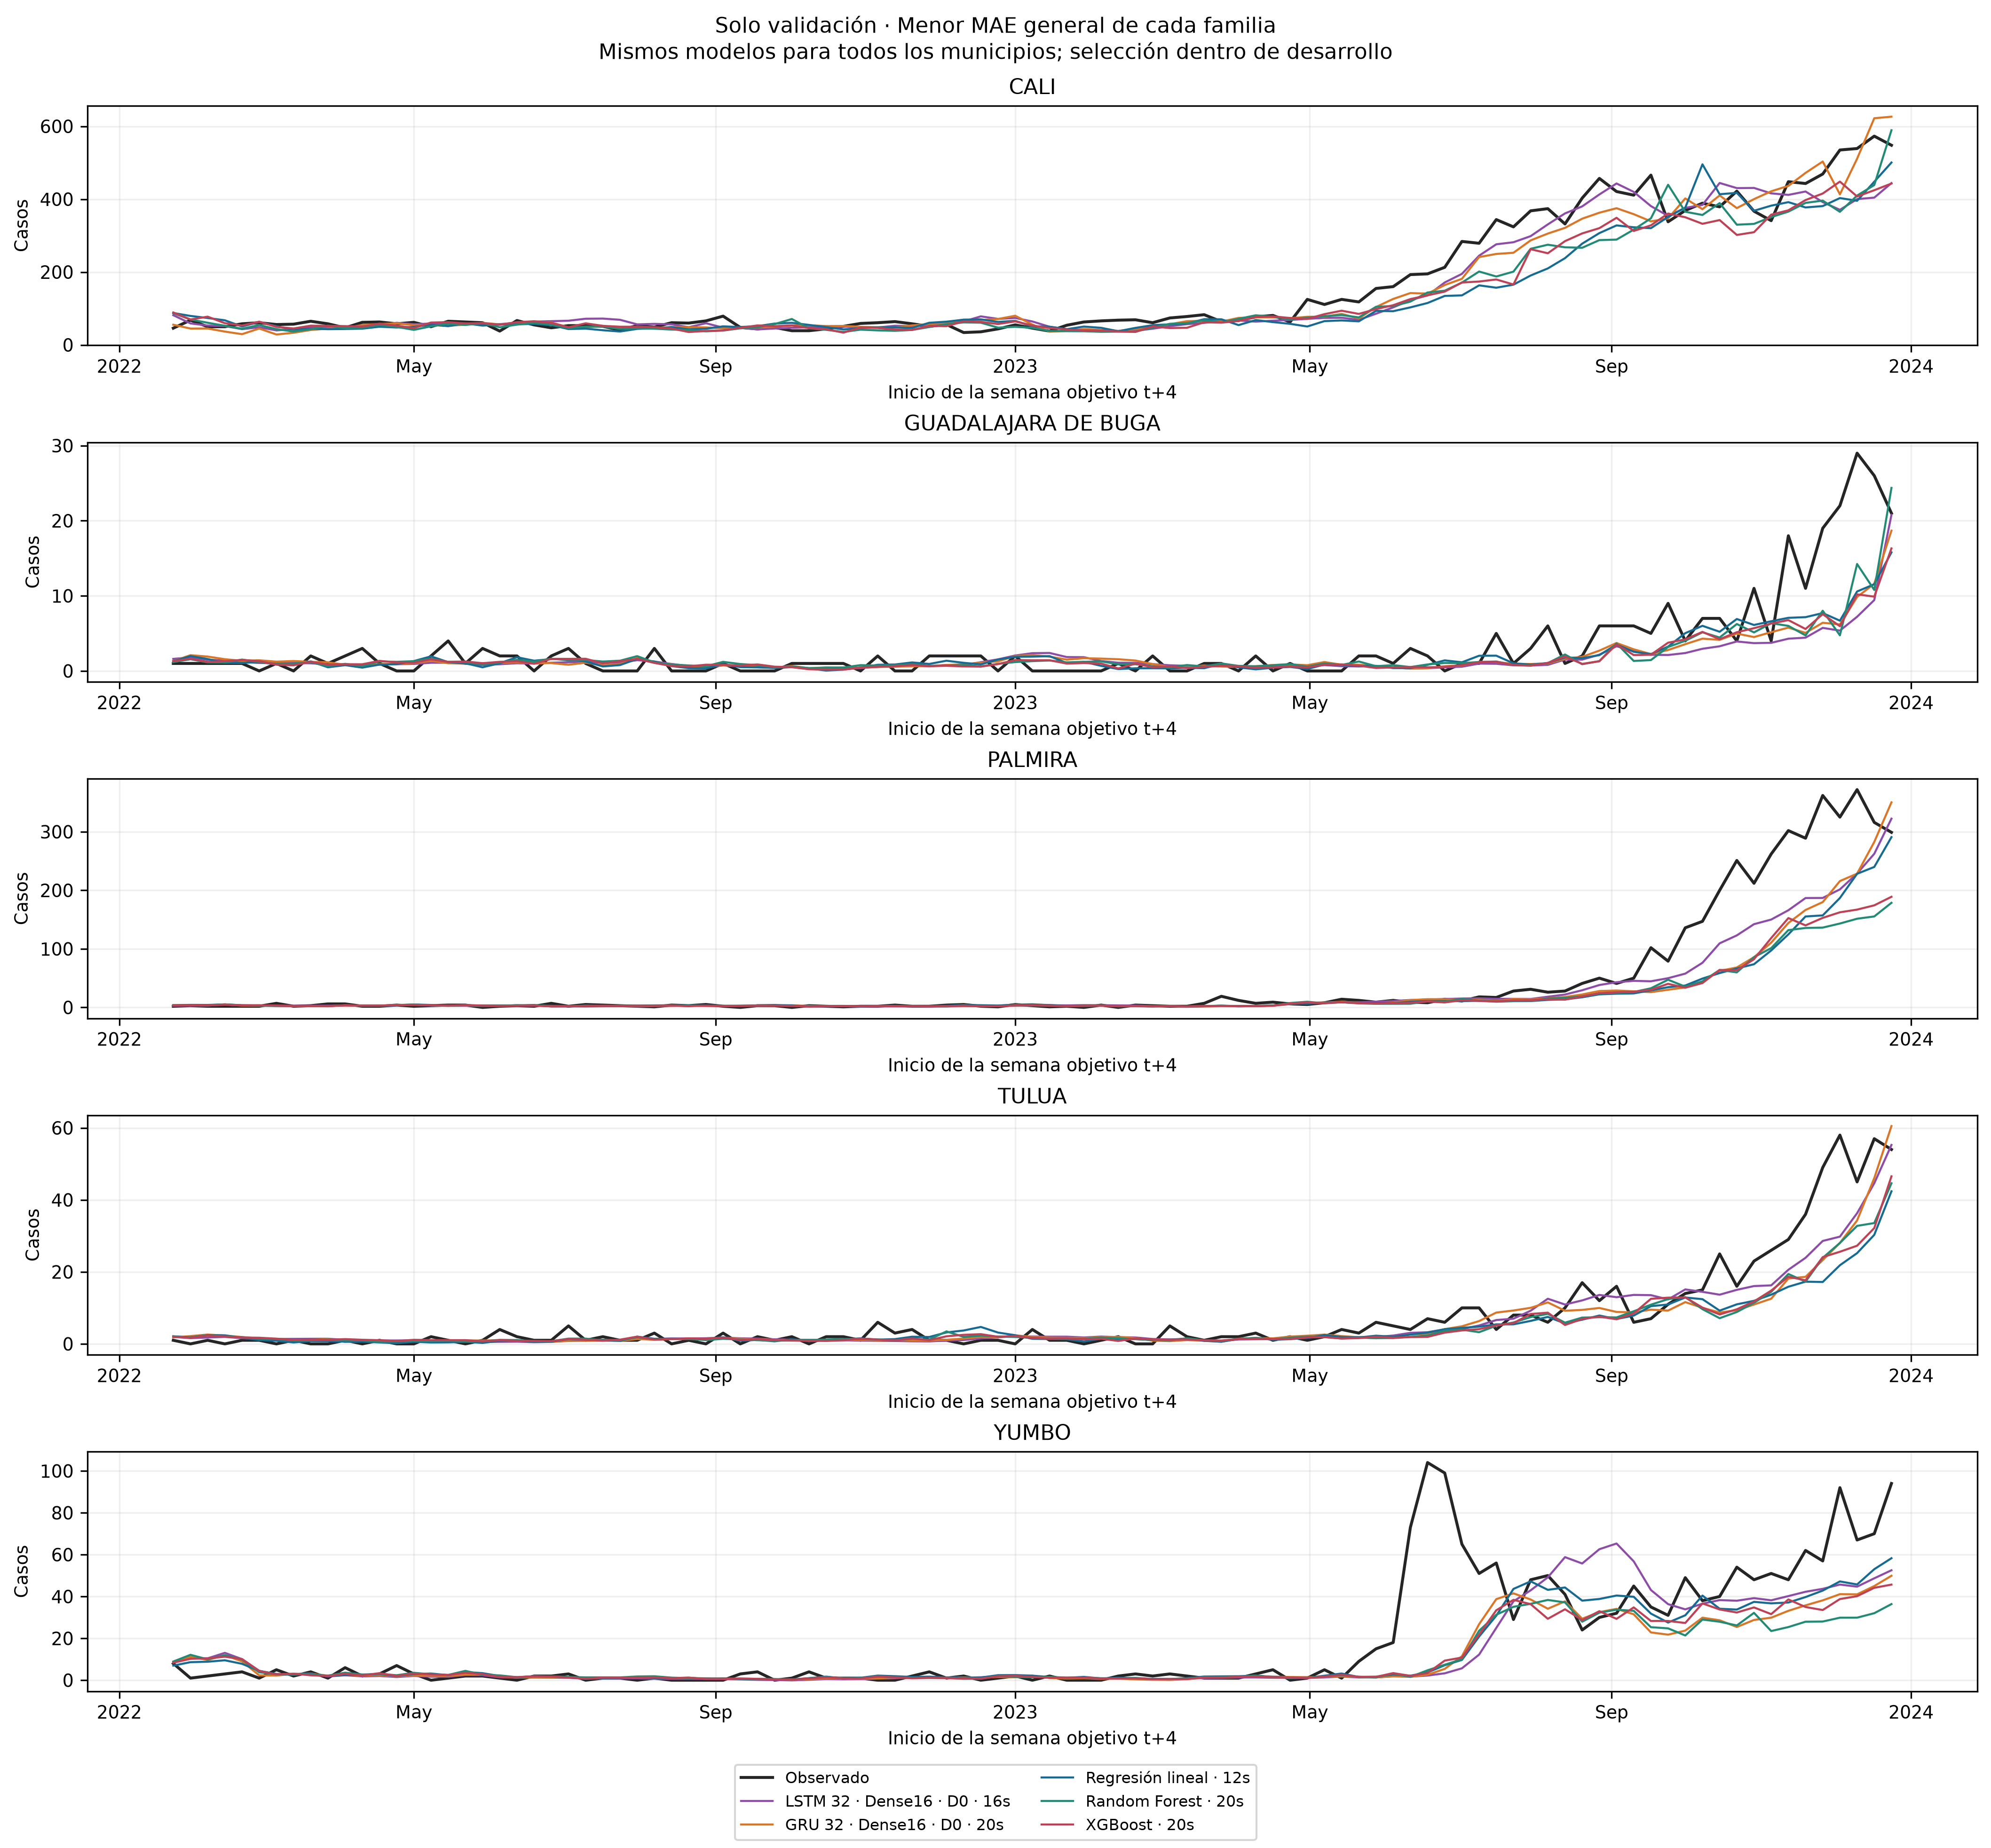

In [48]:
HISTORIA_PARA_CURVAS = 16
assert HISTORIA_PARA_CURVAS in HISTORIAS
for familia in ['lstm','gru']:
    display(Image(filename=str(RUTA_EJECUCION/f'figuras/curvas_{familia}_{HISTORIA_PARA_CURVAS}.png')))
for nombre in ['11_lstm_16_dense8','07_matriz_arquitecturas_historias','08_ranking_validacion_top15','09_series_solo_validacion']:
    display(Image(filename=str(RUTA_EJECUCION/'figuras'/f'{nombre}.png')))


### 18.2. Analizar la LSTM32 + Dense16 con Dropout de 0,20

Desde aquí continuamos con **LSTM32 + Dense16 + Dropout de 0,20, historia de 20 semanas y salida t+4**. Elegimos esta arquitectura por la preferencia de trabajar con regularización. Entre las tres historias probadas para esta misma variante, la de 20 semanas obtuvo tanto el menor MAE como el menor RMSE de validación.

Revisamos el modelo elegido frente al mínimo de MAE y frente a la LSTM sin Dropout de la misma historia. Después analizamos familias, municipios, sesgo, los dos años de validación y los pronósticos con mayores errores. Mantenemos un mismo baseline para las cinco ciudades: el de menor MAE general entre regresión lineal, Random Forest y XGBoost.

Todas las métricas están en casos de la semana t+4. El sesgo es pronosticado menos real: un valor negativo indica subestimación promedio. Los porcentajes de las tablas especifican si describen pronósticos, errores o cambios respecto al baseline.

In [2]:
# Elección explícita desde 18.2; el ranking y los mínimos observados se conservan.
ID_MODELO_ANALISIS = 'lstm_drop20_v20'
fila_modelo_elegido = ranking_validacion.loc[ranking_validacion['ID'].eq(ID_MODELO_ANALISIS)]
assert len(fila_modelo_elegido)==1
fila_modelo_elegido = fila_modelo_elegido.iloc[0]
especificacion_elegida = next(s for s in catalogo_actual if s['ID']==ID_MODELO_ANALISIS)
assert especificacion_elegida['ENTRENADO_EN_ESTA_EJECUCION']
assert especificacion_elegida['EJECUCION']==RUTA_EJECUCION.name
assert {k:especificacion_elegida['CONFIG'][k] for k in ['unidades','dense','dropout']}=={'unidades':[32], 'dense':16, 'dropout':.2}
assert int(fila_modelo_elegido['HISTORIA'])==20
archivo_seleccion_previa = RUTA_EJECUCION/'seleccion_hasta_18_1.json'
if not archivo_seleccion_previa.exists():
    archivo_seleccion_previa.write_text(json.dumps(seleccion_validacion,ensure_ascii=False,indent=2,
        default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')
seleccion_validacion = {**seleccion_validacion,
    'ID_ELEGIDO': ID_MODELO_ANALISIS,
    'MODELO_ELEGIDO': fila_modelo_elegido.to_dict(),
    'seleccion_manual': True,
    'criterio_principal': 'Elección de LSTM32 + Dense16 con Dropout 0,20; historia elegida con validación',
    'motivo_eleccion': 'Se prefiere la arquitectura con Dropout de 0,20 como opción regularizada. '
        'Entre sus historias de 12, 16 y 20 semanas, la de 20 obtuvo los menores MAE y RMSE de validación. '
        'La mejora de generalización se mantiene como hipótesis, no como un resultado demostrado.',
    'ID_MINIMO_MAE': ranking_validacion.loc[ranking_validacion['MAE'].idxmin(),'ID'],
    'ID_MINIMO_RMSE': ranking_validacion.loc[ranking_validacion['RMSE'].idxmin(),'ID'],
    'candidato_provisional': True,
    'test_consultado_en_esta_exploracion': False,
}
(RUTA_EJECUCION/'seleccion_validacion.json').write_text(json.dumps(seleccion_validacion,ensure_ascii=False,indent=2,
    default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')

analisis_validacion_18_2 = preparar_analisis_validacion(
    predicciones_desarrollo, metricas_desarrollo, metricas_municipales_desarrollo,
    ranking_validacion, seleccion_validacion)

comparacion_eleccion_validacion = analisis_validacion_18_2['tablas']['eleccion']
comparacion_familias_validacion = analisis_validacion_18_2['tablas']['familias']
detalle_municipal_validacion = analisis_validacion_18_2['tablas']['municipios']
comparacion_baseline_municipal = analisis_validacion_18_2['tablas']['frente_baseline']
resultados_validacion_por_ano = analisis_validacion_18_2['tablas']['por_ano']
ids_resumidos = ranking_validacion.head(6)['ID']
detalle_municipal = analisis_validacion_18_2['tablas']['mejores_configuraciones']
mayores_errores_validacion = analisis_validacion_18_2['tablas']['mayores_errores']

RUTA_ANALISIS_VALIDACION = RUTA_EJECUCION/'analisis_validacion'

def mostrar_tabla_validacion(tabla):
    formatos = {col: '{:.3f}' for col in tabla.select_dtypes(include='number').columns
        if col not in ['N','HISTORIA','ANO_OBJETIVO','CASOS_ORIGINALES']}
    formatos.update({col: '{:%Y-%m-%d}' for col in ['FECHA_EMISION','FECHA_OBJETIVO'] if col in tabla.columns})
    display(tabla.style.format(formatos, na_rep='No aplica').hide(axis='index'))

#### 18.2.1. Comparar las familias y revisar el candidato

Desde este punto analizamos **LSTM 32 · Dense16 · D0,20 · 20s**, con **MAE 11.669** y **RMSE 26.314 casos** en 505 pronósticos de t+4. **Motivo de la elección:** Se prefiere la arquitectura con Dropout de 0,20 como opción regularizada. Entre sus historias de 12, 16 y 20 semanas, la de 20 obtuvo los menores MAE y RMSE de validación. La mejora de generalización se mantiene como hipótesis, no como un resultado demostrado.

El mínimo de MAE sigue siendo **LSTM 32 · Dense16 · D0 · 16s**, con MAE 11.627 y RMSE 27.738. Frente a esa referencia, el MAE del modelo elegido es un 0.36% mayor y su RMSE es un 5.13% menor. La primera tabla distingue la elección del mínimo de MAE y permite contrastar, cuando corresponde, la red sin Dropout con la misma cantidad de historia.

El baseline con menor MAE general es **XGBoost · 20s**: MAE 14.619 y RMSE 36.031. Frente a él, el MAE del candidato es un 20.18% menor y su RMSE es un 26.97% menor.

El menor RMSE general corresponde a **LSTM 32 · Dense16 · D0,20 · 20s** (26.314). La tabla por familias conserva sus referencias de menor MAE y añade el modelo elegido, identificado en la columna ROL. Las columnas de entrenamiento describen el ajuste sobre datos ya vistos; su diferencia con validación también puede reflejar cambios entre periodos y no demuestra por sí sola sobreajuste.

Dropout es una forma de regularización y aquí motiva la elección de la arquitectura. Estos resultados no prueban que generalice mejor: para estudiar esa hipótesis harían falta otros cortes temporales o semillas, sin utilizar evaluación para ajustar la decisión.

In [2]:
display(comparacion_eleccion_validacion[['ROL','MODELO','HISTORIA','PARAMETROS_RED','MAE','RMSE']].style.format(
    {'PARAMETROS_RED':'{:.0f}','MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))

ROL,MODELO,HISTORIA,PARAMETROS_RED,MAE,RMSE
Modelo elegido,"LSTM 32 · Dense16 · D0,20 · 20s",20,5745,11.669,26.314
Menor MAE general,LSTM 32 · Dense16 · D0 · 16s,16,5745,11.627,27.738
"Sin Dropout, misma historia",LSTM 32 · Dense16 · D0 · 20s,20,5745,12.154,28.005


**Referencias por familia y modelo elegido.**

In [2]:
mostrar_tabla_validacion(comparacion_familias_validacion[
    ['ROL','FAMILIA','MODELO','HISTORIA','N','MAE_TRAIN','RMSE_TRAIN','MAE_VAL','RMSE_VAL']])

ROL,FAMILIA,MODELO,HISTORIA,N,MAE_TRAIN,RMSE_TRAIN,MAE_VAL,RMSE_VAL
Menor MAE de su familia,LSTM,LSTM 32 · Dense16 · D0 · 16s,16,505,7.962,23.023,11.627,27.738
Menor MAE de su familia,GRU,GRU 32 · Dense16 · D0 · 20s,20,505,8.392,24.703,12.083,28.829
Menor MAE de su familia,XGBoost,XGBoost · 20s,20,505,8.106,23.551,14.619,36.031
Menor MAE de su familia,Regresión lineal,Regresión lineal · 12s,12,505,10.603,31.420,14.881,37.025
Menor MAE de su familia,Random Forest,Random Forest · 20s,20,505,5.073,14.590,15.086,37.653
Menor MAE de su familia,LSTM local,LSTM local (5 redes) · 20s,20,505,7.118,19.869,15.178,37.697
Modelo elegido para el análisis,LSTM,"LSTM 32 · Dense16 · D0,20 · 20s",20,505,8.300,24.626,11.669,26.314


#### 18.2.2. Revisar el error y el sesgo por municipio

El MAE va de **1.839 en GUADALAJARA DE BUGA** a **31.329 en CALI**. Los dos mayores aportes al error absoluto son CALI y PALMIRA: juntos representan **78.55%** de ese error.

Cada fila conserva el número de pronósticos y el promedio de casos observados. Un MAE pequeño en un municipio con pocos casos no demuestra una mejor precisión proporcional. El aporte al error indica qué municipios pesan más en la suma de errores absolutos; no es una medida de importancia sanitaria ni una tasa ajustada por población.

En el conjunto completo, el candidato **subestima en 6.138 casos por pronóstico, en promedio**. El 58.42% de sus predicciones queda por debajo del valor real con una diferencia mayor que 0,001 casos. Un sesgo negativo indica subestimación y uno positivo, sobreestimación; no implica que todos los errores tengan el mismo signo. El candidato no produjo pronósticos negativos en validación.

In [2]:
mostrar_tabla_validacion(detalle_municipal_validacion[
    ['MUNICIPIO','N','CASOS_MEDIOS','MAE','RMSE','SESGO_MEDIO','SUBESTIMACION_PCT','APORTE_ERROR_PCT']])

MUNICIPIO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO,SUBESTIMACION_PCT,APORTE_ERROR_PCT
CALI,101,156.178,31.329,43.448,-10.910,66.337,53.695
GUADALAJARA DE BUGA,101,3.050,1.839,3.147,-0.966,55.446,3.153
PALMIRA,101,42.683,14.502,34.353,-11.369,57.426,24.856
TULUA,101,6.931,2.575,4.695,-1.351,53.465,4.414
YUMBO,101,17.347,8.100,19.038,-6.093,59.406,13.882


**Detalle de las seis configuraciones con menor MAE general.**

Se conserva el detalle municipal de las seis configuraciones con menor MAE general. Estas filas permiten contrastar alternativas; el modelo elegido para el análisis se mantiene fijo.

In [2]:
display(detalle_municipal[['MODELO','MUNICIPIO','N','MAE','RMSE','SESGO_MEDIO']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:.3f}'}).hide(axis='index'))

MODELO,MUNICIPIO,N,MAE,RMSE,SESGO_MEDIO
LSTM 32 · Dense16 · D0 · 16s,CALI,101,28.144,42.820,-14.839
LSTM 32 · Dense16 · D0 · 16s,GUADALAJARA DE BUGA,101,2.084,4.169,-1.390
LSTM 32 · Dense16 · D0 · 16s,PALMIRA,101,16.062,39.507,-14.421
LSTM 32 · Dense16 · D0 · 16s,TULUA,101,2.600,4.858,-1.292
LSTM 32 · Dense16 · D0 · 16s,YUMBO,101,9.246,20.291,-5.086
"LSTM 32 · Dense16 · D0,20 · 20s",CALI,101,31.329,43.448,-10.910
"LSTM 32 · Dense16 · D0,20 · 20s",GUADALAJARA DE BUGA,101,1.839,3.147,-0.966
"LSTM 32 · Dense16 · D0,20 · 20s",PALMIRA,101,14.502,34.353,-11.369
"LSTM 32 · Dense16 · D0,20 · 20s",TULUA,101,2.575,4.695,-1.351
"LSTM 32 · Dense16 · D0,20 · 20s",YUMBO,101,8.100,19.038,-6.093


#### 18.2.3. Comparar con el mismo baseline en las cinco ciudades

Comparamos **LSTM 32 · Dense16 · D0,20 · 20s** con **XGBoost · 20s** en todas las ciudades. El candidato mantiene la elección registrada arriba y el baseline se fija por su menor MAE general. El candidato tiene menor MAE en **5 de 5 municipios** y menor RMSE en **5 de 5**. 

Las diferencias se calculan como baseline menos candidato: un valor positivo favorece al candidato y uno negativo, al baseline. La reducción porcentual de MAE usa el error del baseline como referencia; no es un porcentaje del número de casos. Mantenemos los mismos dos modelos para todas las ciudades.

MUNICIPIO,MAE_CANDIDATO,MAE_BASELINE,DIFERENCIA_MAE,REDUCCION_MAE_PCT,RMSE_CANDIDATO,RMSE_BASELINE,DIFERENCIA_RMSE
CALI,31.329,35.594,4.265,11.983,43.448,54.452,11.004
GUADALAJARA DE BUGA,1.839,1.967,0.128,6.489,3.147,3.768,0.621
PALMIRA,14.502,23.290,8.788,37.732,34.353,55.556,21.203
TULUA,2.575,3.394,0.818,24.112,4.695,6.505,1.809
YUMBO,8.100,8.848,0.748,8.455,19.038,19.577,0.539


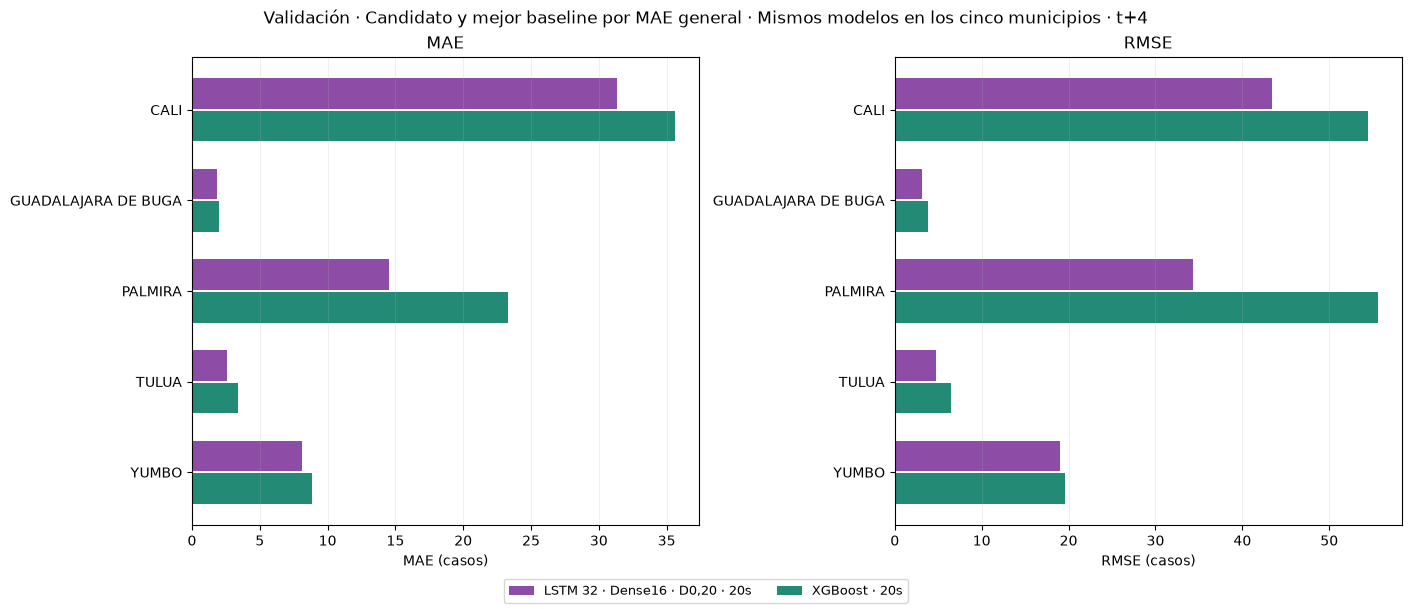

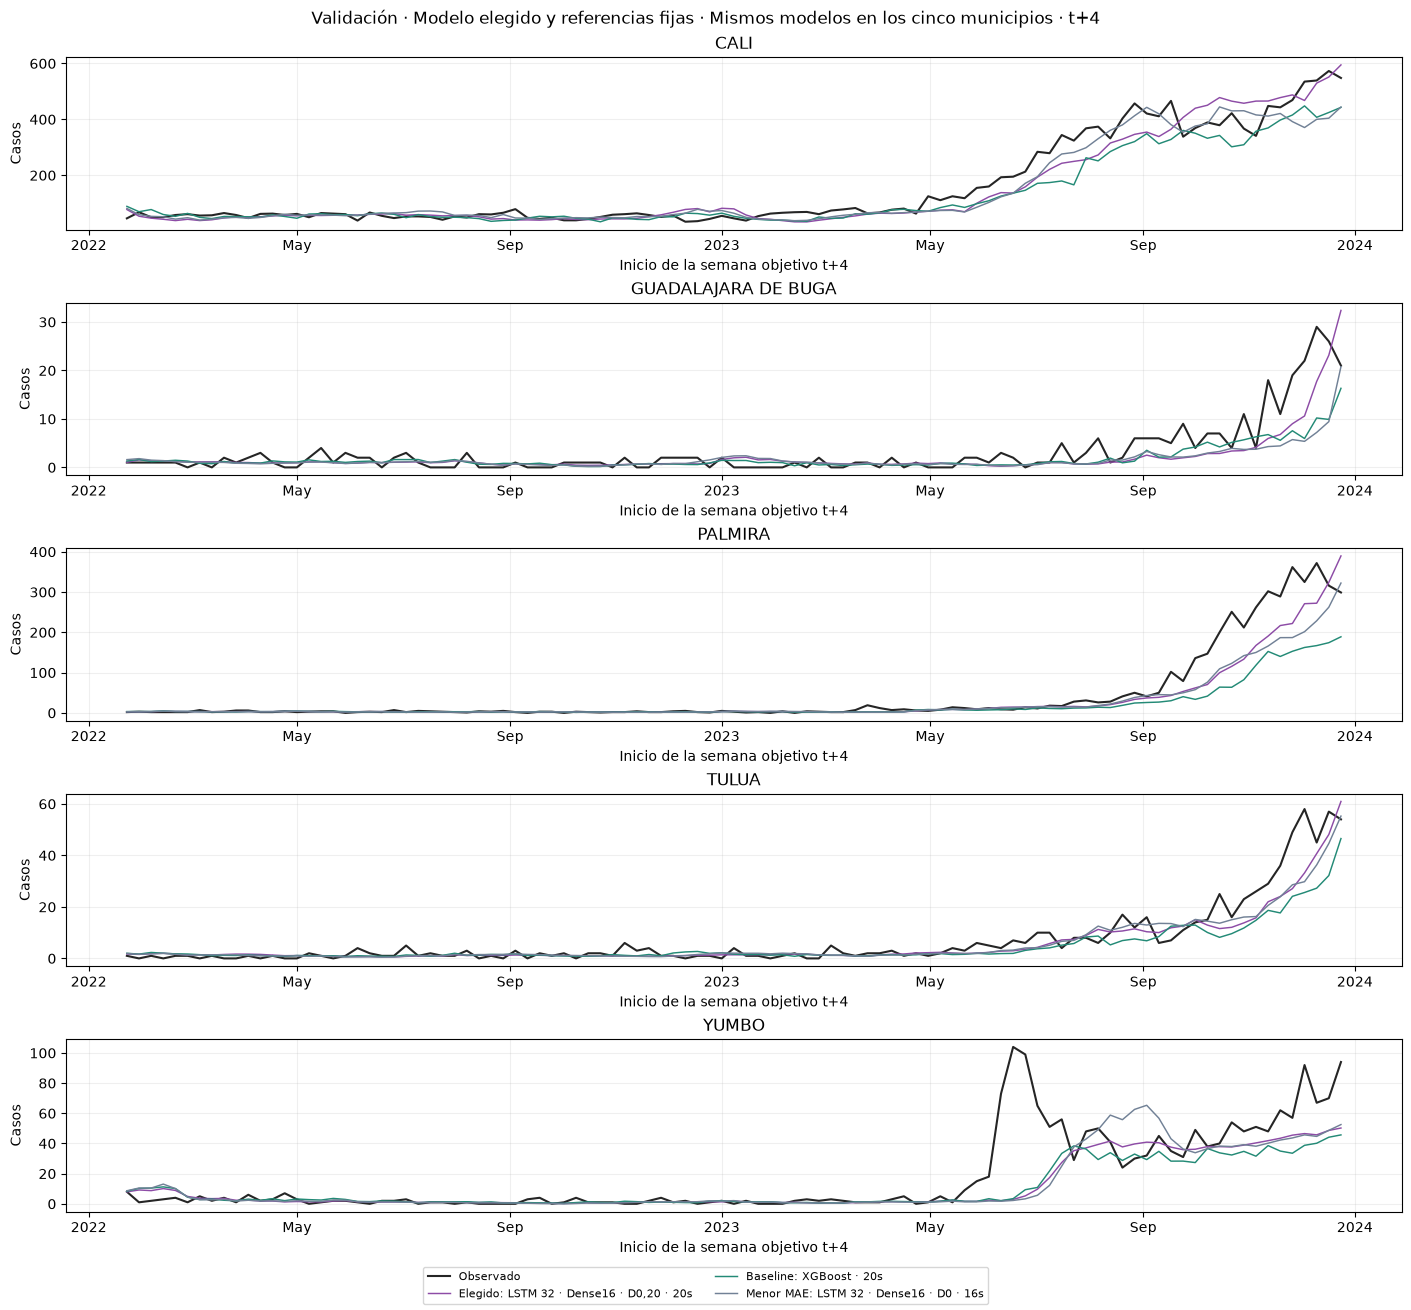

In [2]:
mostrar_tabla_validacion(comparacion_baseline_municipal[
    ['MUNICIPIO','MAE_CANDIDATO','MAE_BASELINE','DIFERENCIA_MAE','REDUCCION_MAE_PCT',
     'RMSE_CANDIDATO','RMSE_BASELINE','DIFERENCIA_RMSE']])
figura_comparacion_municipal = graficar_comparacion_municipal(
    analisis_validacion_18_2, RUTA_ANALISIS_VALIDACION)
plt.show()
figura_series_modelo_elegido = graficar_series_candidato(
    predicciones_desarrollo, analisis_validacion_18_2, ranking_validacion, RUTA_ANALISIS_VALIDACION)
plt.show()

#### 18.2.4. Separar los años de validación

Al separar el candidato por año de la semana objetivo encontramos: **2022**: 245 pronósticos, MAE 3.455, RMSE 7.343 y promedio observado de 12.23 casos; **2023**: 260 pronósticos, MAE 19.410, RMSE 35.974 y promedio observado de 76.34 casos.

El mayor MAE anual del candidato corresponde a **2023**. El promedio de los dos años puede ocultar periodos con errores y volúmenes de casos distintos. La tabla incluye también el mismo baseline y muestra cuántos pronósticos entran en cada año. Este desglose conserva las ventanas y los modelos originales; no implica un ajuste anual nuevo.

In [2]:
mostrar_tabla_validacion(resultados_validacion_por_ano[
    ['MODELO','ANO_OBJETIVO','N','CASOS_MEDIOS','MAE','RMSE','SESGO_MEDIO']])

MODELO,ANO_OBJETIVO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO
"LSTM 32 · Dense16 · D0,20 · 20s",2022,245,12.233,3.455,7.343,-0.313
"LSTM 32 · Dense16 · D0,20 · 20s",2023,260,76.338,19.410,35.974,-11.626
XGBoost · 20s,2022,245,12.233,3.301,6.970,0.007
XGBoost · 20s,2023,260,76.338,25.283,49.758,-24.075


#### 18.2.5. Examinar las semanas con mayores errores

Los **10 mayores errores absolutos** representan **37.61%** de la suma de errores cuadráticos del candidato. En **9 de esos 10 pronósticos** se subestimaron los casos. Esto permite ver cuánto influyen unas pocas semanas en RMSE. La tabla muestra la fecha de emisión, la semana que se pronosticó, los casos observados y el error con signo.

Estas semanas se identifican después de conocer los valores reales de validación: son un diagnóstico de errores, no una regla para anticipar brotes. El horizonte sigue siendo t+4 y no se incorporan esas observaciones futuras a las entradas del modelo.

In [2]:
mostrar_tabla_validacion(mayores_errores_validacion[
    ['MUNICIPIO','FECHA_EMISION','FECHA_OBJETIVO','CASOS_ORIGINALES','CASOS_PREDICHOS','ERROR','ERROR_ABSOLUTO']])
guardar_analisis_validacion(analisis_validacion_18_2, RUTA_ANALISIS_VALIDACION)

MUNICIPIO,FECHA_EMISION,FECHA_OBJETIVO,CASOS_ORIGINALES,CASOS_PREDICHOS,ERROR,ERROR_ABSOLUTO
PALMIRA,2023-11-04,2023-11-26,362,221.953,-140.047,140.047
PALMIRA,2023-09-30,2023-10-22,251,115.577,-135.423,135.423
CALI,2023-10-14,2023-11-05,341,465.320,124.320,124.320
CALI,2023-07-08,2023-07-30,368,255.865,-112.135,112.135
PALMIRA,2023-10-21,2023-11-12,302,190.718,-111.282,111.282
CALI,2023-08-05,2023-08-27,457,346.426,-110.574,110.574
CALI,2023-08-26,2023-09-17,466,364.626,-101.374,101.374
CALI,2023-07-15,2023-08-06,374,272.833,-101.167,101.167
YUMBO,2023-05-27,2023-06-18,104,2.904,-101.096,101.096
CALI,2023-06-24,2023-07-16,344,243.027,-100.973,100.973


#### 18.2.6. Alcance de esta lectura

Los resultados describen una semilla y el bloque de validación 2022–2023. Elegir entre varias configuraciones usando ese mismo bloque puede producir un mínimo optimista. Las ventanas se solapan y los errores no representan observaciones independientes. Este análisis ayuda a localizar diferencias y errores, pero no demuestra superioridad estadística ni estabilidad en otros periodos. Esta es la lectura de validación que usamos para fijar la selección antes de pasar a la evaluación del punto 20.

## 19. Discutir los resultados con el modelo elegido

Continuamos con la **LSTM32 + Dense16 + Dropout de 0,20 e historia de 20 semanas** registrada en 18.2. Su elección prioriza trabajar con esa arquitectura regularizada; dentro de esa variante, la historia se escogió con validación. Conservamos los mínimos de MAE y RMSE como referencias y explicamos las diferencias con el candidato elegido.

El resumen utiliza las métricas de esta corrida y el detalle municipal del modelo elegido. Las comparaciones de tamaños, Dropout y profundidad siguen mostrando las diferencias entre sus configuraciones originales. Una sola semilla y un bloque temporal no bastan para afirmar superioridad estadística o mejor generalización.


Para continuar con el pronóstico de casos a cuatro semanas elegimos la **LSTM de 32 unidades, Dense de 16 neuronas y Dropout de 0,20, con 20 semanas de historia**. En validación obtuvo un **MAE de 11.669 casos y un RMSE de 26.314**. Dentro de esta arquitectura, la historia de 20 semanas dio los menores errores entre las tres que probamos. La elección combina esos resultados con la preferencia de trabajar con Dropout; todavía falta comprobar si mantiene su desempeño en otros periodos.

La LSTM sin Dropout y con 16 semanas de historia obtuvo el menor MAE de las 53 configuraciones: **11.627 casos**, con un RMSE de **27.738**. Frente a ella, el modelo elegido tiene un MAE apenas **0.042 casos mayor** y un RMSE **1.424 casos menor**. Además, su RMSE es el más bajo de toda la comparación. Esto respalda que lo mantengamos como candidato, aunque no demuestra que Dropout vaya a mejorar siempre la generalización.

En las GRU, el menor MAE fue el de la estructura de 32 unidades y Dense16, sin Dropout y con 20 semanas de historia: **MAE de 12.083 y RMSE de 28.829**. Todas las historias se compararon con los mismos **3,800 ejemplos de entrenamiento y 505 objetivos de validación**. Cambió la cantidad de semanas que podía observar cada modelo antes de pronosticar; las fechas utilizadas para medir el desempeño fueron las mismas.

Reducir la LSTM a 16 unidades y la Dense intermedia a 8 neuronas no mejoró el MAE en ninguna de las tres historias. Con 12 semanas pasó de **12.292 a 14.328**; con 16 semanas, de **11.627 a 14.056**; y con 20 semanas, de **12.154 a 15.018**. Ambas estructuras conservaron la identificación del municipio mediante one-hot, la salida de una neurona y Dropout en cero. Como redujimos dos partes de la red a la vez, estos resultados describen el cambio de estructura completo y no el efecto de cada reducción por separado.

Añadir únicamente Dropout redujo el MAE en **2 de las 12 variantes** comparadas con su referencia de igual familia e historia. Las estructuras de dos o tres capas con Dropout no lo redujeron en ninguna de las **12 comparaciones**, y quitar la Dense intermedia tampoco lo hizo en las **6 comparaciones** correspondientes. Por tanto, los resultados no muestran una mejora general al aumentar la profundidad o el Dropout. En las redes profundas cambiamos ambas cosas a la vez, de modo que tampoco podemos atribuir sus diferencias a una sola de ellas.

El error del modelo elegido varía entre municipios: su MAE va de **1.839 casos en Guadalajara de Buga a 31.329 en Cali**. Son diferencias en cantidades de casos y cada municipio tiene un volumen distinto. Para interpretar esas cifras conviene revisar también el sesgo, la concentración de errores y la comparación entre 2022 y 2023 que presentamos en el punto 18.2. Mantenemos el mismo modelo elegido para los cinco municipios.

Estas conclusiones corresponden a una sola semilla y al bloque de validación **2022–2023**. Probamos varias configuraciones sobre ese mismo periodo y las ventanas se solapan, por lo que conviene comprobar la estabilidad con otros cortes temporales y semillas, además de incorporar referencias de persistencia o estacionales. La comparación actual no permite afirmar superioridad estadística ni utilidad para una intervención sanitaria.

La evaluación final se presenta por separado en el punto 20, después de fijar esta selección. Durante el desarrollo se conservaron los escaladores ajustados con entrenamiento y las predicciones continuas, incluidos los valores negativos que se contabilizan en las métricas. El bloque **2024–2025** no se utilizó para elegir entre las configuraciones de esta exploración, aunque ya se había observado anteriormente; su evaluación debe interpretarse con ese antecedente.


**Comparación de cada variante con su arquitectura de referencia.**

La siguiente tabla calcula las diferencias usando los resultados de validación de la misma familia e historia. Una mejora porcentual de MAE positiva indica que la variante redujo el error; un cambio de RMSE negativo también indica una reducción. La tabla permite revisar las comparaciones que sustentan las conclusiones anteriores.


In [3]:
# Comparar los errores de validación de cada variante con su referencia.
filas_cambios_arquitecturas = []
for familia in ['LSTM', 'GRU']:
    for historia in HISTORIAS:
        referencia = ranking_validacion.loc[
            ranking_validacion['ID'].eq(f'{familia.lower()}_referencia_v{historia}')].iloc[0]
        variantes = ['sin_dense', 'drop20', 'drop50', 'dos_capas', 'tres_capas']
        if familia == 'LSTM':
            variantes.append('compacta16_8')
        for receta in variantes:
            variante = ranking_validacion.loc[
                ranking_validacion['ID'].eq(f'{familia.lower()}_{receta}_v{historia}')].iloc[0]
            filas_cambios_arquitecturas.append({
                'FAMILIA': familia,
                'HISTORIA': historia,
                'RECETA': receta,
                'MAE_REFERENCIA': referencia['MAE'],
                'MAE_VARIANTE': variante['MAE'],
                'MEJORA_MAE_PCT': 100 * (referencia['MAE'] - variante['MAE']) / referencia['MAE'],
                'CAMBIO_RMSE': variante['RMSE'] - referencia['RMSE'],
            })
cambios_arquitecturas = pd.DataFrame(filas_cambios_arquitecturas)

display(cambios_arquitecturas.style.format({'MAE_REFERENCIA':'{:.3f}','MAE_VARIANTE':'{:.3f}',
    'MEJORA_MAE_PCT':'{:.2f}','CAMBIO_RMSE':'{:+.3f}'}).hide(axis='index'))
cambios_arquitecturas.to_csv(RUTA_EJECUCION/'tablas/cambios_frente_referencia.csv',index=False,encoding='utf-8-sig')


FAMILIA,HISTORIA,RECETA,MAE_REFERENCIA,MAE_VARIANTE,MEJORA_MAE_PCT,CAMBIO_RMSE
LSTM,12,sin_dense,12.292,14.793,-20.34,+6.297
LSTM,12,drop20,12.292,13.834,-12.54,+5.237
LSTM,12,drop50,12.292,14.147,-15.08,+5.371
LSTM,12,dos_capas,12.292,14.194,-15.47,+5.882
LSTM,12,tres_capas,12.292,16.603,-35.07,+13.538
LSTM,12,compacta16_8,12.292,14.328,-16.56,+4.419
LSTM,16,sin_dense,11.627,14.156,-21.75,+5.447
LSTM,16,drop20,11.627,12.155,-4.54,+0.906
LSTM,16,drop50,11.627,13.563,-16.65,+5.656
LSTM,16,dos_capas,11.627,14.295,-22.95,+7.743


### 19.1. Relacionar los resultados con los antecedentes

**Zhao et al. (2020)** compararon Random Forest con datos agrupados y modelos locales a escala departamental en Colombia. Utilizaron 12 semanas de historia y distintas anticipaciones. Su trabajo sirve como referencia para estudiar la cantidad de historia y el uso de información de varios lugares. Nuestro análisis es municipal y tiene un único objetivo, t+4, por lo que sus errores no son directamente comparables con los nuestros.

**Benedum et al. (2020)** estudiaron tanto el pronóstico de casos como la clasificación de semanas de brote, con 26 semanas de historia y anticipaciones de 4 y 12 semanas. Evaluaron los modelos avanzando en el tiempo y reentrenándolos por año. Ese procedimiento ofrece una referencia para ampliar nuestro análisis con otros cortes cronológicos, además del bloque fijo de validación que usamos aquí.

**Schlesinger et al. (2024)** evaluaron EWARS-csd en 11 municipios colombianos, con clima y hospitalizaciones, y midieron su capacidad para anticipar brotes. Su objetivo y su modelo DLNM–INLA son distintos de nuestra regresión de casos. Esta diferencia importa al interpretar el alcance del trabajo: un error de pronóstico bajo no demuestra por sí solo que podamos detectar brotes.


### 19.2. Reconocer las limitaciones

La comparación tiene varias limitaciones que debemos considerar al interpretar los resultados:

- Los cinco municipios se eligieron por su volumen de casos en 2007–2023. Los errores representan esos municipios y esas cantidades, no tasas ajustadas por población ni resultados para todo el departamento.
- Contamos registros según `ANO` y `SEMANA`, después de excluir filas sin `INI_SIN`. Las filas coincidentes se conservan, por lo que no se ha comprobado que cada una corresponda a un episodio único. También falta confirmar con el diccionario de vigilancia que las semanas de casos y clima tengan el mismo significado.
- Completar las semanas sin registros con cero supone que hubo cobertura de notificación. Los archivos no permiten distinguir siempre una ausencia real de casos de una falla de reporte.
- Suponemos que los casos y el clima hasta t estaban disponibles al emitir el pronóstico. No reconstruimos retrasos de notificación ni revisiones posteriores de los datos.
- No contamos con población, información entomológica, movilidad, serotipos o intervenciones. El análisis permite comparar predicciones, pero no identificar efectos causales del clima.
- La salida lineal puede producir valores negativos. Se conservan y contabilizan en las métricas; cualquier tratamiento distinto tendría que definirse y validarse antes de usar el modelo.
- Las ventanas se solapan y probamos varias configuraciones con una sola semilla sobre la misma validación. Faltan otros cortes temporales, semillas y referencias de persistencia o estacionales para estudiar la estabilidad. Tampoco se ha evaluado el beneficio de usar estos pronósticos en una intervención sanitaria.


## 20. Evaluación final con el conjunto de prueba

Cerramos la comparación utilizando el test de **2024–2025**. Mantenemos la selección del punto 18.2: **LSTM32 + Dense16 + Dropout de 0,20, con 20 semanas de historia y pronóstico t+4**. Cargamos sus pesos entrenados y los escaladores de entrenamiento; aquí no volvemos a ajustar el modelo ni las transformaciones.

También evaluamos las referencias de menor MAE de validación por familia. Sus identificadores se guardan antes de abrir el test y se mantienen fijos para los cinco municipios. Estos resultados sirven para medir el desempeño de los modelos seleccionados; no los usamos para volver a escoger la arquitectura.

La evaluación avanza semana a semana. En cada emisión utilizamos los casos y el clima observados hasta ese momento y pronosticamos una sola semana, t+4. Esto supone que esa información ya estaba disponible: no es un pronóstico de todo el periodo emitido de una vez ni la suma de casos de un mes.

El test ya se había consultado en etapas anteriores del proyecto. Lo conservamos como evaluación separada del desarrollo actual, con ese antecedente al interpretar los resultados.

### 20.1. Calcular el desempeño en test

In [2]:
EJECUTAR_EVALUACION_FINAL = True
assert EJECUTAR_EVALUACION_FINAL
assert all(s['ENTRENADO_EN_ESTA_EJECUCION'] and s['EJECUCION']==RUTA_EJECUCION.name for s in catalogo_actual)
ID_ELEGIDO_AL_CIERRE = seleccion_validacion['ID_ELEGIDO']

nivel_log_tensorflow_evaluacion = tf.get_logger().level
try:
    tf.get_logger().setLevel('ERROR')
    (predicciones_evaluacion_cierre, metricas_evaluacion_cierre, metricas_municipales_cierre,
     _, RUTA_EVALUACION_CIERRE) = evaluar_al_cierre(
        RUTA_EJECUCION, secuencias_desarrollo, preprocesamiento_actual,
        catalogo_actual, ranking_validacion, seleccion_validacion)
finally:
    tf.get_logger().setLevel(nivel_log_tensorflow_evaluacion)

assert seleccion_validacion['ID_ELEGIDO']==ID_ELEGIDO_AL_CIERRE
metricas_evaluacion_cierre['ROL'] = np.where(
    metricas_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE), 'Modelo elegido', 'Referencia de validación')
metricas_evaluacion_cierre.to_csv(RUTA_EVALUACION_CIERRE/'metricas.csv',index=False,encoding='utf-8-sig')
display(metricas_evaluacion_cierre[['ROL','MODELO','HISTORIA','N','MAE','RMSE','SESGO_MEDIO','PRONOSTICOS_NEGATIVOS']]
    .style.format({'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))

ROL,MODELO,HISTORIA,N,MAE,RMSE,SESGO_MEDIO,PRONOSTICOS_NEGATIVOS
Modelo elegido,"LSTM 32 · Dense16 · D0,20 · 20s",20,510,41.166,106.534,-19.489,0
Referencia de validación,LSTM 32 · Dense16 · D0 · 16s,16,510,36.151,90.138,-18.211,0
Referencia de validación,GRU 32 · Dense16 · D0 · 20s,20,510,33.883,85.960,-22.630,0
Referencia de validación,LSTM local (5 redes) · 20s,20,510,45.489,103.980,-21.086,0
Referencia de validación,Regresión lineal · 12s,12,510,31.405,79.162,-8.323,0
Referencia de validación,Random Forest · 20s,20,510,43.633,103.312,-33.306,0
Referencia de validación,XGBoost · 20s,20,510,41.012,97.461,-32.399,0


### 20.2. Revisar los resultados por municipio

La tabla muestra el error de la LSTM elegida en cada municipio. Las métricas están en casos de dengue, después de deshacer la transformación con el escalador correspondiente. El sesgo es pronosticado menos real: un valor negativo indica que, en promedio, el modelo se quedó por debajo de los casos observados. Conservamos los pronósticos continuos, incluidos los negativos, sin redondearlos ni recortarlos.

In [3]:
metricas_municipales_modelo_elegido = metricas_municipales_cierre.loc[
    metricas_municipales_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
display(metricas_municipales_modelo_elegido[
    ['MUNICIPIO','N','MAE','RMSE','SESGO_MEDIO','PRONOSTICOS_NEGATIVOS']].style.format(
        {'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))
metricas_municipales_modelo_elegido.to_csv(
    RUTA_EVALUACION_CIERRE/'metricas_municipales_modelo_elegido.csv',index=False,encoding='utf-8-sig')

MUNICIPIO,N,MAE,RMSE,SESGO_MEDIO,PRONOSTICOS_NEGATIVOS
CALI,102,114.681,222.448,-50.079,0
GUADALAJARA DE BUGA,102,26.679,49.972,-19.079,0
PALMIRA,102,19.349,39.937,+6.555,0
TULUA,102,21.937,40.861,-17.256,0
YUMBO,102,23.182,38.769,-17.587,0


#### 20.2.1. Separar los dos años de evaluación

El promedio de los dos años puede ocultar periodos muy distintos. Esta tabla separa los objetivos de 2024 y 2025 para el modelo elegido y muestra también el promedio de casos observados por municipio y semana. Son cantidades de casos, sin ajuste por población.


In [2]:
predicciones_test_modelo_elegido = predicciones_evaluacion_cierre.loc[
    predicciones_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
filas_evaluacion_por_ano = []
for ano, grupo in predicciones_test_modelo_elegido.groupby(
        predicciones_test_modelo_elegido['FECHA_OBJETIVO'].dt.year,sort=True):
    errores = grupo['CASOS_PREDICHOS']-grupo['CASOS_REALES']
    filas_evaluacion_por_ano.append({'ANO_OBJETIVO':ano,'N':len(grupo),
        'CASOS_MEDIOS':grupo['CASOS_ORIGINALES'].mean(),
        'MAE':errores.abs().mean(),'RMSE':np.sqrt((errores**2).mean()),'SESGO_MEDIO':errores.mean()})
metricas_evaluacion_por_ano = pd.DataFrame(filas_evaluacion_por_ano)
display(metricas_evaluacion_por_ano.style.format({'CASOS_MEDIOS':'{:.3f}',
    'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:+.3f}'}).hide(axis='index'))
metricas_evaluacion_por_ano.to_csv(RUTA_EVALUACION_CIERRE/'metricas_anuales_modelo_elegido.csv',
    index=False,encoding='utf-8-sig')


ANO_OBJETIVO,N,CASOS_MEDIOS,MAE,RMSE,SESGO_MEDIO
2024,250,204.584,79.602,152.006,-41.141
2025,260,15.688,4.207,6.749,+1.330


### 20.3. Comparar entrenamiento, validación y test

Para cada municipio mostramos los casos observados y los pronósticos t+4 de los mismos modelos en los tres periodos. La leyenda conserva sus nombres y cada panel identifica el conjunto utilizado. Las escalas verticales se ajustan por panel para facilitar la lectura; debemos revisar los valores del eje al comparar periodos.

Las gráficas de entrenamiento describen el ajuste y las de validación corresponden al periodo que usamos para comparar configuraciones. El panel de test muestra cómo se comportaron esos pesos al avanzar sobre fechas posteriores. La tabla siguiente reúne MAE y RMSE de los tres conjuntos.

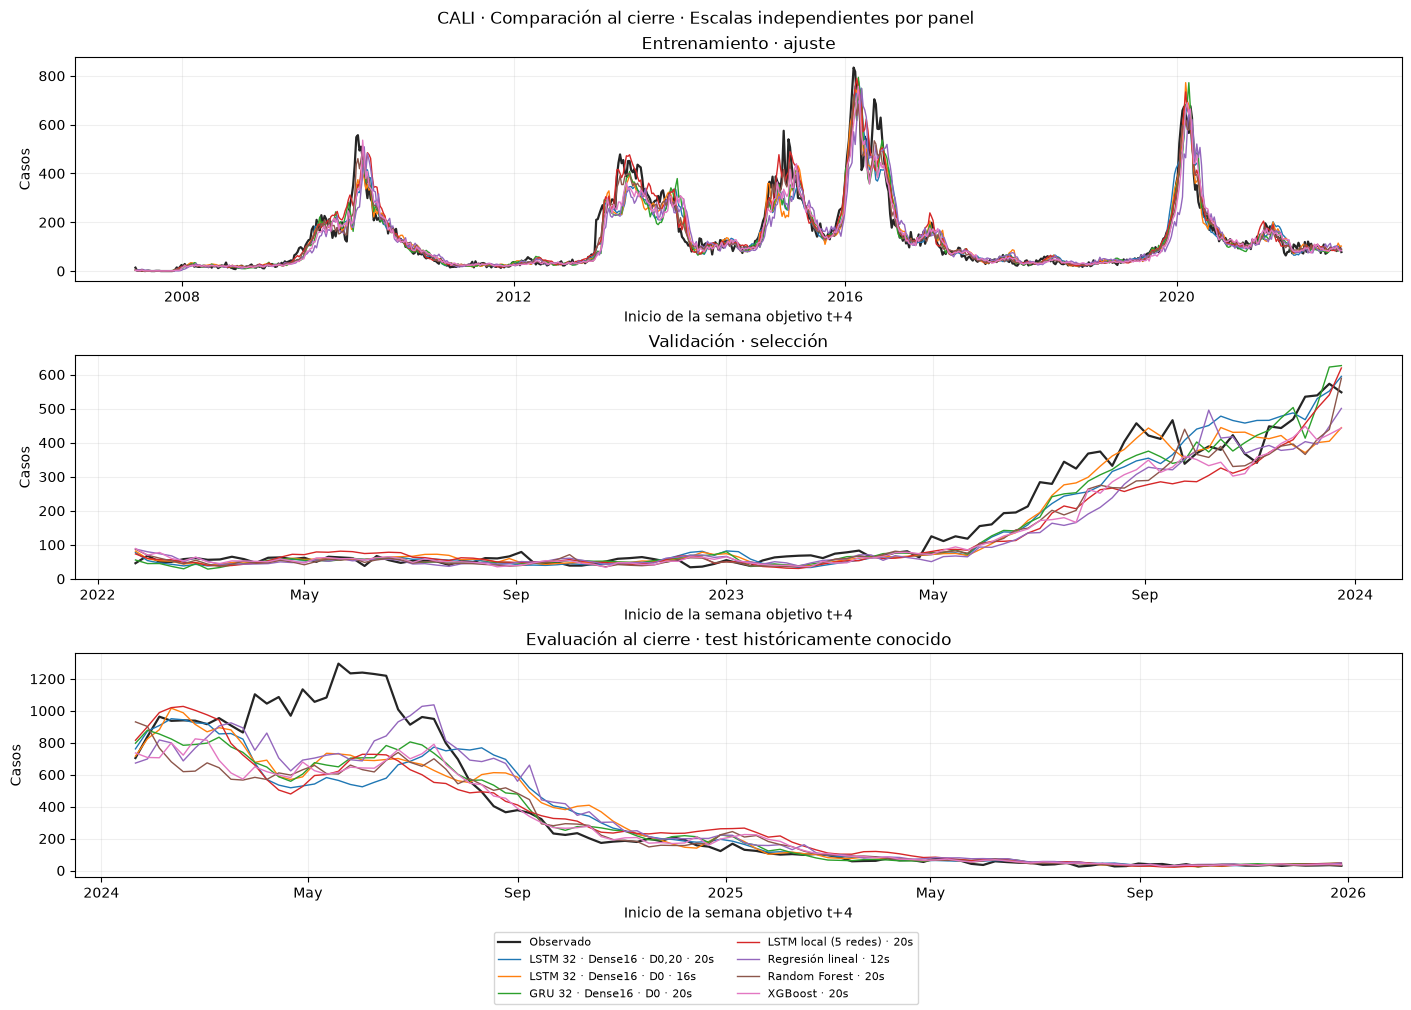

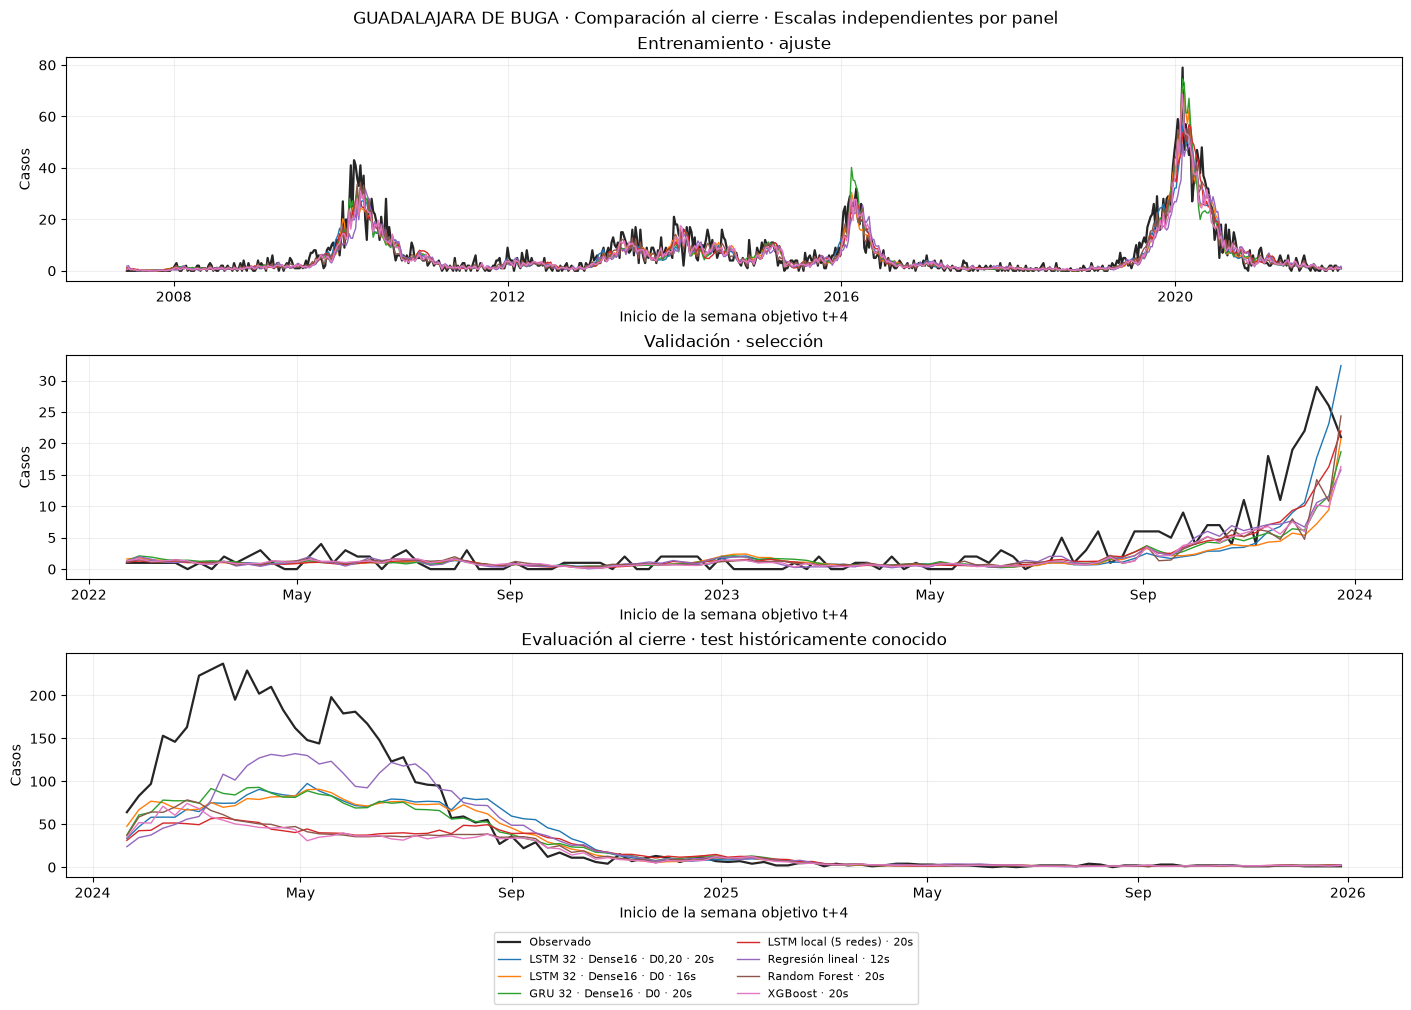

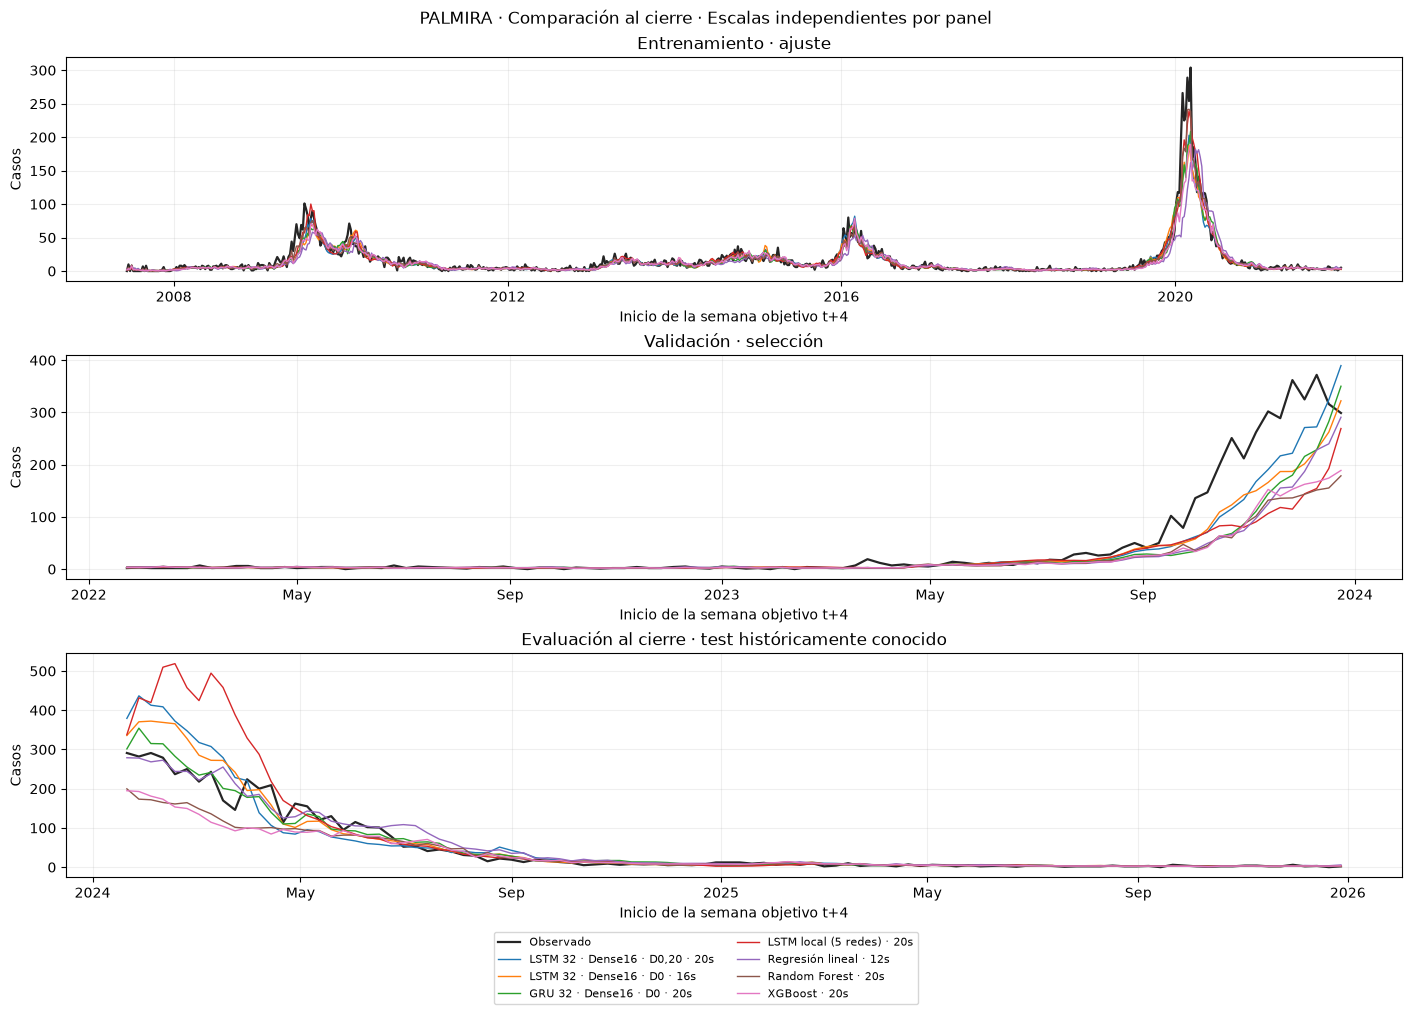

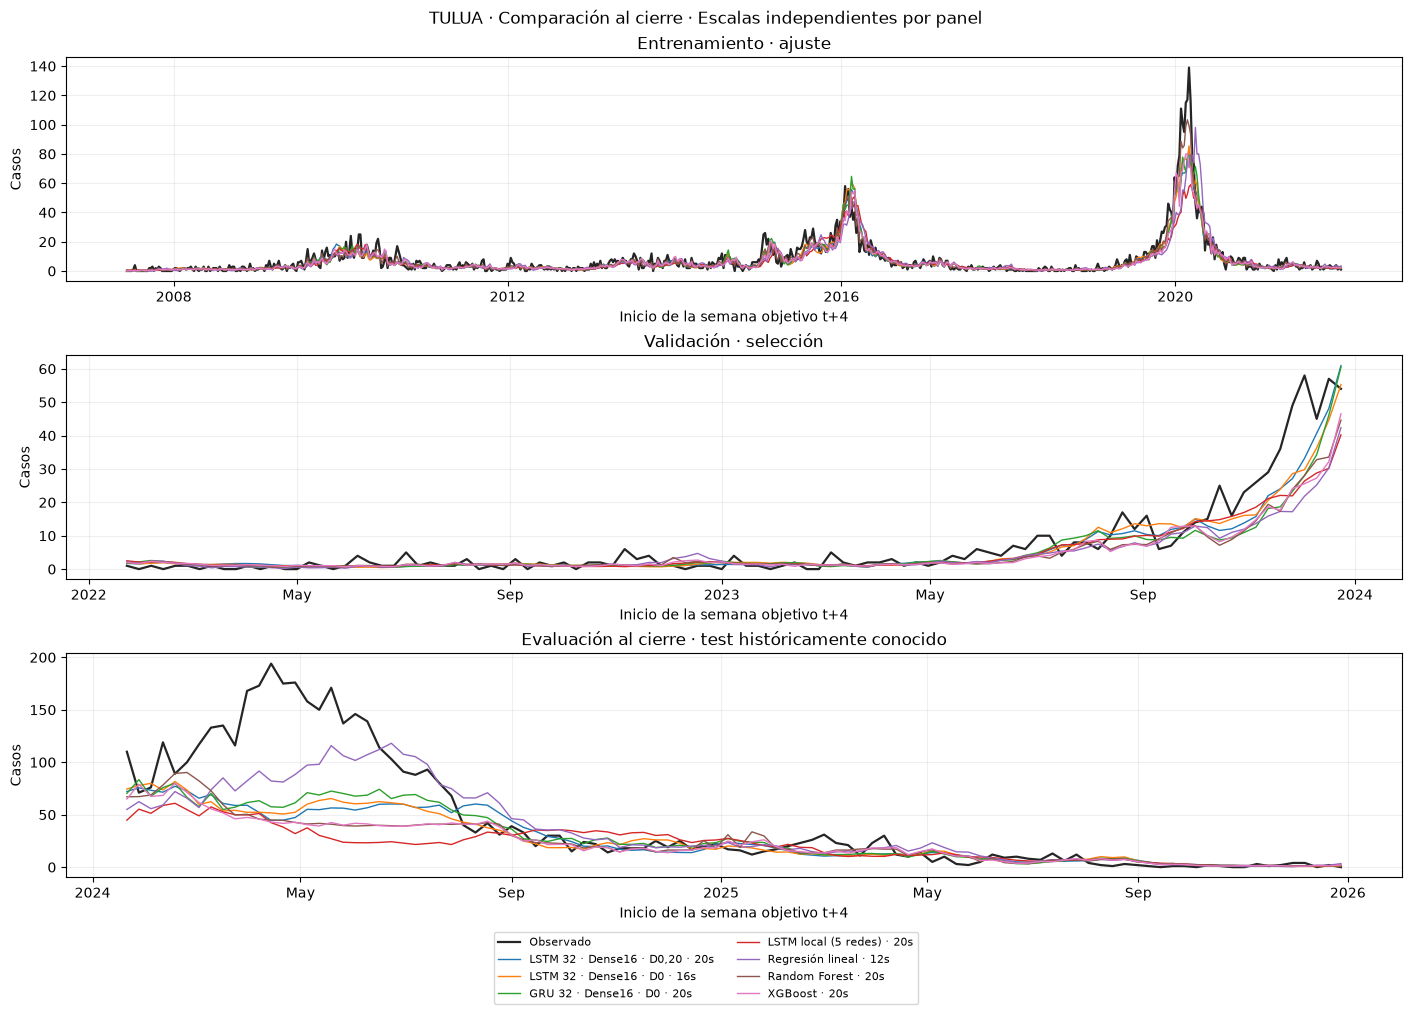

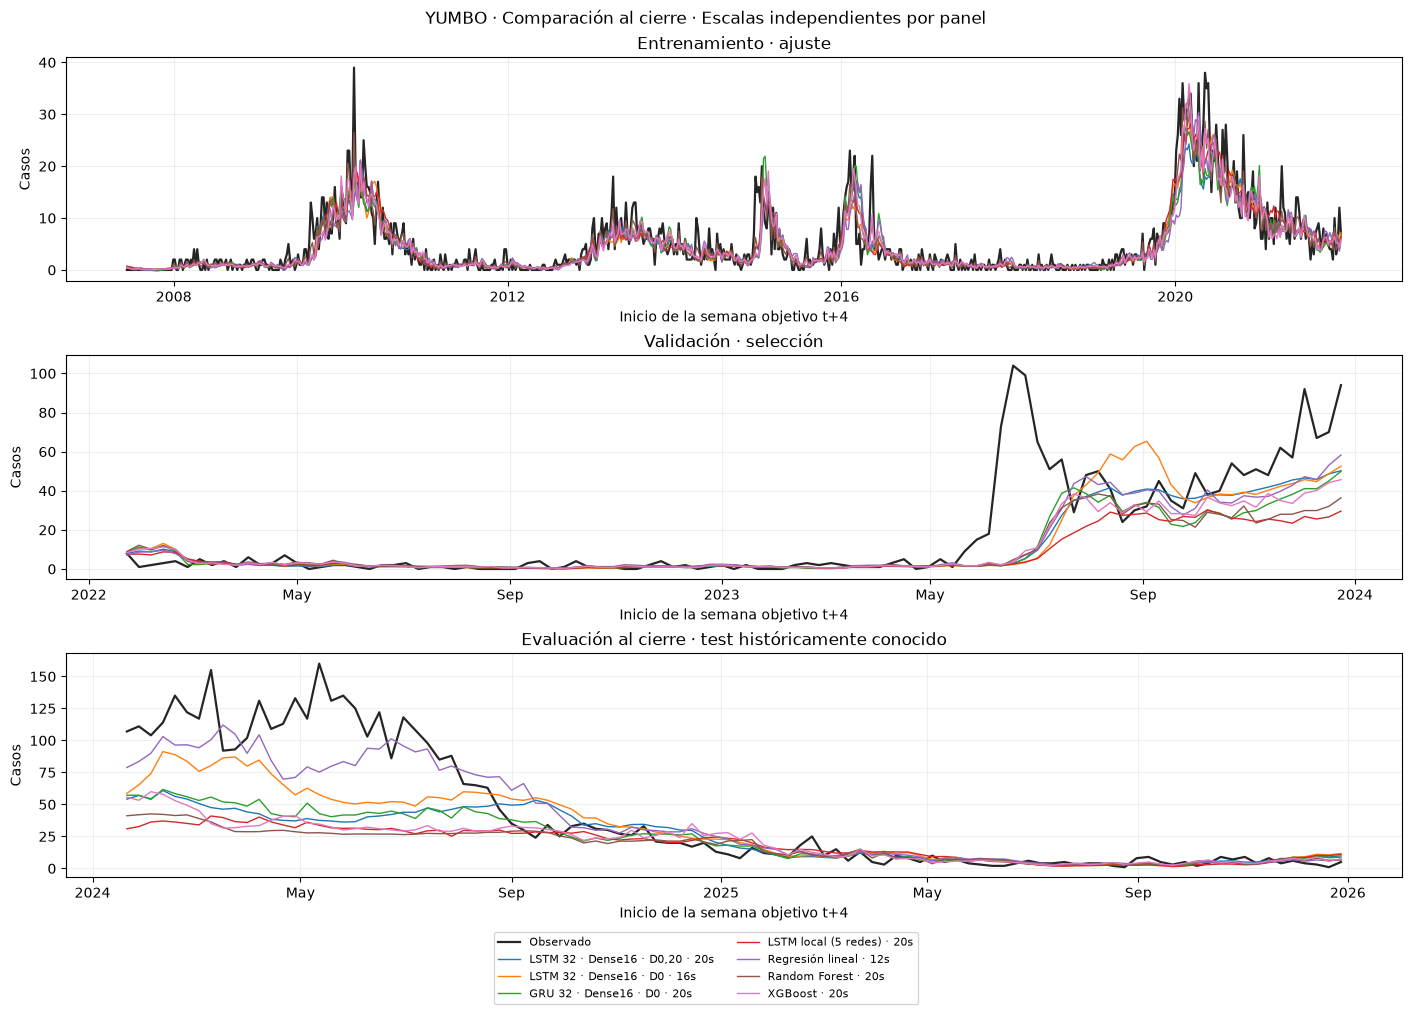

In [4]:
metricas_tres_conjuntos_cierre, figuras_finales = graficar_al_cierre(
    predicciones_desarrollo, predicciones_evaluacion_cierre, RUTA_EVALUACION_CIERRE)
comparacion_tres_conjuntos_cierre = metricas_tres_conjuntos_cierre.pivot(
    index='MODELO',columns='CONJUNTO',values=['MAE','RMSE'])
comparacion_tres_conjuntos_cierre = comparacion_tres_conjuntos_cierre.reindex(
    columns=pd.MultiIndex.from_product([['MAE','RMSE'],['training','validation','evaluation']],
        names=comparacion_tres_conjuntos_cierre.columns.names))
display(comparacion_tres_conjuntos_cierre.style.format('{:.3f}'))

### 20.4. Guardar el modelo elegido

Guardamos una copia de los pesos que acabamos de evaluar en **modelo_elegido**, dentro de la carpeta de esta evaluación. El archivo **modelo.keras** conserva la arquitectura y los pesos. Lo acompañan los escaladores de casos por municipio, los del clima, el codificador one-hot, el orden de las variables y la configuración de la selección.

También guardamos un ejemplo de entradas de validación y comprobamos que el modelo exportado reproduce sus predicciones. Esta verificación solo carga el archivo y pronostica; no realiza entrenamiento. Las instrucciones de carga quedan en el archivo README de esa carpeta.

In [5]:
especificacion_modelo_exportado = next(s for s in catalogo_actual if s['ID']==ID_ELEGIDO_AL_CIERRE)
assert especificacion_modelo_exportado['TIPO']=='red'
RUTA_MODELO_EXPORTADO = RUTA_EVALUACION_CIERRE/'modelo_elegido'
RUTA_MODELO_EXPORTADO.mkdir(parents=True,exist_ok=False)
shutil.copy2(especificacion_modelo_exportado['ARCHIVO'],RUTA_MODELO_EXPORTADO/'modelo.keras')
shutil.copy2(RUTA_EJECUCION/'preprocesamiento_actual.joblib',RUTA_MODELO_EXPORTADO/'preprocesamiento.joblib')
shutil.copy2('requirements-lock.txt',RUTA_MODELO_EXPORTADO/'requirements-lock.txt')

configuracion_modelo_exportado = {
    'ID': ID_ELEGIDO_AL_CIERRE,
    'nombre': especificacion_modelo_exportado['NOMBRE'],
    'arquitectura': especificacion_modelo_exportado['CONFIG'],
    'parametros': especificacion_modelo_exportado['PARAMETROS_RED'],
    'historia_semanas': especificacion_modelo_exportado['HISTORIA'],
    'horizonte_semanas': HORIZONTE,
    'objetivo': 'Casos de una sola semana, t+4; no acumulado mensual',
    'columnas_temporales': preprocesamiento_actual['columnas_temporales'],
    'orden_one_hot': preprocesamiento_actual['codificador_municipios'].categories_[0].tolist(),
    'entradas': {'historia': [None,especificacion_modelo_exportado['HISTORIA'],len(preprocesamiento_actual['columnas_temporales'])],
        'municipio': [None,len(preprocesamiento_actual['orden_municipios'])]},
    'salida': 'log1p(casos) estandarizado con el escalador del municipio',
    'inversion_salida': 'expm1(escalador_municipal.inverse_transform(salida))',
    'escaladores_ajustados_con': 'training 2007–2021',
    'seleccion_realizada_con': 'validation 2022–2023',
    'evaluacion': 'test 2024–2025, históricamente consultado',
    'reentrenado_al_cierre': False,
    'ejecucion_entrenamiento': RUTA_EJECUCION.as_posix(),
    'seleccion': seleccion_validacion,
    'metricas_test': metricas_evaluacion_cierre.loc[
        metricas_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].iloc[0].to_dict(),
    'versiones': {paquete: importlib.metadata.version(paquete)
        for paquete in ['tensorflow','keras','scikit-learn','numpy','pandas','joblib']},
}
(RUTA_MODELO_EXPORTADO/'configuracion.json').write_text(
    json.dumps(configuracion_modelo_exportado,ensure_ascii=False,indent=2,
        default=lambda x:x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')

# Comprobar la copia con un ejemplo de cada municipio, usando solo validación.
datos_validacion_exportacion = secuencias_desarrollo[especificacion_modelo_exportado['HISTORIA']]['validation']
posiciones_ejemplo = datos_validacion_exportacion['meta'].groupby('COD_DANE',observed=True,sort=True).head(1).index.to_numpy()
ejemplos_exportacion = {k:(v.iloc[posiciones_ejemplo].reset_index(drop=True) if k=='meta' else v[posiciones_ejemplo])
    for k,v in datos_validacion_exportacion.items()}
modelo_exportado_verificado = tf.keras.models.load_model(RUTA_MODELO_EXPORTADO/'modelo.keras',compile=False)
preprocesamiento_exportado = joblib.load(RUTA_MODELO_EXPORTADO/'preprocesamiento.joblib')
salida_ejemplos_exportados = predecir_red_actual(modelo_exportado_verificado,ejemplos_exportacion)
casos_ejemplos_exportados = invertir(salida_ejemplos_exportados,
    ejemplos_exportacion['meta']['COD_DANE'],preprocesamiento_exportado)
predicciones_ejemplo_exportado = ejemplos_exportacion['meta'][['COD_DANE','MUNICIPIO','FECHA_EMISION','FECHA_OBJETIVO']].copy()
predicciones_ejemplo_exportado['CASOS_PREDICHOS'] = casos_ejemplos_exportados
referencia_ejemplo_exportado = predicciones_desarrollo.loc[
    predicciones_desarrollo['ID'].eq(ID_ELEGIDO_AL_CIERRE) & predicciones_desarrollo['CONJUNTO'].eq('validation'),
    ['COD_DANE','FECHA_OBJETIVO','CASOS_PREDICHOS']].copy()
referencia_ejemplo_exportado['FECHA_OBJETIVO'] = pd.to_datetime(referencia_ejemplo_exportado['FECHA_OBJETIVO'])
verificacion_ejemplos_exportados = predicciones_ejemplo_exportado.merge(referencia_ejemplo_exportado,
    on=['COD_DANE','FECHA_OBJETIVO'],validate='one_to_one',suffixes=('_EXPORTADO','_ORIGINAL'))
assert len(verificacion_ejemplos_exportados)==len(preprocesamiento_actual['orden_municipios'])
np.testing.assert_allclose(verificacion_ejemplos_exportados['CASOS_PREDICHOS_EXPORTADO'],
    verificacion_ejemplos_exportados['CASOS_PREDICHOS_ORIGINAL'],rtol=1e-5,atol=1e-3)
np.savez_compressed(RUTA_MODELO_EXPORTADO/'entradas_ejemplo_validacion.npz',
    historia=ejemplos_exportacion['X'],municipio=ejemplos_exportacion['aux'],
    codigos=ejemplos_exportacion['meta']['COD_DANE'].to_numpy(dtype=str))
predicciones_ejemplo_exportado.to_csv(RUTA_MODELO_EXPORTADO/'predicciones_ejemplo_validacion.csv',
    index=False,encoding='utf-8-sig',date_format='%Y-%m-%d')

instrucciones_modelo_exportado = '''# Modelo elegido: pronóstico de dengue t+4

LSTM32, Dense16 y Dropout 0,20; historia de 20 semanas; cinco municipios.
Se conservan los pesos evaluados, sin volver a entrenar con validación o test.

Archivos:
- modelo.keras: arquitectura y pesos.
- preprocesamiento.joblib: escaladores y codificador ajustados en entrenamiento.
- configuracion.json: variables, orden municipal, versiones, selección y métricas.
- requirements-lock.txt: dependencias del proyecto.
- entradas_ejemplo_validacion.npz y predicciones_ejemplo_validacion.csv: ejemplo comprobado, un caso por municipio.
- sha256.json: hashes de los archivos exportados.

Ejemplo de carga (ejecutar desde esta carpeta):

```python
import joblib
import numpy as np
import tensorflow as tf

modelo = tf.keras.models.load_model('modelo.keras', compile=False)
prep = joblib.load('preprocesamiento.joblib')
with np.load('entradas_ejemplo_validacion.npz') as ejemplo:
    salida_std = modelo({'historia': ejemplo['historia'], 'municipio': ejemplo['municipio']}, training=False).numpy()
    casos = np.array([
        np.expm1(prep['escaladores_casos'][codigo].inverse_transform(salida_std[i:i+1]))[0, 0]
        for i, codigo in enumerate(ejemplo['codigos'])
    ])
print(casos)
```

Para nuevas entradas, conservar el orden de las siete variables de configuracion.json.
Aplicar los escaladores guardados: casos con log1p y escalador municipal;
temperaturas con su escalador global; precipitación con log1p y su escalador;
añadir seno/coseno de la semana según el calendario epidemiológico del proyecto.
Codificar el municipio con el codificador guardado. No volver a ajustar los escaladores.
La salida es una semana específica t+4. Los ejemplos guardados son de validación.
'''
(RUTA_MODELO_EXPORTADO/'README.md').write_text(instrucciones_modelo_exportado,encoding='utf-8')
hashes_modelo_exportado = {p.name:hashlib.sha256(p.read_bytes()).hexdigest()
    for p in RUTA_MODELO_EXPORTADO.iterdir() if p.is_file() and p.name!='sha256.json'}
(RUTA_MODELO_EXPORTADO/'sha256.json').write_text(json.dumps(hashes_modelo_exportado,indent=2),encoding='utf-8')
assert hashes_modelo_exportado['modelo.keras']==hashlib.sha256(Path(especificacion_modelo_exportado['ARCHIVO']).read_bytes()).hexdigest()
assert hashes_modelo_exportado['preprocesamiento.joblib']==hashlib.sha256((RUTA_EJECUCION/'preprocesamiento_actual.joblib').read_bytes()).hexdigest()
print('Modelo guardado:', (RUTA_MODELO_EXPORTADO/'modelo.keras').as_posix())
print('Preprocesamiento y configuración:', RUTA_MODELO_EXPORTADO.as_posix())
print('Verificación de carga y predicciones: correcta para los cinco municipios.')

Modelo guardado: ResultadosModelos/entrenamiento_en_notebook/ejecucion_93868d0d/evaluacion_al_cierre/ejecucion_3cb61062/modelo_elegido/modelo.keras
Preprocesamiento y configuración: ResultadosModelos/entrenamiento_en_notebook/ejecucion_93868d0d/evaluacion_al_cierre/ejecucion_3cb61062/modelo_elegido
Verificación de carga y predicciones: correcta para los cinco municipios.


### 20.5. Interpretar el desempeño en test

Evaluamos **510 pronósticos por modelo, 102 por municipio**, para semanas objetivo entre el **21 de enero de 2024 y el 28 de diciembre de 2025**. La LSTM elegida obtuvo **MAE de 41.166 casos y RMSE de 106.534**. En entrenamiento sus errores fueron 8.300 y 24.626, y en validación, 11.669 y 26.314. El aumento en test es considerable: el desempeño observado durante la selección no se mantuvo con la misma magnitud en este periodo.

La **regresión lineal con 12 semanas de historia** obtuvo los menores errores entre las siete referencias evaluadas: **MAE de 31.405 y RMSE de 79.162**. La GRU sin Dropout de 20 semanas también quedó por debajo de la LSTM elegida, con **33.883 y 85.960**, al igual que la LSTM sin Dropout de 16 semanas, con **36.151 y 90.138**. La selección previa se conserva y el archivo exportado corresponde a la LSTM con Dropout de 0,20; estos resultados dejan claro que no fue el modelo con menor error en test.

Frente a los otros baselines, XGBoost obtuvo **MAE de 41.012 y RMSE de 97.461**, mientras que Random Forest obtuvo **43.633 y 103.312**. La LSTM elegida tuvo menor MAE que Random Forest, pero mayor RMSE. En conjunto, la comparación no respalda afirmar que esta LSTM superó a los baselines en evaluación ni que añadir Dropout garantizó una mejor generalización.

El sesgo general de la LSTM fue de **−19.489 casos**: en promedio subestimó los casos observados. No produjo predicciones negativas en este test. El RMSE es bastante mayor que el MAE, lo que refleja el peso de algunos errores grandes y hace necesario revisar las series, además de los promedios.

Los dos años tuvieron volúmenes distintos. En los objetivos evaluados de **2024** hubo un promedio de **204.584 casos por municipio y semana**; en **2025**, de **15.688**. El MAE pasó de **79.602 en 2024 a 4.207 en 2025**, y el RMSE, de **152.006 a 6.749**. Esta diferencia ayuda a interpretar el resultado agregado, pero no demuestra por sí sola la causa del deterioro.

Por municipio, Cali presentó el mayor error de la LSTM, con **MAE de 114.681 y RMSE de 222.448**. En Guadalajara de Buga el MAE fue 26.679; en Palmira, 19.349; en Tuluá, 21.937; y en Yumbo, 23.182. Como son cantidades de casos, estas diferencias deben leerse junto con los volúmenes de cada municipio, sin interpretarlas directamente como errores proporcionales.

Conservamos el modelo elegido y sus transformaciones para poder reproducir este resultado. La exportación mantiene los pesos entrenados, sin ajustes con test. Si retomamos la exploración a partir de lo aprendido aquí, estos resultados ya formarían parte del desarrollo y necesitaríamos otra evaluación temporal para comprobar los cambios. Además, el bloque 2024–2025 ya se había observado antes de este cierre, por lo que no lo presentamos como una prueba ciega.


### 20.6. Ver el modelo elegido en validación y test

Aquí seguimos únicamente a la **LSTM32 + Dense16 + Dropout de 0,20, con 20 semanas de historia**, para ver cómo cambió su desempeño al pasar de validación a test. Cada panel corresponde a un municipio y conserva la misma escala vertical entre los dos periodos.

El **fondo azul** identifica validación y el **fondo naranja**, test. La línea vertical discontinua marca el inicio de 2024. Los casos observados aparecen en negro; el pronóstico t+4 cambia de azul a naranja según el conjunto. El eje muestra la fecha de la semana que se pronostica. Conservamos el intervalo sin pronósticos entre las últimas fechas de validación y las primeras de test.

En cada panel aparecen el **MAE y el RMSE del municipio**, calculados por separado para ambos conjuntos. El encabezado de la figura reúne las métricas globales de los cinco municipios. Todos los errores están en casos de dengue y utilizan los mismos pronósticos del análisis anterior.


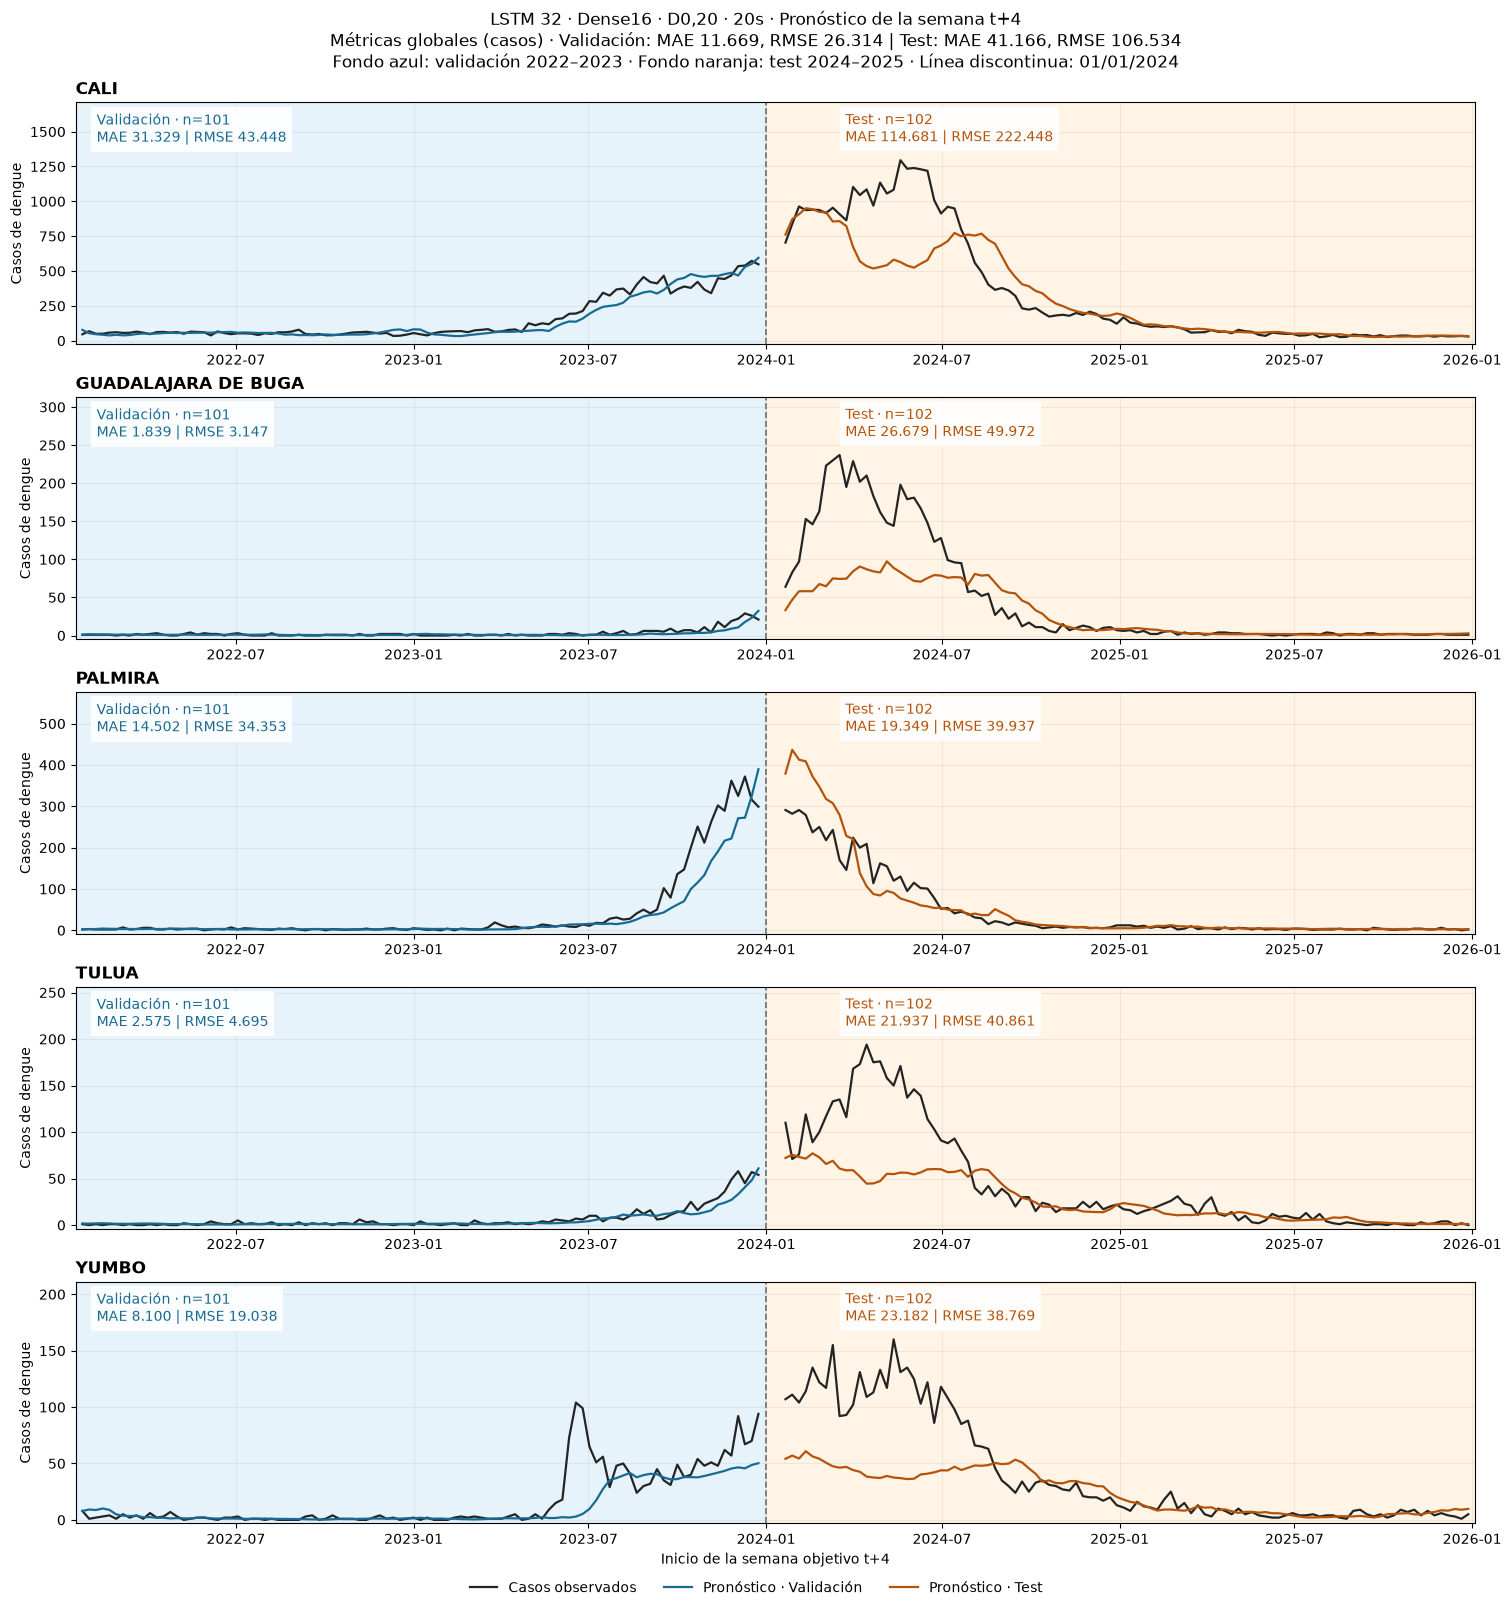

In [2]:
# Reutilizar exclusivamente las predicciones ya calculadas del modelo elegido.
predicciones_validacion_20_6 = predicciones_desarrollo.loc[
    predicciones_desarrollo['ID'].eq(ID_ELEGIDO_AL_CIERRE)
    & predicciones_desarrollo['CONJUNTO'].eq('validation')].copy()
predicciones_test_20_6 = predicciones_evaluacion_cierre.loc[
    predicciones_evaluacion_cierre['ID'].eq(ID_ELEGIDO_AL_CIERRE)].copy()
predicciones_test_20_6['CONJUNTO'] = 'test'
predicciones_modelo_val_test = pd.concat(
    [predicciones_validacion_20_6,predicciones_test_20_6],ignore_index=True)
predicciones_modelo_val_test['FECHA_OBJETIVO'] = pd.to_datetime(predicciones_modelo_val_test['FECHA_OBJETIVO'])
predicciones_modelo_val_test = predicciones_modelo_val_test.sort_values(
    ['COD_DANE','FECHA_OBJETIVO']).reset_index(drop=True)
assert not predicciones_modelo_val_test.duplicated(['COD_DANE','FECHA_OBJETIVO']).any()
assert not predicciones_validacion_20_6.empty and not predicciones_test_20_6.empty

filas_metricas_globales_20_6 = []
for conjunto,grupo in predicciones_modelo_val_test.groupby('CONJUNTO',sort=False):
    errores = grupo['CASOS_PREDICHOS'].to_numpy()-grupo['CASOS_REALES'].to_numpy()
    filas_metricas_globales_20_6.append({'CONJUNTO':conjunto,'N':len(grupo),
        'MAE':np.abs(errores).mean(),'RMSE':np.sqrt(np.mean(errores**2))})
metricas_globales_val_test = pd.DataFrame(filas_metricas_globales_20_6)

filas_metricas_municipales_20_6 = []
for (codigo,municipio,conjunto),grupo in predicciones_modelo_val_test.groupby(
        ['COD_DANE','MUNICIPIO','CONJUNTO'],sort=False,observed=True):
    errores = grupo['CASOS_PREDICHOS'].to_numpy()-grupo['CASOS_REALES'].to_numpy()
    filas_metricas_municipales_20_6.append({'COD_DANE':codigo,'MUNICIPIO':municipio,
        'CONJUNTO':conjunto,'N':len(grupo),'MAE':np.abs(errores).mean(),
        'RMSE':np.sqrt(np.mean(errores**2))})
metricas_municipales_val_test = pd.DataFrame(filas_metricas_municipales_20_6)

# El límite corresponde al comienzo del periodo test, según la semana objetivo.
inicio_periodo_test_20_6 = pd.Timestamp(
    year=predicciones_test_20_6['FECHA_OBJETIVO'].pipe(pd.to_datetime).dt.year.min(),month=1,day=1)
assert predicciones_validacion_20_6['FECHA_OBJETIVO'].pipe(pd.to_datetime).max()<inicio_periodo_test_20_6
fecha_inicial_20_6 = predicciones_modelo_val_test['FECHA_OBJETIVO'].min()-pd.Timedelta(days=7)
fecha_final_20_6 = predicciones_modelo_val_test['FECHA_OBJETIVO'].max()+pd.Timedelta(days=7)
grupos_municipales_20_6 = list(predicciones_modelo_val_test.groupby('COD_DANE',sort=True,observed=True))
figura_modelo_val_test,ejes_modelo_val_test = plt.subplots(
    len(grupos_municipales_20_6),1,figsize=(15,16),sharex=True,constrained_layout=True,squeeze=False)
colores_conjuntos_20_6 = {'validation':'#176B93','test':'#B45309'}

for eje,(codigo,grupo) in zip(ejes_modelo_val_test.ravel(),grupos_municipales_20_6):
    eje.axvspan(fecha_inicial_20_6,inicio_periodo_test_20_6,color='#DCEEF8',alpha=.7,zorder=0)
    eje.axvspan(inicio_periodo_test_20_6,fecha_final_20_6,color='#FFF0DB',alpha=.7,zorder=0)
    eje.axvline(inicio_periodo_test_20_6,color='#666666',linestyle='--',linewidth=1.2,zorder=1)
    for conjunto,x_texto,etiqueta in [('validation',.015,'Validación'),('test',.55,'Test')]:
        datos = grupo.loc[grupo['CONJUNTO'].eq(conjunto)].sort_values('FECHA_OBJETIVO')
        # Dibujar cada conjunto por separado para conservar el intervalo sin pronósticos.
        eje.plot(datos['FECHA_OBJETIVO'],datos['CASOS_ORIGINALES'],
            color='#242424',linewidth=1.6,label='Casos observados' if conjunto=='validation' else '_nolegend_')
        eje.plot(datos['FECHA_OBJETIVO'],datos['CASOS_PREDICHOS'],
            color=colores_conjuntos_20_6[conjunto],linewidth=1.6,label=f'Pronóstico · {etiqueta}')
        resumen = metricas_municipales_val_test.loc[
            metricas_municipales_val_test['COD_DANE'].eq(codigo)
            & metricas_municipales_val_test['CONJUNTO'].eq(conjunto)].iloc[0]
        eje.text(x_texto,.96,
            f"{etiqueta} · n={int(resumen['N'])}\nMAE {resumen['MAE']:.3f} | RMSE {resumen['RMSE']:.3f}",
            transform=eje.transAxes,ha='left',va='top',fontsize=10,
            color=colores_conjuntos_20_6[conjunto],bbox=dict(facecolor='white',edgecolor='none',alpha=.9,pad=4))
    valores = grupo[['CASOS_ORIGINALES','CASOS_PREDICHOS']].to_numpy()
    minimo,maximo = min(0.,valores.min()),valores.max()
    amplitud = max(1.,maximo-minimo)
    eje.set_ylim(minimo-.02*amplitud,maximo+.32*amplitud)
    eje.set_title(grupo['MUNICIPIO'].iloc[0],loc='left',fontweight='bold',fontsize=12)
    eje.set_ylabel('Casos de dengue')
    eje.grid(alpha=.2)
    eje.set_xlim(fecha_inicial_20_6,fecha_final_20_6)
    eje.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    eje.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    eje.tick_params(axis='x',labelbottom=True)

resumen_global_20_6 = metricas_globales_val_test.set_index('CONJUNTO')
global_validacion_20_6,global_test_20_6 = resumen_global_20_6.loc['validation'],resumen_global_20_6.loc['test']
nombre_modelo_20_6 = predicciones_validacion_20_6['MODELO'].iloc[0]
figura_modelo_val_test.suptitle(
    f"{nombre_modelo_20_6} · Pronóstico de la semana t+4\n"
    f"Métricas globales (casos) · Validación: MAE {global_validacion_20_6['MAE']:.3f}, RMSE {global_validacion_20_6['RMSE']:.3f} "
    f"| Test: MAE {global_test_20_6['MAE']:.3f}, RMSE {global_test_20_6['RMSE']:.3f}\n"
    'Fondo azul: validación 2022–2023 · Fondo naranja: test 2024–2025 · Línea discontinua: 01/01/2024',fontsize=12)
ejes_modelo_val_test[-1,0].set_xlabel('Inicio de la semana objetivo t+4')
handles_20_6,labels_20_6 = ejes_modelo_val_test[0,0].get_legend_handles_labels()
figura_modelo_val_test.legend(handles_20_6,labels_20_6,loc='outside lower center',ncol=3,frameon=False)

RUTA_GRAFICA_20_6 = RUTA_EVALUACION_CIERRE/'validacion_test_modelo_elegido'
RUTA_GRAFICA_20_6.mkdir(parents=True,exist_ok=True)
for extension in ['png','svg']:
    figura_modelo_val_test.savefig(RUTA_GRAFICA_20_6/f'modelo_elegido_validacion_test.{extension}',
        dpi=220,bbox_inches='tight')
metricas_globales_val_test.to_csv(RUTA_GRAFICA_20_6/'metricas_globales.csv',index=False,encoding='utf-8-sig')
metricas_municipales_val_test.to_csv(RUTA_GRAFICA_20_6/'metricas_municipales.csv',index=False,encoding='utf-8-sig')
plt.show()
